# Métodos del mapa de investigación

Monitoreo indirecto de puentes con smartphones (*drive-by*): explicación de los **métodos** que aparecen en el mapa de investigación. El notebook sigue el orden del mapa, pero solo contiene información de métodos; solo aparecen los encabezados que ya tienen algún método.

<a id="indice"></a>
## Índice

- [1 Bridge response separation](#bridge-response-separation)
  - [1.1 Road roughness](#road-roughness)
    - [1.1.1 Identical-axle subtraction](#identical-axle-subtraction)
    - [1.1.2 Residual between axles](#residual-between-axles)
  - [1.2 Vehicle dynamics](#vehicle-dynamics)
    - [1.2.1 Contact-point response](#contact-point-response)
- [2 Modal identification](#modal-identification)
  - [2.1 Natural frequencies](#natural-frequencies)
    - [2.1.1 Signal decomposition](#natural-frequencies-signal-decomposition)
      - [2.1.1.1 Autocorrelation](#autocorrelation)
      - [2.1.1.2 Cross-correlation](#cross-correlation)
      - [2.1.1.3 FDD (Frequency Domain Decomposition)](#fdd)
    - [2.1.2 Bridge components](#natural-frequencies-bridge-components)
      - [2.1.2.1 Peaks of 1st singular value](#peaks-first-singular-value)
  - [2.2 Mode shapes](#mode-shapes)
    - [2.2.1 Sparse spatial coverage](#sparse-spatial-coverage)
      - [2.2.1.1 Mapping to fixed points](#mapping-fixed-points)
      - [2.2.1.2 Soft imputing](#soft-imputing)
      - [2.2.1.3 FDD on the incomplete matrix](#fdd-incomplete-matrix)
    - [2.2.2 Signal decomposition](#mode-shapes-signal-decomposition)
      - [2.2.2.1 EMD + Hilbert transform](#emd-hilbert)
      - [2.2.2.2 FDD (Frequency Domain Decomposition)](#fdd-mode-shapes)
      - [2.2.2.3 Wavelet transform (SSWT)](#wavelet-sswt)
    - [2.2.3 Bridge components](#mode-shapes-bridge-components)
      - [2.2.3.1 IMF near the exciter frequency](#imf-exciter-frequency)
      - [2.2.3.2 Peaks of 1st singular value](#peaks-first-singular-value-shapes)
      - [2.2.3.3 Band at the known frequency](#band-known-frequency)
    - [2.2.4 Build the shape along the bridge](#build-shape)
      - [2.2.4.1 Rescaling between axles](#rescaling-between-axles)
      - [2.2.4.2 SVD of the completed matrix](#svd-completed-matrix)
      - [2.2.4.3 Singular vectors at peaks](#singular-vectors-peaks)
      - [2.2.4.4 Average of many trips](#average-many-trips)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ssqueezepy import Wavelet, cwt, ssq_cwt
from ssqueezepy.experimental import scale_to_freq
from PyEMD import EMD
from scipy.interpolate import CubicSpline
from scipy.signal import argrelextrema, hilbert, csd

SEED = 42
rng = np.random.default_rng(SEED)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})


def morlet(t, w0=6.0):
    """Complex Morlet mother wavelet (Eq. 36): oscillation times a Gaussian bell."""
    return np.pi ** -0.25 * np.exp(1j * w0 * t) * np.exp(-t ** 2 / 2)


def scale_for_freq(f, w0=6.0):
    """Scale a whose wavelet oscillates at frequency f in Hz (Eq. 37 solved for a)."""
    return w0 / (2 * np.pi * f)


def scaled_wavelet(t, a, b, w0=6.0):
    """Mother wavelet stretched by scale a and shifted to time b (kernel of Eq. 38)."""
    return morlet((t - b) / a, w0) / np.sqrt(a)


def instantaneous_attributes(c, fs):
    """Envelope A(t) and instantaneous frequency f(t) in Hz of an IMF (Eqs. 34-35)."""
    z = hilbert(c)                      # analytic signal c + i H[c]
    amplitude = np.abs(z)
    phase = np.unwrap(np.angle(z))
    freq = np.gradient(phase) * fs / (2 * np.pi)
    return amplitude, freq


def cross_correlation(xi, xj, max_lag):
    """Biased estimate R_ij(k) = (1/N) sum_n x_i[n] x_j[n+k] for k = -max_lag..max_lag (Eq. 17)."""
    N = xi.size
    lags = np.arange(-max_lag, max_lag + 1)
    R = np.array([np.dot(xi[:N - k], xj[k:]) if k >= 0 else np.dot(xi[-k:], xj[:N + k])
                  for k in lags]) / N
    return lags, R


def modal_response(freqs, zeta, fs, n, rng):
    """Modal coordinates q_k(t), unit RMS: lightly damped modes driven by independent white noise."""
    w = 2 * np.pi * np.fft.rfftfreq(n, 1 / fs)
    q = []
    for fk in freqs:
        wk = 2 * np.pi * fk
        H = 1 / (wk ** 2 - w ** 2 + 2j * zeta * wk * w)          # FRF of one mode: narrow band around f_k
        qk = np.fft.irfft(np.fft.rfft(rng.standard_normal(n)) * H, n)
        q.append(qk / qk.std())
    return np.array(q)


def beam_modes(x_rel, n_modes):
    """Simply supported beam mode shapes sin(k pi x/L) at relative positions x/L (one column per mode)."""
    return np.column_stack([np.sin((k + 1) * np.pi * x_rel) for k in range(n_modes)])


def mac(a, b):
    """Modal Assurance Criterion: 1 = same shape up to a scale factor, 0 = unrelated."""
    return np.abs(np.vdot(a, b)) ** 2 / (np.vdot(a, a).real * np.vdot(b, b).real)


def real_shape(u, ref):
    """Rotate a complex singular vector to be real, scale it to max |value| = 1 and match the sign of ref."""
    u = u * np.exp(-1j * np.angle(u[np.argmax(np.abs(u))]))
    u = u.real / np.max(np.abs(u.real))
    return u if np.dot(u, ref) >= 0 else -u


def road_profile(length, dx, rng, rms=1.0):
    """Smooth random road profile r(x) (illustrative): spectrum ~1/k up to 2 cycles/m, given RMS."""
    x = np.arange(0, length, dx)
    k = np.fft.rfftfreq(x.size, dx)
    R = np.fft.rfft(rng.standard_normal(x.size))
    R[1:] /= np.maximum(k[1:], 0.05)
    R[0] = 0
    R[k > 2] = 0
    r = np.fft.irfft(R, x.size)
    return x, rms * r / r.std()

---

<a id="bridge-response-separation"></a>
## 1 Bridge response separation

---

<a id="road-roughness"></a>
### 1.1 Road roughness

<a id="identical-axle-subtraction"></a>
#### 1.1.1 Identical-axle subtraction

**Qué es**

- Resta las respuestas medidas en dos ejes idénticos de un vehículo para eliminar el efecto de la rugosidad del pavimento.

**Para qué se aplica**

- La rugosidad excita al vehículo en muchas frecuencias, incluso cerca de la del puente, y tapa la respuesta del puente.

**Cómo funciona**

1. Dos ejes idénticos (misma masa, suspensión y llanta) pasan por el mismo perfil de pavimento.
2. Como son iguales, la parte de su respuesta causada por la rugosidad es la misma.
3. Al restar las dos respuestas, esa parte se cancela y queda una señal con información del puente.

$$\ddot{y}_1(t)=\ddot{y}_6(t)-\ddot{y}_4(t),\qquad \ddot{y}_2(t)=\ddot{y}_7(t)-\ddot{y}_5(t) \tag{1}$$

- $\ddot{y}_k(t)$: aceleración medida en el eje $k$ del convoy (ejes 4–5 en el primer remolque, 6–7 en el segundo).
- $\ddot{y}_1(t)$, $\ddot{y}_2(t)$: señales de diferencia.

En palabras: a la señal de un eje del segundo remolque se le resta la del eje equivalente del primero; lo que los dos sienten igual (la rugosidad) desaparece.

- **Observación (propia de esta revisión):** los ejes 4 y 6 van en remolques distintos, así que en un mismo instante están en puntos distintos del pavimento. Para que la rugosidad se cancele, cada señal debe tomarse cuando su eje pasa por el mismo punto, es decir, alinearlas por posición. El artículo escribe la resta sin ese desfase, pero menciona que la resta es sensible a cambios de velocidad y que conviene llevar la señal a la posición, lo que apoya esta lectura. En la gráfica las señales se alinean por posición.

**Ejemplo sintético.** Dos ejes idénticos, separados 5 m, cruzan a 2 m/s una viga de 15 m ($f_b=5.65$ Hz, $\phi=\sin(\pi x/L)$). Cada eje siente la rugosidad (un perfil inventado, filtrado por la dinámica del eje, igual para los dos) más la vibración del puente en el punto donde está.

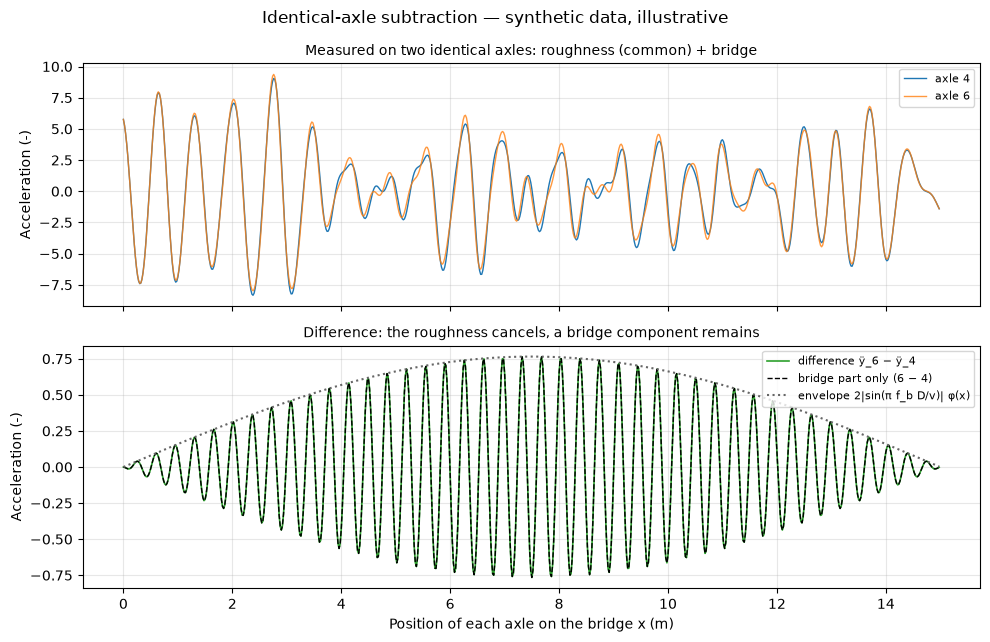

Max |difference - bridge part|: 1.5e-15


In [2]:
# Identical-axle subtraction: two identical axles 5 m apart over the same road (illustrative)
rng_ax = np.random.default_rng(SEED + 10)
L_ax, v_ax, fs_ax = 15.0, 2.0, 100.0          # span (m), speed (m/s), sampling rate (Hz)
f_b_ax = 5.65                                 # bridge frequency, Hz
D_ax = 5.0                                    # distance between axle 4 and axle 6, m
x_ax = np.arange(0, L_ax, v_ax / fs_ax)       # positions on the bridge, m

# Roughness response of one axle as a function of its position: profile filtered by the axle
# dynamics (3 Hz, 10 % damping) at 2 m/s. Identical axles at the same speed -> same function of x.
xr_ax, r_ax = road_profile(60.0, v_ax / fs_ax, rng_ax)
w_ax = 2 * np.pi * np.fft.rfftfreq(xr_ax.size, 1 / fs_ax)
wa = 2 * np.pi * 3.0
H_ax = -w_ax ** 2 * wa ** 2 / (wa ** 2 - w_ax ** 2 + 2j * 0.1 * wa * w_ax)   # axle acceleration FRF
rough_resp = np.fft.irfft(np.fft.rfft(r_ax) * H_ax, xr_ax.size)
rough_resp = 3.0 * rough_resp / rough_resp.std()           # roughness part is 3 times the bridge part
i20 = int(round(20.0 / (v_ax / fs_ax)))
rough_on_bridge = rough_resp[i20:i20 + x_ax.size]   # same piece of road (the bridge) for both axles

# Bridge part seen by each axle at position x: phi(x) cos(2 pi f_b t), t = time the axle is at x
phi_ax = np.sin(np.pi * x_ax / L_ax)
t4 = x_ax / v_ax                              # axle 4 is at x at this time
t6 = (x_ax + D_ax) / v_ax                     # axle 6 reaches the same x D/v = 2.5 s later
bridge4 = phi_ax * np.cos(2 * np.pi * f_b_ax * t4)
bridge6 = phi_ax * np.cos(2 * np.pi * f_b_ax * t6)
acc4 = rough_on_bridge + bridge4              # measured acceleration of axle 4 vs its position
acc6 = rough_on_bridge + bridge6              # measured acceleration of axle 6 vs its position
diff_ax = acc6 - acc4                         # Eq. 1, aligned by position

fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
axes[0].plot(x_ax, acc4, color="C0", lw=1, label="axle 4")
axes[0].plot(x_ax, acc6, color="C1", lw=1, alpha=0.8, label="axle 6")
axes[0].set_ylabel("Acceleration (-)")
axes[0].set_title("Measured on two identical axles: roughness (common) + bridge", fontsize=10)
axes[0].legend(loc="upper right", fontsize=8)
axes[1].plot(x_ax, diff_ax, color="C2", lw=1.2, label="difference ÿ_6 − ÿ_4")
axes[1].plot(x_ax, bridge6 - bridge4, "k--", lw=1, label="bridge part only (6 − 4)")
axes[1].plot(x_ax, 2 * np.abs(np.sin(np.pi * f_b_ax * D_ax / v_ax)) * phi_ax, ":", color="0.4",
             label="envelope 2|sin(π f_b D/v)| φ(x)")
axes[1].set_xlabel("Position of each axle on the bridge x (m)")
axes[1].set_ylabel("Acceleration (-)")
axes[1].set_title("Difference: the roughness cancels, a bridge component remains", fontsize=10)
axes[1].legend(loc="upper right", fontsize=8)
fig.suptitle("Identical-axle subtraction — synthetic data, illustrative")
fig.tight_layout()
plt.show()
print(f"Max |difference - bridge part|: {np.abs(diff_ax - (bridge6 - bridge4)).max():.1e}")

**Figura 1.** Resta entre dos ejes idénticos (ilustrativo, datos sintéticos): arriba, las aceleraciones de los dos ejes contra su posición; la rugosidad, tres veces más grande que el puente, domina y es igual en los dos. Abajo, la diferencia: coincide con la diferencia de las partes del puente (línea discontinua), así que la rugosidad desapareció por completo.

- La parte del puente no se cancela porque cada eje pasa por el mismo punto en un instante distinto (2.5 s después), cuando el puente está en otra fase de su vibración. La amplitud de la diferencia sigue a $\phi(x)$, multiplicada por un factor que depende de $f_b D/v$: la resta cambia la respuesta del puente.

**Cómo se usa en drive-by** (referencia: Malekjafarian y OBrien, 2017)

- Convoy simulado: camión de 3 ejes con dos remolques idénticos (ejes 4–5 y 6–7), a 2 m/s sobre una viga de 15 m, con un excitador a una frecuencia cercana a la del modo buscado.
- Construyen dos señales de diferencia: $\ddot{y}_1=\ddot{y}_6-\ddot{y}_4$ y $\ddot{y}_2=\ddot{y}_7-\ddot{y}_5$ (Ec. 1).
- A esas diferencias les aplican la HHT ([2.2.2.1](#emd-hilbert)) y luego el reescalado ([2.2.4.1](#rescaling-between-axles)).
- Con rugosidad necesitaron una excitación mayor (30 kN).

**Ventajas**

- Elimina la rugosidad sin necesidad de conocer el perfil del pavimento.
- Es una operación muy simple.

**Desventajas**

- Requiere ejes idénticos y que sigan exactamente la misma huella.
- Solo se ha validado numéricamente (lo dice el artículo).
- La diferencia también cambia la respuesta del puente, porque los ejes están en posiciones distintas.

**Artículos:** Malekjafarian y OBrien (2017).

> **Nota de fuentes.** Del artículo vienen: el concepto de restar las respuestas de dos ejes idénticos, las diferencias ÿ₆ − ÿ₄ y ÿ₇ − ÿ₅, el convoy con dos remolques y la falta de validación experimental. La explicación de por qué se cancela la rugosidad es una explicación general.

**Entradas y salidas**

- **Entrada:** las aceleraciones medidas en dos ejes idénticos que pasan por el mismo carril.
- **Salida:** una señal de diferencia sin el efecto de la rugosidad.
- **Qué se obtiene o interpreta:** una señal donde la respuesta del puente ya no está tapada por el pavimento, lista para descomponerse (por ejemplo, con EMD + Hilbert, [2.2.2.1](#emd-hilbert)).

[↑ Volver al índice](#indice)

<a id="residual-between-axles"></a>
#### 1.1.2 Residual between axles

**Qué es**

- Resta la respuesta del eje trasero en el instante $t$ menos la del eje delantero en el instante $t-\Delta t$, cuando el delantero estaba en el mismo punto del pavimento.

**Para qué se aplica**

- Para eliminar la rugosidad usando los dos ejes de un mismo vehículo, sin necesitar ejes idénticos.

**Cómo funciona**

1. El eje trasero pasa por el mismo punto que el delantero, pero $\Delta t$ después.
2. Los dos ejes "ven" la misma rugosidad en ese punto, así que al restarlos se cancela.
3. Lo que queda (la respuesta residual) es cuánto cambió el puente en ese punto durante $\Delta t$.
4. Dividir la velocidad residual entre $\Delta t$ da una aproximación de la aceleración del puente.

*Respuesta residual* (ec. 13 del artículo).

$$\Delta u_{cr}(t)=u_{cr}(t)-u_{cf}(t-\Delta t)=\Delta u_{mr}(t) \tag{2}$$

- $u_{cr}(t)$, $u_{cf}(t)$: respuesta de punto de contacto ([1.2.1](#contact-point-response)) del eje trasero y del delantero.
- $\Delta u_{cr}(t)$: respuesta residual en el eje trasero.
- $\Delta u_{mr}(t)$: respuesta residual del puente en el punto donde está el eje trasero: lo que cambió la respuesta del puente en ese punto entre $t-\Delta t$ y $t$.

En palabras: se compara lo que mide el eje trasero con lo que midió el delantero cuando pisó el mismo punto; la rugosidad es la misma y se cancela, y solo queda el cambio del puente.

*El retraso.*

$$\Delta t=\frac{d}{v}=\frac{3}{25}=0.12\ \text{s} \tag{3}$$

- $d$: distancia entre ejes, en m.
- $v$: velocidad del vehículo, en m/s.

En palabras: es el tiempo que tarda el eje trasero en llegar al punto por donde ya pasó el delantero.

**Ejemplo sintético.** Un vehículo de dos ejes ($d=3$ m) cruza a 25 m/s una viga de 100 m. La respuesta en cada punto de contacto es la rugosidad (perfil inventado) más la respuesta del puente bajo la llanta, $\phi(x)\,q(t)$, con el modo 1 a 1.44 Hz.

dt = d/v = 0.12 s (24 samples)
Max |residual - true bridge change|: 8.3e-16


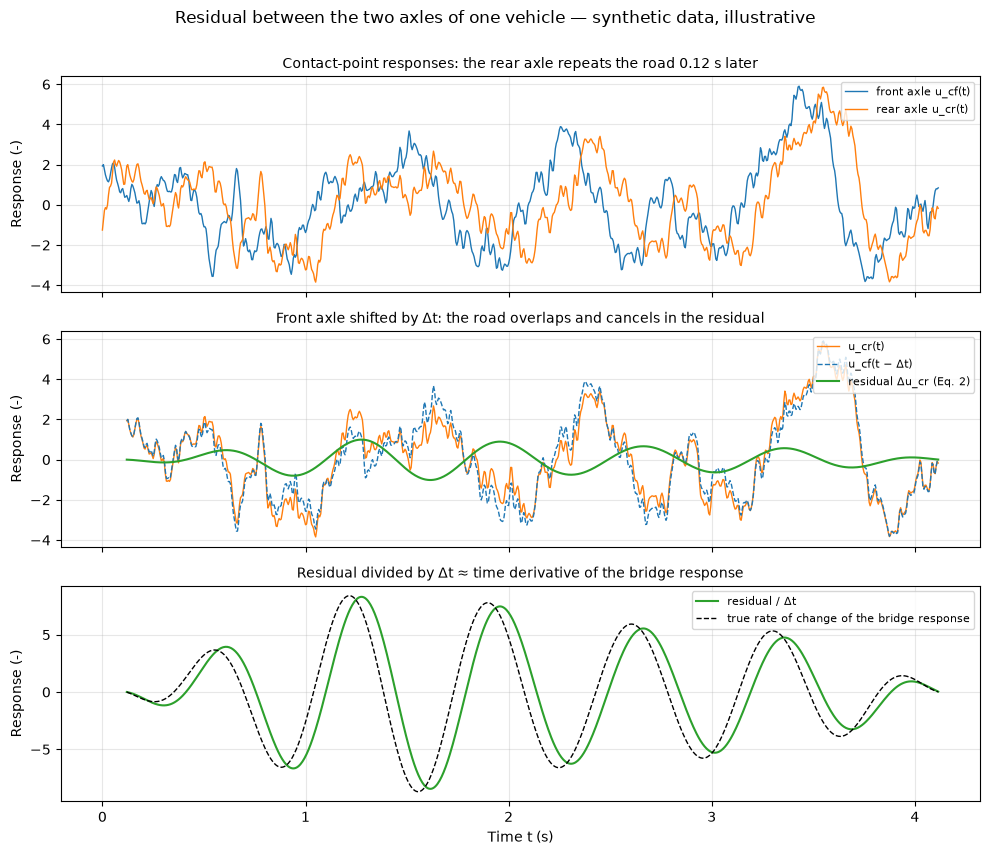

In [3]:
# Residual between axles: rear axle at t minus front axle at t - dt (illustrative)
rng_res = np.random.default_rng(SEED + 11)
L_r, v_r, d_r, fs_r = 100.0, 25.0, 3.0, 200.0    # span (m), speed (m/s), wheelbase (m), sampling (Hz)
dt_r = d_r / v_r                                 # Eq. 3: 0.12 s
k_dt = int(round(dt_r * fs_r))                   # delay in samples (24)
t_r = np.arange(0, (L_r + d_r) / v_r, 1 / fs_r)  # from front axle entering to rear axle leaving
x_front = v_r * t_r                              # front axle position, m
x_rear = x_front - d_r                           # rear axle position, m

xp_r, prof_r = road_profile(200.0, 0.01, rng_res, rms=2.0)   # road seen at the contact points
q_r = np.cos(2 * np.pi * 1.44 * t_r) * (1 + 0.3 * np.sin(2 * np.pi * 0.3 * t_r))   # bridge modal coordinate (mode 1)
def bridge_r(x):
    """Bridge response under a wheel at position x (zero off the bridge)."""
    return np.where((x >= 0) & (x <= L_r), np.sin(np.pi * np.clip(x, 0, L_r) / L_r), 0.0) * q_r

u_cf = np.interp(x_front + 50, xp_r, prof_r) + bridge_r(x_front)   # front contact point
u_cr = np.interp(x_rear + 50, xp_r, prof_r) + bridge_r(x_rear)     # rear contact point (same road, dt later)

valid = np.arange(k_dt, t_r.size)                  # instants where t - dt exists
u_cf_shift = u_cf[valid - k_dt]                    # u_cf(t - dt)
residual = u_cr[valid] - u_cf_shift                # Eq. 2
phi_rear = np.where((x_rear >= 0) & (x_rear <= L_r), np.sin(np.pi * np.clip(x_rear, 0, L_r) / L_r), 0.0)
true_change = phi_rear[valid] * (q_r[valid] - q_r[valid - k_dt])   # what the bridge changed in dt
true_rate = phi_rear[valid] * np.gradient(q_r, 1 / fs_r)[valid]   # time derivative of the bridge response
print(f"dt = d/v = {dt_r:.2f} s ({k_dt} samples)")
print(f"Max |residual - true bridge change|: {np.abs(residual - true_change).max():.1e}")

fig, axes = plt.subplots(3, 1, figsize=(10, 8.5), sharex=True)
axes[0].plot(t_r, u_cf, color="C0", lw=1, label="front axle u_cf(t)")
axes[0].plot(t_r, u_cr, color="C1", lw=1, label="rear axle u_cr(t)")
axes[0].set_title("Contact-point responses: the rear axle repeats the road 0.12 s later", fontsize=10)
axes[0].legend(loc="upper right", fontsize=8)
axes[1].plot(t_r[valid], u_cr[valid], color="C1", lw=1, label="u_cr(t)")
axes[1].plot(t_r[valid], u_cf_shift, "--", color="C0", lw=1, label="u_cf(t − Δt)")
axes[1].plot(t_r[valid], residual, color="C2", lw=1.5, label="residual Δu_cr (Eq. 2)")
axes[1].set_title("Front axle shifted by Δt: the road overlaps and cancels in the residual", fontsize=10)
axes[1].legend(loc="upper right", fontsize=8)
axes[2].plot(t_r[valid], residual / dt_r, color="C2", lw=1.5, label="residual / Δt")
axes[2].plot(t_r[valid], true_rate, "k--", lw=1, label="true rate of change of the bridge response")
axes[2].set_title("Residual divided by Δt ≈ time derivative of the bridge response", fontsize=10)
axes[2].legend(loc="upper right", fontsize=8)
for ax in axes:
    ax.set_ylabel("Response (-)")
axes[-1].set_xlabel("Time t (s)")
fig.suptitle("Residual between the two axles of one vehicle — synthetic data, illustrative", y=1.0)
fig.tight_layout()
plt.show()

**Figura 2.** Respuesta residual entre los dos ejes de un vehículo (ilustrativo, datos sintéticos): arriba, la rugosidad domina las dos señales y el eje trasero la repite 0.12 s después. En medio, al correr la señal del eje delantero $\Delta t$, la rugosidad de las dos coincide y la resta (verde) ya no tiene sus saltos: lo que queda es el cambio del puente en 0.12 s. Abajo, la residual dividida entre $\Delta t$ sigue la derivada de la respuesta del puente, con un pequeño retraso y algo menos de amplitud, porque es una diferencia en un intervalo de 0.12 s y no una derivada exacta.

**Cómo se usa en drive-by** (referencia: Talebi-Kalaleh et al., 2025)

- Se aplica en la respuesta de punto de contacto ([1.2.1](#contact-point-response)), no en la del cuerpo del vehículo.
- Distancia entre ejes $d=3$ m y $v=25$ m/s, por lo que $\Delta t=0.12$ s (Ec. 3).
- La velocidad residual dividida entre $\Delta t$ se mapea luego a los puntos fijos ([2.2.1.1](#mapping-fixed-points)).

**Ventajas**

- Cancela la rugosidad con un solo vehículo, sin conocer el perfil.

**Desventajas**

- Necesita conocer la distancia entre ejes y la velocidad ($\Delta t$), y suponer que el vehículo sigue la misma huella.
- Lo que se obtiene es una diferencia en el tiempo, no la respuesta directa del puente; la división entre $\Delta t$ es una aproximación.
- El artículo no explica de dónde sale la velocidad de los ejes.

**Artículos:** Talebi-Kalaleh et al. (2025).

> **Nota de fuentes.** Del artículo vienen: la ec. 13, Δt = d/v, d = 3 m, v = 25 m/s y el uso de la velocidad residual dividida entre Δt (ec. 30). Nota: el artículo escribe Δt = v/d, que es una errata.

**Entradas y salidas**

- **Entrada:** la respuesta de punto de contacto de los dos ejes, la distancia entre ejes y la velocidad.
- **Salida:** la respuesta residual en el eje trasero.
- **Qué se obtiene o interpreta:** un cambio de la respuesta del puente libre de rugosidad, que dividido entre $\Delta t$ aproxima la aceleración del puente.

[↑ Volver al índice](#indice)

---

<a id="vehicle-dynamics"></a>
### 1.2 Vehicle dynamics

<a id="contact-point-response"></a>
#### 1.2.1 Contact-point response

**Qué es**

- Pasa la señal medida en el cuerpo del vehículo a la respuesta en los puntos donde las llantas tocan el pavimento, usando un modelo dinámico del vehículo.

**Para qué se aplica**

- El cuerpo del vehículo filtra y deforma la señal con su suspensión; la respuesta en el punto de contacto no tiene la dinámica del vehículo.

**Cómo funciona**

1. El sensor mide el desplazamiento vertical y la rotación (*pitch*, cabeceo) del cuerpo en su ubicación.
2. Suponiendo el cuerpo rígido, se pasan esas mediciones al centro de gravedad con una matriz de transformación.
3. Con la ecuación de movimiento del modelo de medio carro (masa, inercia, rigidez y amortiguamiento de suspensión), se despeja la entrada: la respuesta en los puntos de contacto delantero y trasero.

*Del sensor al centro de gravedad* (ecs. 1–2 del artículo).

$$\mathbf{y}(t)=\mathbf{T}\,\mathbf{y}_s(t),\qquad \mathbf{T}=\begin{bmatrix}1 & -(e_f-e_s)\\ 0 & 1\end{bmatrix} \tag{4}$$

- $\mathbf{y}_s(t)$: desplazamiento vertical y *pitch* del cuerpo medidos en el sensor.
- $\mathbf{y}(t)$: desplazamiento vertical y *pitch* en el centro de gravedad.
- $e_f$: distancia del eje delantero al centro de gravedad.
- $e_s$: distancia del eje delantero al sensor.

En palabras: como el cuerpo es rígido, el centro de gravedad se mueve como el sensor menos lo que agrega la rotación en la distancia que los separa, $e_f-e_s$.

*Ecuación de movimiento del medio carro* (ec. 3 del artículo).

$$\mathbf{M}\ddot{\mathbf{y}}+\mathbf{C}\dot{\mathbf{y}}+\mathbf{K}\mathbf{y}=\mathbf{B}_k\,\mathbf{u}_c(t)+\mathbf{B}_c\,\dot{\mathbf{u}}_c(t) \tag{5}$$

- $\mathbf{M}$, $\mathbf{C}$, $\mathbf{K}$: matrices de masa (masa e inercia de cabeceo), amortiguamiento y rigidez de la suspensión.
- $\mathbf{y}$, $\dot{\mathbf{y}}$, $\ddot{\mathbf{y}}$: desplazamiento, velocidad y aceleración en el centro de gravedad (Ec. 4).
- $\mathbf{u}_c(t)$: respuesta en los puntos de contacto trasero y delantero (la entrada que se busca).
- $\mathbf{B}_k$, $\mathbf{B}_c$: matrices de efecto de la carga: cómo empujan los resortes y amortiguadores al cuerpo.

En palabras: el movimiento del cuerpo es la respuesta de la suspensión a lo que pasa bajo las llantas. Si se mide el movimiento del cuerpo y se conocen $\mathbf{M}$, $\mathbf{C}$ y $\mathbf{K}$, el lado izquierdo es conocido y se puede despejar $\mathbf{u}_c$.

- En el ejemplo la ecuación se despeja en el dominio de la frecuencia: $\mathbf{U}_c(\omega)=(\mathbf{B}_k+i\omega\mathbf{B}_c)^{-1}(\mathbf{K}-\omega^2\mathbf{M}+i\omega\mathbf{C})\,\mathbf{Y}(\omega)$. Es una forma de hacerlo; el artículo remite la derivación a sus referencias.

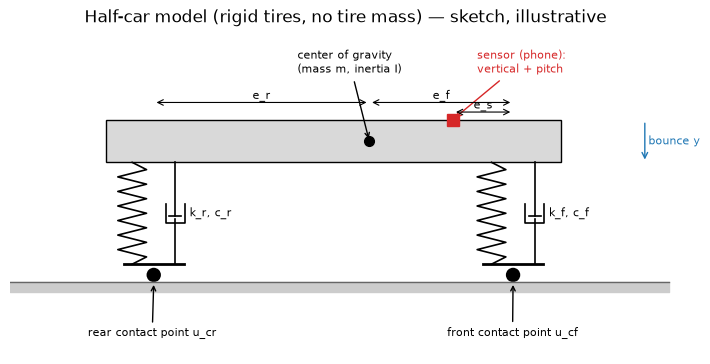

In [4]:
# Half-car sketch: body, sensor, center of gravity, suspensions and contact points (illustrative)
from matplotlib.patches import Rectangle, Circle

def spring(ax, x, y0, y1, n=6, w=0.12, color="k"):
    """Zig-zag spring between heights y0 and y1 at horizontal position x."""
    ys = np.linspace(y0, y1, 2 * n + 3)
    xs = np.r_[x, x + w * np.tile([1, -1], n + 1)[:2 * n + 1], x]
    ax.plot(xs, ys, color=color, lw=1.2)

def damper(ax, x, y0, y1, color="k"):
    """Dashpot between heights y0 and y1 at horizontal position x."""
    ym = (y0 + y1) / 2
    ax.plot([x, x], [y0, ym - 0.05], color=color, lw=1.2)
    ax.plot([x - 0.08, x - 0.08, x + 0.08, x + 0.08], [ym + 0.08, ym - 0.08, ym - 0.08, ym + 0.08], color=color, lw=1.2)
    ax.plot([x, x], [ym - 0.02, y1], color=color, lw=1.2)
    ax.plot([x - 0.05, x + 0.05], [ym - 0.02, ym - 0.02], color=color, lw=1.2)

e_f, e_r, e_s = 1.2, 1.8, 0.5                  # front axle-CG, CG-rear axle, front axle-sensor (m)
x_cg = 0.0
x_fa, x_ra, x_s = x_cg + e_f, x_cg - e_r, x_cg + e_f - e_s
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.add_patch(Rectangle((x_ra - 0.4, 1.0), (x_fa - x_ra) + 0.8, 0.35, fc="0.85", ec="k"))
ax.plot(x_cg, 1.175, "ko", ms=7)
ax.annotate("center of gravity\n(mass m, inertia I)", (x_cg, 1.175), xytext=(x_cg - 0.6, 1.75), fontsize=8,
            arrowprops=dict(arrowstyle="->"))
ax.plot(x_s, 1.35, "s", color="C3", ms=9)
ax.annotate("sensor (phone):\nvertical + pitch", (x_s, 1.36), xytext=(x_s + 0.2, 1.75), fontsize=8, color="C3",
            arrowprops=dict(arrowstyle="->", color="C3"))
for xa, name in [(x_fa, "front"), (x_ra, "rear")]:
    spring(ax, xa - 0.18, 0.15, 1.0)
    damper(ax, xa + 0.18, 0.15, 1.0)
    ax.plot([xa - 0.25, xa + 0.25], [0.15, 0.15], "k", lw=2)
    ax.add_patch(Circle((xa, 0.06), 0.06, fc="k"))
    ax.annotate(f"{name} contact point u_c{name[0]}", (xa, 0.0), xytext=(xa - 0.55, -0.45), fontsize=8,
                arrowprops=dict(arrowstyle="->"))
ax.text(x_fa + 0.3, 0.55, "k_f, c_f", fontsize=8)
ax.text(x_ra + 0.3, 0.55, "k_r, c_r", fontsize=8)
ax.plot([-3, 2.5], [0, 0], color="0.4", lw=1)
ax.fill_between([-3, 2.5], -0.08, 0, color="0.8")
for xa, xb, yy, label in [(x_cg, x_fa, 1.5, "e_f"), (x_s, x_fa, 1.42, "e_s"), (x_ra, x_cg, 1.5, "e_r")]:
    ax.annotate("", (xa, yy), (xb, yy), arrowprops=dict(arrowstyle="<->", lw=0.8))
    ax.text((xa + xb) / 2, yy + 0.03, label, ha="center", fontsize=8)
ax.annotate("", (2.3, 1.0), (2.3, 1.35), arrowprops=dict(arrowstyle="->", color="C0"))
ax.text(2.33, 1.15, "bounce y", fontsize=8, color="C0")
ax.set_xlim(-3, 2.6)
ax.set_ylim(-0.6, 2.1)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Half-car model (rigid tires, no tire mass) — sketch, illustrative")
plt.show()

**Figura 3.** Esquema del modelo de medio carro (ilustrativo): el cuerpo rígido, con su centro de gravedad, apoyado en dos suspensiones (resorte $k$ y amortiguador $c$). El sensor va sobre el cuerpo, a $e_s$ del eje delantero, y mide el desplazamiento vertical y el *pitch*. Las llantas son rígidas y sin masa, así que el extremo inferior de cada suspensión sigue exactamente al punto de contacto.

**Ejemplo sintético.** El medio carro de la Figura 3 ($m=1500$ kg, $I=2000$ kg·m², $k=200$ kN/m y $c=2$ kN·s/m en cada eje; frecuencias propias de 2.5 y 3.5 Hz) cruza a 25 m/s una viga de 100 m. En cada punto de contacto entra la rugosidad más la deflexión del puente (con una oscilación de 1.44 Hz). Se calcula el movimiento del cuerpo en el sensor y luego se despeja la entrada con las Ecs. 4 y 5. Los valores del vehículo son inventados.

Vehicle frequencies (Hz): [2.49 3.52]
Max |recovered - true| front contact point: 1.3e-06 m


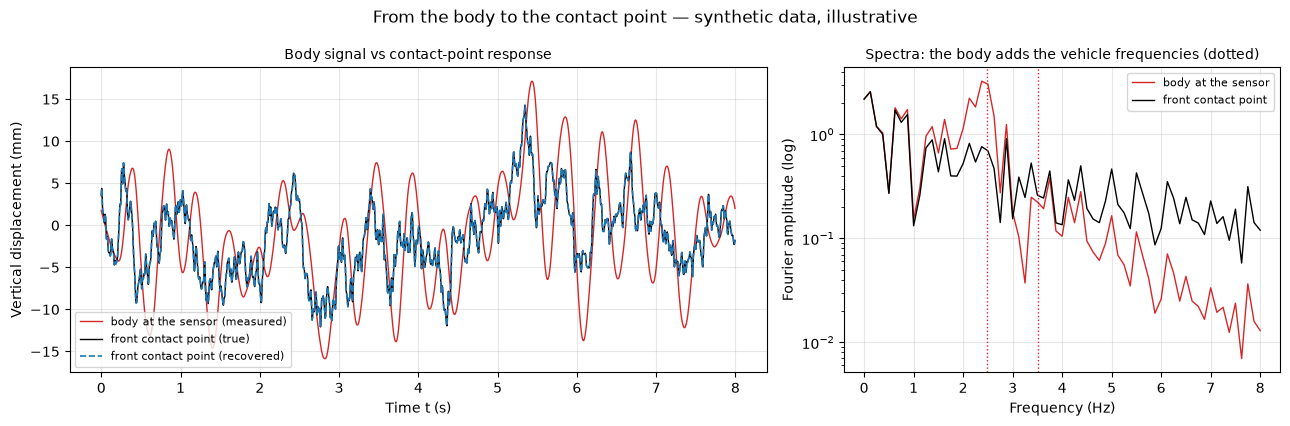

In [5]:
# Contact-point response from the body response of a half-car (illustrative)
rng_hc = np.random.default_rng(SEED + 12)
m_hc, I_hc = 1500.0, 2000.0                     # body mass (kg) and pitch inertia (kg m^2)
k_hc, c_hc = 2.0e5, 2.0e3                       # suspension stiffness (N/m) and damping (N s/m), each axle
M_hc = np.diag([m_hc, I_hc])
K_hc = k_hc * np.array([[2, e_f - e_r], [e_f - e_r, e_f ** 2 + e_r ** 2]])
C_hc = c_hc * np.array([[2, e_f - e_r], [e_f - e_r, e_f ** 2 + e_r ** 2]])
Bk_hc = k_hc * np.array([[1, 1], [-e_r, e_f]])  # columns: rear, front contact point
Bc_hc = c_hc * np.array([[1, 1], [-e_r, e_f]])
T_hc = np.array([[1, -(e_f - e_s)], [0, 1]])    # Eq. 4: sensor -> center of gravity
f_veh = np.sqrt(np.linalg.eigvals(np.linalg.solve(M_hc, K_hc)).real) / (2 * np.pi)
print("Vehicle frequencies (Hz):", np.round(np.sort(f_veh), 2))

fs_hc, v_hc, L_hc = 200.0, 25.0, 100.0
t_hc = np.arange(0, 8, 1 / fs_hc)
x_f_hc = v_hc * t_hc - 10.0                      # front axle position (enters the bridge at t = 0.4 s)
x_r_hc = x_f_hc - (e_f + e_r)                    # rear axle position
xp_hc, prof_hc = road_profile(300.0, 0.05, rng_hc, rms=0.004)
def contact_input(x):
    """Road profile plus bridge deflection under a wheel at x (m)."""
    on = (x >= 0) & (x <= L_hc)
    defl = -0.003 * np.sin(np.pi * np.clip(x, 0, L_hc) / L_hc) * (1 + 0.3 * np.cos(2 * np.pi * 1.44 * t_hc))
    return np.interp(x + 50, xp_hc, prof_hc) + np.where(on, defl, 0.0)
u_c = np.vstack([contact_input(x_r_hc), contact_input(x_f_hc)])   # [rear, front], m

w_hc = 2 * np.pi * np.fft.rfftfreq(t_hc.size, 1 / fs_hc)
Uc = np.fft.rfft(u_c, axis=1)
Y = np.array([np.linalg.solve(K_hc - w ** 2 * M_hc + 1j * w * C_hc, (Bk_hc + 1j * w * Bc_hc) @ Uc[:, i])
              for i, w in enumerate(w_hc)]).T                                   # Eq. 5 solved for y
y_sensor = np.linalg.solve(T_hc, np.fft.irfft(Y, t_hc.size, axis=1))            # what the sensor measures

# Inverse: sensor -> center of gravity (Eq. 4) -> contact points (Eq. 5 solved for u_c)
Q_hc = T_hc @ np.fft.rfft(y_sensor, axis=1)
Uc_est = np.array([np.linalg.solve(Bk_hc + 1j * w * Bc_hc, (K_hc - w ** 2 * M_hc + 1j * w * C_hc) @ Q_hc[:, i])
                   for i, w in enumerate(w_hc)]).T
u_c_est = np.fft.irfft(Uc_est, t_hc.size, axis=1)
print(f"Max |recovered - true| front contact point: {np.abs(u_c_est[1] - u_c[1]).max():.1e} m")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].plot(t_hc, 1e3 * y_sensor[0], color="C3", lw=1, label="body at the sensor (measured)")
axes[0].plot(t_hc, 1e3 * u_c[1], color="k", lw=1, label="front contact point (true)")
axes[0].plot(t_hc, 1e3 * u_c_est[1], "--", color="C0", lw=1.2, label="front contact point (recovered)")
axes[0].set_xlabel("Time t (s)")
axes[0].set_ylabel("Vertical displacement (mm)")
axes[0].set_title("Body signal vs contact-point response", fontsize=10)
axes[0].legend(loc="lower left", fontsize=8)
f_sp = np.fft.rfftfreq(t_hc.size, 1 / fs_hc)
keep = f_sp <= 8
axes[1].semilogy(f_sp[keep], np.abs(np.fft.rfft(y_sensor[0]))[keep], color="C3", lw=1, label="body at the sensor")
axes[1].semilogy(f_sp[keep], np.abs(np.fft.rfft(u_c[1]))[keep], color="k", lw=1, label="front contact point")
for fv in f_veh:
    axes[1].axvline(fv, color="C3", ls=":", lw=1)
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Fourier amplitude (log)")
axes[1].set_title("Spectra: the body adds the vehicle frequencies (dotted)", fontsize=10)
axes[1].legend(loc="upper right", fontsize=8)
fig.suptitle("From the body to the contact point — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 4.** Señal en el cuerpo del vehículo contra la respuesta en el punto de contacto delantero (ilustrativo, datos sintéticos). A la izquierda, en el tiempo: la señal del sensor (rojo) tiene encima las oscilaciones del vehículo; la respuesta recuperada con las Ecs. 4 y 5 (azul, discontinua) coincide con la verdadera (negro). A la derecha, en frecuencia: el cuerpo amplifica la señal cerca de las frecuencias propias del vehículo (2.5 y 3.5 Hz, líneas punteadas), que no están en el punto de contacto.

- La recuperación es exacta porque el modelo usado para despejar es el mismo que generó los datos y no hay ruido. Con un vehículo real, el error depende de qué tan bien se conozcan $\mathbf{M}$, $\mathbf{C}$ y $\mathbf{K}$.
- En la práctica el teléfono mide aceleración y velocidad angular, no desplazamiento; hay que integrarlas o escribir las Ecs. 4 y 5 en aceleración.

**Cómo se usa en drive-by** (referencia: Talebi-Kalaleh et al., 2025)

- Modelo de medio carro con llantas rígidas y sin masa de llanta.
- Propiedades de los vehículos conocidas (30 vehículos con propiedades entre 70 % y 130 % de un vehículo base).
- La salida alimenta la respuesta residual ([1.1.2](#residual-between-axles)).

**Ventajas**

- Elimina la dinámica del vehículo de la señal.
- Permite usar vehículos distintos, cada uno con su modelo.

**Desventajas**

- Hay que conocer las propiedades de cada vehículo.
- Depende de que el modelo de medio carro represente bien al vehículo real.
- Necesita medir también el *pitch*.

**Artículos:** Talebi-Kalaleh et al. (2025).

> **Nota de fuentes.** Del artículo vienen: el modelo de medio carro, las ecs. 1 a 3 y el uso de propiedades conocidas. El paso de despejar la entrada se describe de forma general; los detalles de la derivación están en las referencias [36, 37] del artículo.

**Entradas y salidas**

- **Entrada:** desplazamiento (o aceleración) vertical y *pitch* del cuerpo en el sensor, y las propiedades del vehículo.
- **Salida:** la respuesta en los puntos de contacto delantero y trasero.
- **Qué se obtiene o interpreta:** una señal sin la dinámica del vehículo, que contiene la respuesta del puente más la rugosidad.

[↑ Volver al índice](#indice)

---

<a id="modal-identification"></a>
## 2 Modal identification

*Damping (amortiguamiento): rama pendiente del mapa. La estimación del amortiguamiento a partir de la autocorrelación se explica en [2.1.1.1](#autocorrelation).*

---

<a id="natural-frequencies"></a>
### 2.1 Natural frequencies

<a id="natural-frequencies-signal-decomposition"></a>
#### 2.1.1 Signal decomposition

<a id="autocorrelation"></a>
##### 2.1.1.1 Autocorrelation

*No aparece en el mapa; se explica aquí porque es la base de la correlación cruzada (2.1.1.2) y de la PSD que usa el FDD (2.1.1.3).*

**Qué es**

- La autocorrelación mide cuánto se parece una señal a una copia de sí misma desplazada en el tiempo un desfase $\tau$ (*lag*).
- Es el caso particular de la correlación cruzada ([2.1.1.2](#cross-correlation)) en el que las dos señales son la misma.

**Para qué se aplica**

- Detectar periodicidad (el periodo) en una señal aunque esté tapada por ruido.
- Rechazar ruido blanco independiente.
- Identificar frecuencia natural y amortiguamiento a partir de vibración ambiental, sin medir la fuerza de entrada.
- Es el punto de partida de la PSD (*power spectral density*, densidad espectral de potencia): su transformada de Fourier es la PSD.

**Cómo funciona**

*1. Definición y estimador.*

$$R_{xx}(\tau)=E\left[x(t)\,x(t+\tau)\right] \tag{6}$$

- $R_{xx}(\tau)$: autocorrelación en el desfase $\tau$.
- $x(t)$: señal, con la media removida.
- $\tau$: desfase, en s.
- $E[\cdot]$: valor esperado (promedio).

En palabras: calcula el parecido promedio entre la señal y su copia desplazada $\tau$.

$$\hat{R}_{xx}[k]=\frac{1}{N}\sum_{n=0}^{N-1-k}x[n]\,x[n+k] \tag{7}$$

- $N$: número de muestras.
- $k$: desfase en muestras ($\tau=k/f_s$, con $f_s$ la frecuencia de muestreo).
- $x[n]$: muestra $n$.

En palabras: es la versión discreta que se calcula con datos medidos; para cada $k$ se suman los productos de las muestras que se traslapan y se divide entre $N$.

$$\rho_{xx}(\tau)=\frac{R_{xx}(\tau)}{R_{xx}(0)} \tag{8}$$

- $\rho_{xx}(\tau)$: autocorrelación normalizada, entre $-1$ y $1$.

En palabras: divide entre el valor en $\tau=0$ para que el parecido no dependa del tamaño de la señal.

*2. Propiedades.* Es simétrica respecto a $\tau=0$; su máximo está en $\tau=0$; en $\tau=0$ vale la varianza de la señal (si la media es cero); decae con el desfase si el contenido es de banda ancha y **no** decae si el contenido es periódico.

$$R_{xx}(0)=\sigma_x^2,\qquad R_{xx}(-\tau)=R_{xx}(\tau),\qquad |R_{xx}(\tau)|\le R_{xx}(0) \tag{9}$$

- $\sigma_x^2$: varianza de $x$.

En palabras: en desfase cero la señal coincide consigo misma y el parecido es el máximo posible, igual a su varianza; correr la copia hacia adelante o hacia atrás da lo mismo.

*3. Detección del periodo.* Una señal periódica enterrada en ruido muestra en su autocorrelación picos repetidos separados exactamente por su periodo $T$. Estimar $T$ con varias separaciones entre picos (no con una sola) mejora la precisión.

**Ejemplo sintético.** Un seno de 2 Hz ($T=0.5$ s) más ruido blanco con una varianza ocho veces mayor que la del seno; 60 s a 100 Hz.

SNR = -9.0 dB; 6 peaks; estimated period T = 0.492 s (true 0.500 s)


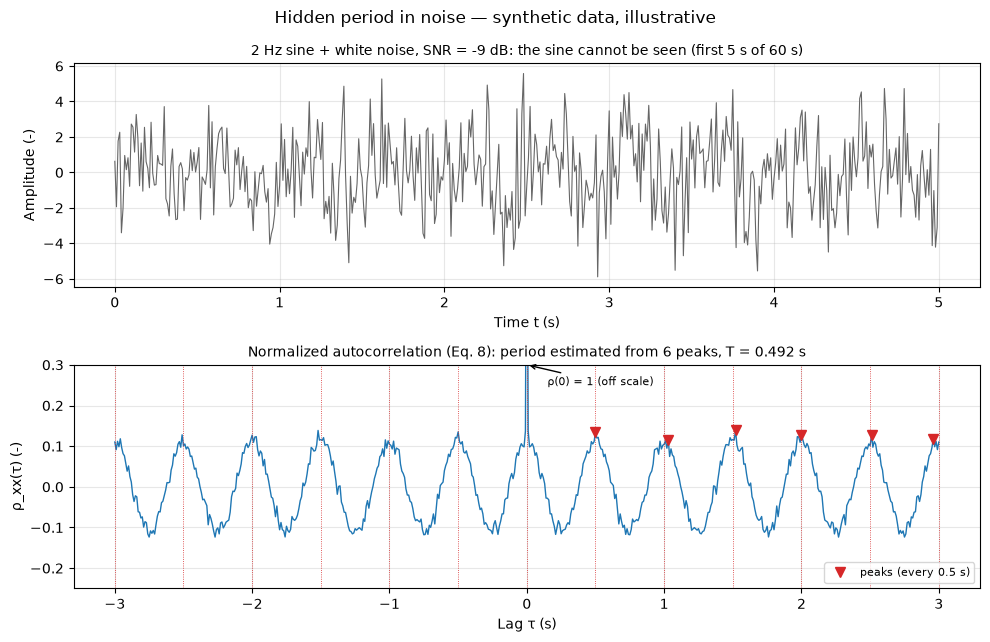

In [6]:
# Hidden period: 2 Hz sine buried in white noise and its normalized autocorrelation (illustrative)
from scipy.signal import find_peaks, lsim
rng_ac = np.random.default_rng(SEED)            # SEED = 42
fs_ac = 100.0                                   # sampling rate, Hz
t_ac = np.arange(0, 60, 1 / fs_ac)              # 60 s
sine_ac = np.sin(2 * np.pi * 2.0 * t_ac)        # 2 Hz sine, period 0.5 s
y_ac = sine_ac + 2.0 * rng_ac.standard_normal(t_ac.size)
y_ac -= y_ac.mean()
snr_db = 10 * np.log10(np.var(sine_ac) / (2.0 ** 2))

lags_ac, R_ac = cross_correlation(y_ac, y_ac, max_lag=int(3 * fs_ac))   # Eq. 7 (x = y)
rho_ac = R_ac / R_ac[lags_ac == 0][0]                                    # Eq. 8
tau_ac = lags_ac / fs_ac
first_zero = tau_ac[(tau_ac > 0) & (rho_ac < 0)][0]   # skip the tail of the zero-lag spike
pos = tau_ac > first_zero
pk, _ = find_peaks(rho_ac[pos], height=0.06, distance=int(0.3 * fs_ac))
tau_pk = tau_ac[pos][pk]
T_est = np.polyfit(np.arange(1, tau_pk.size + 1), tau_pk, 1)[0]          # several peak separations
print(f"SNR = {snr_db:.1f} dB; {tau_pk.size} peaks; estimated period T = {T_est:.3f} s (true 0.500 s)")

fig, axes = plt.subplots(2, 1, figsize=(10, 6.5))
show = t_ac <= 5
axes[0].plot(t_ac[show], y_ac[show], color="0.4", lw=0.8)
axes[0].set_xlabel("Time t (s)")
axes[0].set_ylabel("Amplitude (-)")
axes[0].set_title(f"2 Hz sine + white noise, SNR = {snr_db:.0f} dB: the sine cannot be seen (first 5 s of 60 s)",
                  fontsize=10)
axes[1].plot(tau_ac, rho_ac, color="C0", lw=1)
axes[1].plot(tau_pk, rho_ac[pos][pk], "v", color="C3", ms=7, label="peaks (every 0.5 s)")
for k in range(-6, 7):
    axes[1].axvline(0.5 * k, color="C3", ls=":", lw=0.6)
axes[1].set_ylim(-0.25, 0.3)
axes[1].annotate("ρ(0) = 1 (off scale)", (0, 0.3), xytext=(0.15, 0.25), fontsize=8,
                 arrowprops=dict(arrowstyle="->"))
axes[1].set_xlabel("Lag τ (s)")
axes[1].set_ylabel("ρ_xx(τ) (-)")
axes[1].set_title(f"Normalized autocorrelation (Eq. 8): period estimated from {tau_pk.size} peaks, "
                  f"T = {T_est:.3f} s", fontsize=10)
axes[1].legend(loc="lower right", fontsize=8)
fig.suptitle("Hidden period in noise — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 5.** Periodo oculto en ruido (ilustrativo, datos sintéticos): arriba, la señal medida; el ruido tapa por completo el seno. Abajo, su autocorrelación normalizada tiene picos repetidos cada 0.5 s, simétricos respecto a $\tau=0$ (Ec. 9): la autocorrelación revela el periodo que no se ve en la señal. El periodo se estima con la pendiente de la posición de todos los picos, no con un solo intervalo.

*4. Colores de ruido.* Cada tipo de ruido tiene una forma de autocorrelación característica:

- **Blanco:** se descorrelaciona de inmediato; un solo pico en $\tau=0$.
- **Rosa:** decae como una ley de potencia.
- **Rojo** (tipo caminata aleatoria, asociado a deriva, asentamiento o fluencia): decae de forma triangular a lo largo de todo el registro.

La forma del decaimiento indica el origen físico del ruido.

*5. Rechazo de ruido blanco.* Si $y=x+e$, con $e$ ruido blanco independiente de $x$:

$$R_{yy}(\tau)=R_{xx}(\tau)+\sigma_e^2\,\delta(\tau) \tag{10}$$

- $e$: ruido blanco.
- $\sigma_e^2$: varianza del ruido.
- $\delta(\tau)$: impulso unitario; vale solo en $\tau=0$.

En palabras: el ruido solo infla el valor en $\tau=0$; en todos los demás desfases queda la estructura de la señal limpia.

**Ejemplo sintético.** Una señal limpia de banda estrecha (un modo de 2 Hz con 5 % de amortiguamiento, excitado con ruido blanco) y la misma más ruido blanco con $\sigma_e^2=0.25$; 100 s a 100 Hz.

R_yy(0) - R_xx(0) = 0.264  (sigma_e^2 = 0.250)
Max |R_yy - R_xx| at the other lags: 0.016


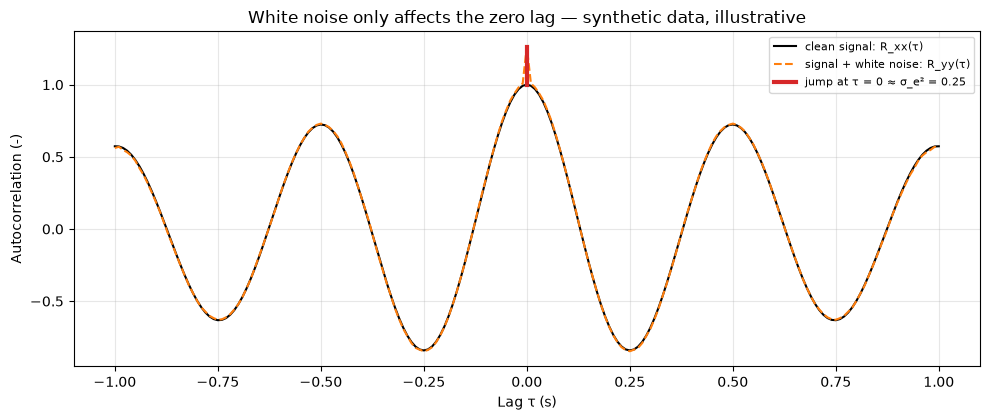

In [7]:
# White noise only changes the zero lag (illustrative)
rng_wn = np.random.default_rng(SEED)
fs_wn = 100.0
n_wn = int(100 * fs_wn)                          # 100 s
x_wn = modal_response([2.0], 0.05, fs_wn, n_wn, rng_wn)[0]       # clean signal, unit variance
sigma_e = 0.5
y_wn = x_wn + sigma_e * rng_wn.standard_normal(n_wn)              # Eq. 10: y = x + e
lags_wn, Rxx = cross_correlation(x_wn, x_wn, max_lag=int(1.0 * fs_wn))
_, Ryy = cross_correlation(y_wn, y_wn, max_lag=int(1.0 * fs_wn))
tau_wn = lags_wn / fs_wn
zero = lags_wn == 0
print(f"R_yy(0) - R_xx(0) = {(Ryy - Rxx)[zero][0]:.3f}  (sigma_e^2 = {sigma_e ** 2:.3f})")
print(f"Max |R_yy - R_xx| at the other lags: {np.abs(Ryy - Rxx)[~zero].max():.3f}")

fig, ax = plt.subplots(figsize=(10, 4.3))
ax.plot(tau_wn, Rxx, color="k", lw=1.5, label="clean signal: R_xx(τ)")
ax.plot(tau_wn, Ryy, "--", color="C1", lw=1.5, label="signal + white noise: R_yy(τ)")
ax.plot([0, 0], [Rxx[zero][0], Ryy[zero][0]], color="C3", lw=3, label=f"jump at τ = 0 ≈ σ_e² = {sigma_e ** 2:.2f}")
ax.set_xlabel("Lag τ (s)")
ax.set_ylabel("Autocorrelation (-)")
ax.set_title("White noise only affects the zero lag — synthetic data, illustrative")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

**Figura 6.** El ruido blanco solo afecta el desfase cero (ilustrativo, datos sintéticos): las dos autocorrelaciones se superponen en todos los desfases salvo en $\tau=0$, donde la de la señal con ruido salta hacia arriba una cantidad igual a $\sigma_e^2$ (Ec. 10): el ruido independiente solo suma en $\tau=0$. Las pequeñas diferencias que quedan en otros desfases se deben a que el registro es finito.

*6. Por qué funciona la vibración ambiental.* Si la carga (tráfico, viento) se modela como ruido blanco, la autocorrelación de la respuesta es proporcional a la integral del producto de la respuesta al impulso con una copia suya desplazada:

$$R_{yy}(\tau)\propto\int_{0}^{\infty}h(t)\,h(t+\tau)\,dt \tag{11}$$

- $h(t)$: respuesta al impulso de la estructura.

En palabras: la autocorrelación de la respuesta ambiental contiene la misma frecuencia y el mismo amortiguamiento que una prueba de impacto, sin conocer la entrada. Para un sistema de un grado de libertad (1 GDL) con poco amortiguamiento, con $\tau\ge 0$:

$$R_{yy}(\tau)\propto e^{-\zeta\omega_n\tau}\cos(\omega_d\tau) \tag{12}$$

- $\zeta$: razón de amortiguamiento.
- $\omega_n$: frecuencia natural circular, en rad/s.
- $\omega_d=\omega_n\sqrt{1-\zeta^2}$: frecuencia amortiguada.

En palabras: la autocorrelación se comporta como una vibración libre que decae.

*7. Algoritmo de 6 pasos (identificación por respuesta al impulso).*

1. Estimar la autocorrelación del registro ambiental.
2. Tomar la parte $\tau\ge 0$ como sustituto de la vibración libre.
3. Leer el periodo amortiguado $T_d$ a partir de los cruces por cero (dos cruces consecutivos están separados $T_d/2$).
4. Ajustar una envolvente exponencial a los picos para obtener el amortiguamiento:

$$\ln A(\tau)=\ln A_0-\zeta\,\omega_n\,\tau \tag{13}$$

- $A(\tau)$: amplitud de la envolvente.
- $A_0$: amplitud inicial.
- La pendiente de la recta es $-\zeta\omega_n$.

En palabras: en escala logarítmica la envolvente es una recta; su pendiente da el producto del amortiguamiento por la frecuencia.

$$\omega_n=\frac{\omega_d}{\sqrt{1-\zeta^2}},\qquad \omega_d=\frac{2\pi}{T_d} \tag{14}$$

- $T_d$: periodo amortiguado (paso 3).

En palabras: del periodo sale la frecuencia amortiguada y, con $\zeta$, la frecuencia natural; como $\zeta$ y $\omega_n$ aparecen juntos en la pendiente, se despejan a la vez.

5. Reconstruir la respuesta al impulso con los parámetros identificados (Ec. 12).
6. Validar contra el registro real.

**Mensaje clave de la clase:** todos los parámetros salen de la **forma** de la autocorrelación, nunca de la entrada ambiental, que es desconocida.

**Ejemplo sintético.** Oscilador de 1 GDL ($f_n=2$ Hz, $\zeta=0.02$) excitado por ruido blanco, simulado con `scipy.signal.lsim` a $f_s=100$ Hz durante 600 s.

Identified: f_n = 1.976 Hz (true 2.0), zeta = 0.0179 (true 0.02)


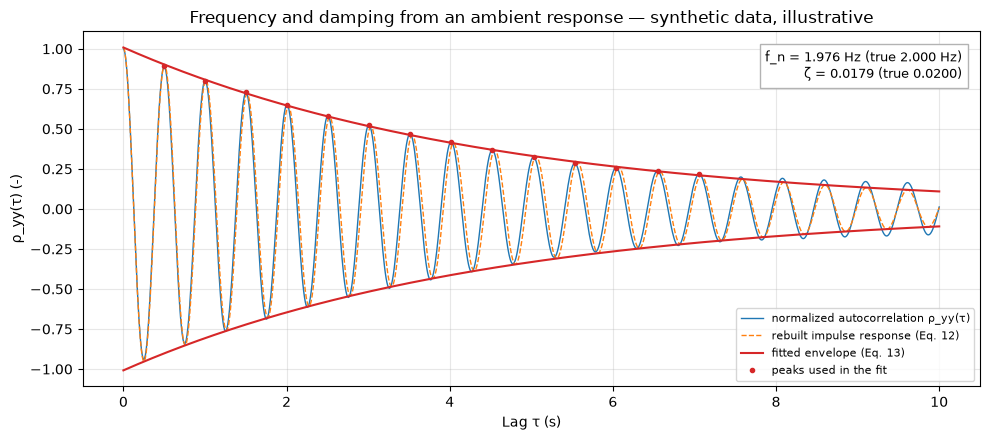

In [8]:
# Natural frequency and damping from an ambient response (6-step algorithm, illustrative)
rng_sd = np.random.default_rng(SEED)
fn_true, zeta_true = 2.0, 0.02
wn_true = 2 * np.pi * fn_true
fs_sd = 100.0
t_sd = np.arange(0, 600, 1 / fs_sd)              # 600 s
u_sd = rng_sd.standard_normal(t_sd.size)         # unknown white-noise load
_, y_sd, _ = lsim(([1.0], [1.0, 2 * zeta_true * wn_true, wn_true ** 2]), u_sd, t_sd)
y_sd -= y_sd.mean()

# Steps 1-2: autocorrelation, positive lags only
lags_sd, R_sd = cross_correlation(y_sd, y_sd, max_lag=int(10 * fs_sd))
keep = lags_sd >= 0
tau_sd = lags_sd[keep] / fs_sd
rho_sd = R_sd[keep] / R_sd[keep][0]
# Step 3: damped period from the zero crossings (linear interpolation between samples)
iz = np.flatnonzero(np.sign(rho_sd[:-1]) != np.sign(rho_sd[1:]))
tz = tau_sd[iz] - rho_sd[iz] * (tau_sd[iz + 1] - tau_sd[iz]) / (rho_sd[iz + 1] - rho_sd[iz])
Td = 2 * np.polyfit(np.arange(tz.size), tz, 1)[0]          # consecutive crossings are Td/2 apart
# Step 4: exponential envelope through the positive peaks (Eq. 13), only where it is above the noise
pk_sd, _ = find_peaks(rho_sd)
pk_sd = pk_sd[rho_sd[pk_sd] > 0.2]
slope, intercept = np.polyfit(tau_sd[pk_sd], np.log(rho_sd[pk_sd]), 1)
zeta_wn = -slope                                            # zeta * omega_n
wd = 2 * np.pi / Td                                         # Eq. 14
wn_est = np.sqrt(wd ** 2 + zeta_wn ** 2)                    # same as wd / sqrt(1 - zeta^2)
zeta_est = zeta_wn / wn_est
fn_est = wn_est / (2 * np.pi)
# Step 5: rebuilt impulse response (Eq. 12)
rebuilt = np.exp(intercept) * np.exp(-zeta_wn * tau_sd) * np.cos(wd * tau_sd)
print(f"Identified: f_n = {fn_est:.3f} Hz (true {fn_true}), zeta = {zeta_est:.4f} (true {zeta_true})")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(tau_sd, rho_sd, color="C0", lw=1, label="normalized autocorrelation ρ_yy(τ)")
ax.plot(tau_sd, rebuilt, "--", color="C1", lw=1, label="rebuilt impulse response (Eq. 12)")
env = np.exp(intercept) * np.exp(-zeta_wn * tau_sd)
ax.plot(tau_sd, env, color="C3", lw=1.5, label="fitted envelope (Eq. 13)")
ax.plot(tau_sd, -env, color="C3", lw=1.5)
ax.plot(tau_sd[pk_sd], rho_sd[pk_sd], "o", color="C3", ms=3, label="peaks used in the fit")
ax.text(0.98, 0.95, f"f_n = {fn_est:.3f} Hz (true {fn_true:.3f} Hz)\nζ = {zeta_est:.4f} (true {zeta_true:.4f})",
        transform=ax.transAxes, ha="right", va="top", fontsize=9, bbox=dict(fc="w", ec="0.7"))
ax.set_xlabel("Lag τ (s)")
ax.set_ylabel("ρ_yy(τ) (-)")
ax.set_title("Frequency and damping from an ambient response — synthetic data, illustrative")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

**Figura 7.** Frecuencia y amortiguamiento desde respuesta ambiental (ilustrativo, datos sintéticos): la autocorrelación de la respuesta de un oscilador excitado por ruido blanco decae como una vibración libre, y de ahí salen $f_n$ y $\zeta$ (recuadro, comparados con los verdaderos). La envolvente exponencial se ajusta solo a los picos que quedan por encima de 0.2, porque en desfases grandes la estimación es más ruidosa; la respuesta reconstruida (paso 5) se superpone a la autocorrelación (paso 6).

*8. Relación con la PSD* (teorema de Wiener–Khinchin).

$$S_{xx}(f)=\int_{-\infty}^{\infty}R_{xx}(\tau)\,e^{-i2\pi f\tau}\,d\tau \tag{15}$$

- $S_{xx}(f)$: densidad espectral de potencia.
- $f$: frecuencia, en Hz.
- $i$: unidad imaginaria.

En palabras: la transformada de Fourier de la autocorrelación dice cómo se reparte la energía de la señal entre las frecuencias.

- En teoría equivale a $|\text{FFT}|^2$; numéricamente no, porque en datos reales la ruta por autocorrelación (lo que hace Welch al promediar) da un espectro más limpio.
- En la clase se explica como "cancelación" del ruido blanco. Con precisión: el ruido blanco no desaparece, deja un piso plano en la PSD; lo que se elimina es la fluctuación aleatoria del espectro.
- El área bajo la PSD de un lado es igual al valor cuadrático medio de la señal.

*9. Límite.* Cuando varios modos se superponen en un mismo registro, la autocorrelación en el tiempo ya no los separa; para eso se pasa al dominio de la frecuencia (FDD, [2.1.1.3](#fdd)).

**Cómo se usa en drive-by**

- Sin artículo de referencia todavía en el mapa. Ver la Pregunta abierta.

**Ventajas**

- No necesita medir la fuerza de entrada.
- Rechaza ruido blanco independiente (solo afecta $\tau=0$).
- Da frecuencia y amortiguamiento de un modo dominante con un algoritmo simple.
- Su forma de decaimiento ayuda a diagnosticar el tipo de ruido.

**Desventajas**

- Supone carga tipo ruido blanco, sistema lineal y registro estacionario.
- No separa modos que se superponen en un mismo registro (requiere el dominio de la frecuencia).
- No rechaza ruido correlacionado (rosa o rojo), que sí aparece fuera de $\tau=0$.
- La estimación es menos confiable en desfases grandes, porque se promedian menos pares de muestras, y el amortiguamiento estimado es sensible a la duración del registro (conocimiento general).

**Pregunta abierta**

> ¿Sirve la autocorrelación en *drive-by*, donde el cruce del puente dura pocos segundos y la entrada (rugosidad filtrada por la suspensión, más el motor) no es ruido blanco? ¿Qué artículo lo aplica? (Deducción, no tema de la clase.)

**Artículos:** ninguno todavía. Fuente: CIV E 789 (Prof. M. Talebi-Kalaleh), Lecture 3, diapositivas 19–27 (sesión 5, 1 oct 2026).

> **Nota de fuentes.**
> - De la clase CIV E 789: definición, propiedades, detección del periodo, colores de ruido, rechazo de ruido blanco, por qué funciona la vibración ambiental y el algoritmo de 6 pasos (Lecture 3, D19–D27, sesión 5); la PSD como transformada de la autocorrelación y la idea de cancelación de ruido (sesiones 7 y 9); el límite con varios modos (sesión 5).
> - Conocimiento general: forma del estimador discreto, nombre del teorema de Wiener–Khinchin, forma $e^{-\zeta\omega_n\tau}\cos(\omega_d\tau)$, ecuación de la envolvente logarítmica, sesgo en desfases grandes y la precisión de que el ruido blanco deja un piso plano en la PSD.
> - Deducción: la Pregunta abierta sobre *drive-by*.

**Entradas y salidas**

- **Entrada:** un registro de aceleración (o deformación) de un solo sensor, con media removida, y su frecuencia de muestreo.
- **Salida:** la autocorrelación $R_{xx}(\tau)$ en función del desfase.
- **Qué se obtiene o interpreta:**
  - El periodo de componentes periódicas.
  - El tipo de ruido.
  - Para un modo dominante, la frecuencia natural y la razón de amortiguamiento.
  - La base para calcular la PSD.

[↑ Volver al índice](#indice)

<a id="cross-correlation"></a>
##### 2.1.1.2 Cross-correlation

*No aparece en el mapa; se explica aquí porque es el primer paso del FDD.*

**Qué es**

- Mide qué tan parecidas son dos señales cuando una se desplaza en el tiempo respecto a la otra.
- Con una sola señal comparada consigo misma se llama **autocorrelación**: es el caso particular $x=y$ ([2.1.1.1](#autocorrelation)).
- Su transformada de Fourier es la **densidad espectral cruzada** (CPSD, *cross power spectral density*): dice cuánta energía comparten las dos señales en cada frecuencia (teorema de Wiener–Khinchin).

**Para qué se aplica**

- Para encontrar el retraso entre dos señales y qué tanto se parecen.
- En análisis modal: para pasar de muchas señales medidas a una matriz que resume cómo se relacionan todos los puntos entre sí. En esa matriz el ruido aleatorio se promedia y quedan las vibraciones que los puntos comparten, que son los modos.

**Cómo funciona**

1. Se toman dos señales $x_i(t)$ y $x_j(t)$.
2. Se desplaza una un tiempo $\tau$, se multiplica punto por punto con la otra y se promedia.
3. Se repite para muchos $\tau$: sale una curva de correlación contra $\tau$. Si tiene un pico en $\tau=\tau_0$, las señales se parecen con un retraso $\tau_0$. Un pico en desfase positivo significa que la segunda señal llegó después (convención de la clase).
4. Con $n$ puntos de medición se calcula para todos los pares: sale una matriz $n\times n$ por cada $\tau$.
5. Cada señal de un puente es una combinación de los mismos modos con distintos pesos (la forma modal en ese punto). Por eso las señales de dos puntos son distintas, pero comparten las mismas coordenadas modales en el tiempo, y la correlación conserva esa estructura.

*Correlación cruzada (pasos 1–3).*

$$R_{ij}(\tau)=E\left[x_i(t)\,x_j(t+\tau)\right] \tag{16}$$

- $R_{ij}(\tau)$: correlación cruzada entre los puntos $i$ y $j$ para el desplazamiento $\tau$.
- $x_i(t)$, $x_j(t)$: señales en los puntos $i$ y $j$.
- $\tau$: desplazamiento en el tiempo, en s.
- $E[\cdot]$: promedio o valor esperado.

En palabras: se adelanta $x_j$ un tiempo $\tau$, se multiplica por $x_i$ y se promedia; si el resultado es grande, las dos señales se parecen con ese desplazamiento. Con $i=j$ es la autocorrelación.

*Estimación con señales muestreadas.*

$$\hat{R}_{ij}(k)=\frac{1}{N}\sum_{n=0}^{N-1-k}x_i[n]\,x_j[n+k] \tag{17}$$

- $\hat{R}_{ij}(k)$: estimación de la correlación para un desplazamiento de $k$ muestras ($\tau=k\,\Delta t$, con $\Delta t$ el paso de tiempo).
- $x_i[n]$, $x_j[n]$: muestra $n$ de cada señal.
- $N$: número de muestras.
- $k$: desplazamiento en muestras ($k\ge 0$; para $k<0$ se usa $\hat{R}_{ij}(-k)=\hat{R}_{ji}(k)$).

En palabras: es la Ec. 16 con una suma en lugar del valor esperado; para cada $k$ se suman los productos de las muestras que se traslapan y se divide entre $N$.

**Ejemplo sintético.** Dos sensores miden la misma señal (ruido suavizado); al segundo le llega 0.3 s después. Cada sensor agrega su propio ruido, independiente del otro y del mismo tamaño que la señal.

Peak of the cross-correlation at tau = 0.30 s (true delay 0.3 s)
Max |R_xy - R_s1s2| / max R_s1s2: 0.081


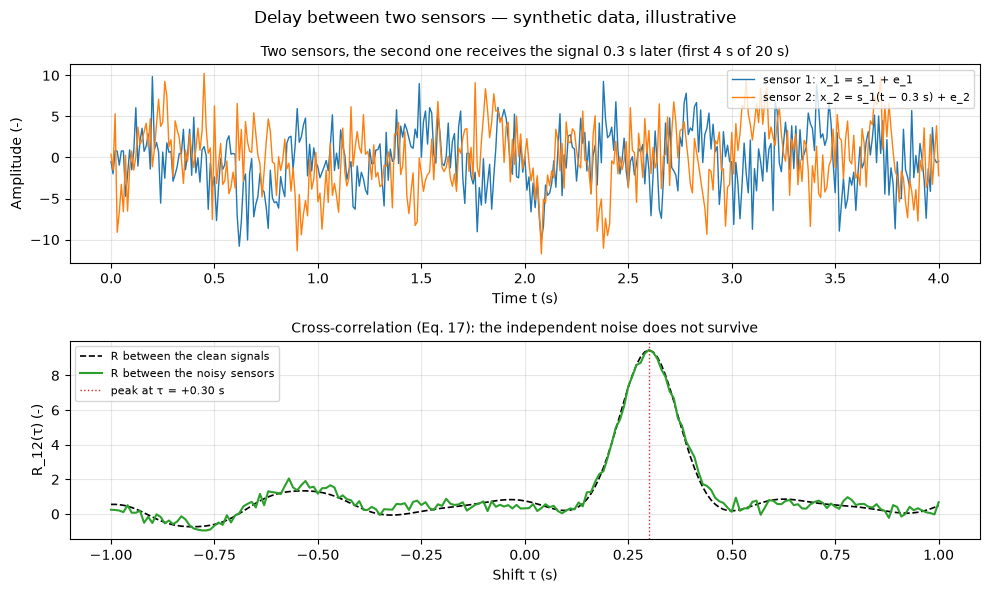

In [9]:
# Delay between two sensors: a signal, its copy delayed by 0.3 s, and independent noise (illustrative)
rng_xc = np.random.default_rng(SEED)    # own generator: keeps the other sections unchanged
fs_c = 100.0                            # sampling rate, Hz
delay = 0.3                             # delay of x_2, s
n_c = int(20 * fs_c)                    # 20 s of signal
d = int(delay * fs_c)                   # delay in samples
kernel = np.exp(-0.5 * (np.arange(-15, 16) / 5) ** 2)              # Gaussian smoothing (about 0.05 s)
raw = np.convolve(rng_xc.standard_normal(n_c + d), kernel, mode="same")
s1_c = raw[d:]                          # signal part at sensor 1
s2_c = raw[:n_c]                        # signal part at sensor 2: s_1(t - 0.3 s)
rng_xn = np.random.default_rng(SEED + 20)
e1_c, e2_c = s1_c.std() * rng_xn.standard_normal((2, n_c))   # independent noises, same size as the signal
x1_c, x2_c = s1_c + e1_c, s2_c + e2_c   # what each sensor measures
t_c = np.arange(n_c) / fs_c

lags, R12_clean = cross_correlation(s1_c, s2_c, max_lag=int(1.0 * fs_c))   # Eq. 17, signals only
_, R12 = cross_correlation(x1_c, x2_c, max_lag=int(1.0 * fs_c))            # Eq. 17, with noise
tau = lags / fs_c
tau_peak = tau[np.argmax(R12)]
print(f"Peak of the cross-correlation at tau = {tau_peak:.2f} s (true delay {delay} s)")
print(f"Max |R_xy - R_s1s2| / max R_s1s2: {np.abs(R12 - R12_clean).max() / R12_clean.max():.3f}")

fig, axes = plt.subplots(2, 1, figsize=(10, 6))
show = t_c <= 4
axes[0].plot(t_c[show], x1_c[show], color="C0", lw=1, label="sensor 1: x_1 = s_1 + e_1")
axes[0].plot(t_c[show], x2_c[show], color="C1", lw=1, label="sensor 2: x_2 = s_1(t − 0.3 s) + e_2")
axes[0].set_xlabel("Time t (s)")
axes[0].set_ylabel("Amplitude (-)")
axes[0].set_title("Two sensors, the second one receives the signal 0.3 s later (first 4 s of 20 s)", fontsize=10)
axes[0].legend(loc="upper right", fontsize=8)
axes[1].plot(tau, R12_clean, "k--", lw=1.2, label="R between the clean signals")
axes[1].plot(tau, R12, color="C2", lw=1.5, label="R between the noisy sensors")
axes[1].axvline(tau_peak, color="C3", ls=":", lw=1, label=f"peak at τ = +{tau_peak:.2f} s")
axes[1].set_xlabel("Shift τ (s)")
axes[1].set_ylabel("R_12(τ) (-)")
axes[1].set_title("Cross-correlation (Eq. 17): the independent noise does not survive", fontsize=10)
axes[1].legend(loc="upper left", fontsize=8)
fig.suptitle("Delay between two sensors — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 8.** Retraso entre dos sensores (ilustrativo, datos sintéticos): arriba, lo que mide cada sensor; con el ruido, el retraso no se ve. Abajo, la correlación cruzada tiene un solo pico en $\tau=+0.3$ s: el pico indica cuánto tarda la señal en llegar al segundo sensor. La curva con ruido (verde) casi coincide con la de las señales limpias (negro): el ruido de cada sensor se cancela al correlacionarlos.

*Cancelación de ruido independiente.* Si cada sensor mide una parte de señal más su propio ruido, $x=s_1+e_1$ e $y=s_2+e_2$, con $e_1$ y $e_2$ independientes entre sí y de las señales:

$$R_{xy}(\tau)=R_{s_1 s_2}(\tau) \tag{18}$$

- $s_1$, $s_2$: partes de señal en cada sensor.
- $e_1$, $e_2$: ruidos independientes.
- $R_{s_1 s_2}(\tau)$: correlación cruzada entre las partes de señal.

En palabras: los términos cruzados con ruido promedian cero, así que los ruidos no sobreviven en la correlación cruzada. Por eso los estimadores basados en correlación son más robustos que dividir espectros crudos. A diferencia de la autocorrelación ([2.1.1.1](#autocorrelation)), donde el ruido de un sensor queda en $\tau=0$, aquí no queda en ningún desfase.

*Expansión modal (paso 5).*

$$\mathbf{x}(t)=\Phi\,\mathbf{q}(t)\quad\Rightarrow\quad \mathbf{R}(\tau)=\Phi\,\mathbf{R}_{qq}(\tau)\,\Phi^{T} \tag{19}$$

- $\mathbf{x}(t)$: vector con las señales de los $n$ puntos.
- $\Phi$: matriz de formas modales ($n\times m$, una columna por modo); su elemento $\Phi_{ik}$ es el peso del modo $k$ en el punto $i$.
- $\mathbf{q}(t)$: coordenadas modales, las $m$ señales de los modos en el tiempo.
- $\mathbf{R}(\tau)$: matriz de correlación $n\times n$; su elemento $(i,j)$ es $R_{ij}(\tau)$.
- $\mathbf{R}_{qq}(\tau)$: correlación de las coordenadas modales ($m\times m$).
- $T$: transpuesta.

En palabras: como todas las señales están hechas de las mismas coordenadas modales, su matriz de correlación es la correlación de los modos "vista" a través de las formas modales. Es la expansión que usa el artículo para la matriz de sus 17 puntos fijos (ecs. 32–33 del artículo).

**Ejemplo sintético.** Dos puntos de una viga simplemente apoyada, en $x=0.25L$ y $x=0.6L$, con dos modos ($\phi_k=\sin(k\pi x/L)$; 1.44 y 3.68 Hz, amortiguamiento 2 %, excitados con ruido blanco).

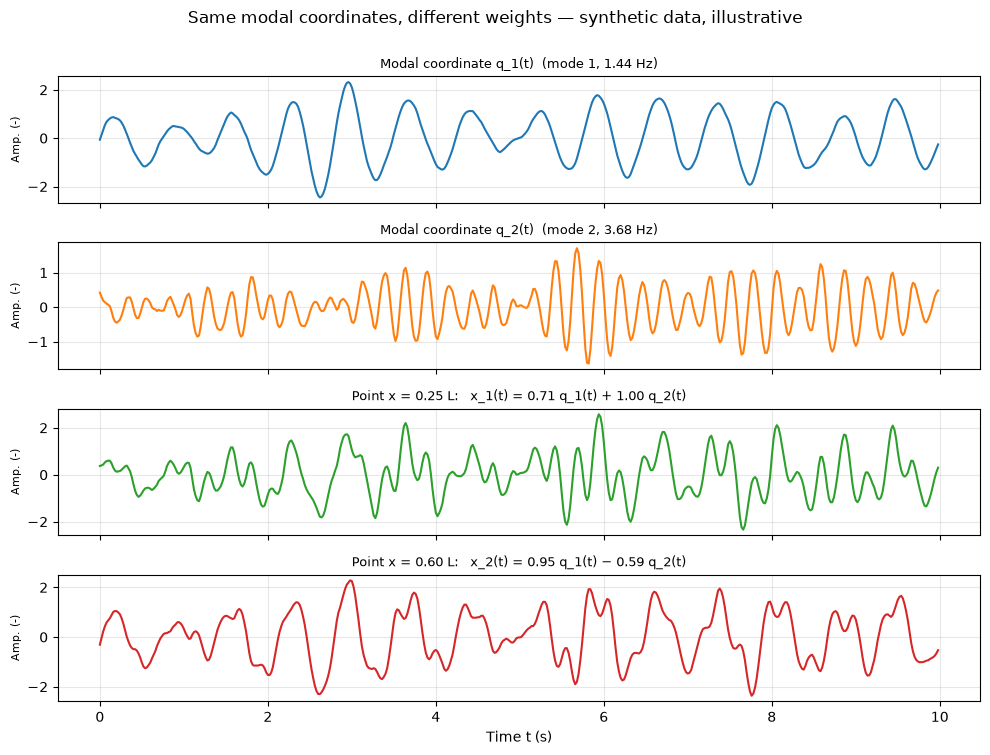

In [10]:
# Two points of a beam with 2 modes: different signals built from the same modal coordinates (illustrative)
rng_2m = np.random.default_rng(SEED + 1)
fs_2m = 50.0                                  # sampling rate, Hz
t_2m = np.arange(0, 10, 1 / fs_2m)            # time, s
q_2m = modal_response([1.44, 3.68], 0.02, fs_2m, t_2m.size, rng_2m) * np.array([[1.0], [0.6]])
x_pts = np.array([0.25, 0.6])                 # relative positions x/L of the two points
Phi_2m = beam_modes(x_pts, 2)                 # weights of each mode at each point
x_2m = Phi_2m @ q_2m                          # Eq. 19: x = Phi q

fig, axes = plt.subplots(4, 1, figsize=(10, 7.5), sharex=True)
axes[0].plot(t_2m, q_2m[0], color="C0")
axes[0].set_title("Modal coordinate q_1(t)  (mode 1, 1.44 Hz)", fontsize=9)
axes[1].plot(t_2m, q_2m[1], color="C1")
axes[1].set_title("Modal coordinate q_2(t)  (mode 2, 3.68 Hz)", fontsize=9)
for r, (xr, color) in enumerate(zip(x_pts, ["C2", "C3"])):
    w1, w2 = Phi_2m[r]
    axes[2 + r].plot(t_2m, x_2m[r], color=color)
    axes[2 + r].set_title(f"Point x = {xr:.2f} L:   x_{r + 1}(t) = {w1:.2f} q_1(t) {'+' if w2 >= 0 else '−'} "
                          f"{abs(w2):.2f} q_2(t)", fontsize=9)
for ax in axes:
    ax.set_ylabel("Amp. (-)", fontsize=8)
axes[-1].set_xlabel("Time t (s)")
fig.suptitle("Same modal coordinates, different weights — synthetic data, illustrative", y=1.0)
fig.tight_layout()
plt.show()

**Figura 9.** Coordenadas modales $q_1(t)$, $q_2(t)$ y respuesta en dos puntos de una viga (ilustrativo, datos sintéticos): $x_1$ y $x_2$ se ven distintas, pero las dos son sumas de las mismas $q_1$ y $q_2$ con los pesos de las formas modales en cada punto. En $x=0.6L$ el modo 2 entra con signo negativo, porque ese punto está del otro lado de su nodo (en $x=0.5L$).

**Ejemplo sintético.** La misma viga con tres modos (frecuencias de ejemplo 1.44, 3.68 y 4.66 Hz; amortiguamiento 2 %), medida en 17 puntos equiespaciados durante 1200 s a 20 Hz, con ruido de medición independiente en cada punto. Estos mismos datos se usan en el FDD (2.1.1.3).

Max |difference| off the diagonal: 0.0025
Mean difference on the diagonal:   0.0097  (noise variance = 0.0100)


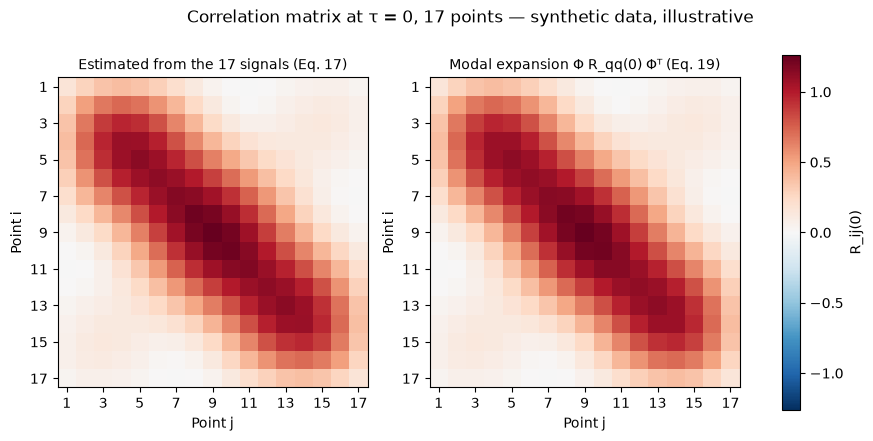

In [11]:
# Correlation matrix at tau = 0 of 17 points of a beam with 3 modes (illustrative; reused by the FDD)
rng_beam = np.random.default_rng(SEED + 2)
fs_beam = 20.0                                # sampling rate, Hz
n_beam = int(1200 * fs_beam)                  # 1200 s
f_true = np.array([1.44, 3.68, 4.66])         # example natural frequencies, Hz
amp_modes = np.array([1.0, 0.7, 0.5])         # RMS of each modal coordinate
x_rel = np.arange(1, 18) / 18                 # 17 equally spaced points, x/L
Phi_beam = beam_modes(x_rel, 3)               # true mode shapes, 17 x 3
q_beam = modal_response(f_true, 0.02, fs_beam, n_beam, rng_beam) * amp_modes[:, None]
noise_beam = 0.1 * rng_beam.standard_normal((17, n_beam))
x_beam = Phi_beam @ q_beam + noise_beam       # measured responses, 17 x N

R0 = x_beam @ x_beam.T / n_beam               # Eq. 17 with k = 0, all pairs
R0_modal = Phi_beam @ (q_beam @ q_beam.T / n_beam) @ Phi_beam.T   # Eq. 19: Phi R_qq(0) Phi^T
diff = R0 - R0_modal
off = ~np.eye(17, dtype=bool)
print(f"Max |difference| off the diagonal: {np.abs(diff[off]).max():.4f}")
print(f"Mean difference on the diagonal:   {np.diag(diff).mean():.4f}  (noise variance = {0.1 ** 2:.4f})")

vmax = np.abs(R0).max()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, M, title in zip(axes, [R0, R0_modal],
                        ["Estimated from the 17 signals (Eq. 17)", "Modal expansion Φ R_qq(0) Φᵀ (Eq. 19)"]):
    im = ax.imshow(M, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax.set_xticks(range(0, 17, 2), labels=range(1, 18, 2))
    ax.set_yticks(range(0, 17, 2), labels=range(1, 18, 2))
    ax.set_xlabel("Point j")
    ax.set_ylabel("Point i")
    ax.set_title(title, fontsize=10)
    ax.grid(False)
fig.colorbar(im, ax=axes, label="R_ij(0)")
fig.suptitle("Correlation matrix at τ = 0, 17 points — synthetic data, illustrative")
plt.show()

**Figura 10.** Matriz de correlación en $\tau=0$ de los 17 puntos (ilustrativo, datos sintéticos): a la izquierda, calculada con las señales; a la derecha, con la expansión modal (Ec. 19). Las dos coinciden fuera de la diagonal: el ruido de cada punto no se comparte con los demás y se promedia. Solo la diagonal es un poco mayor a la izquierda, por la varianza del ruido de cada punto.

- Los puntos vecinos están muy correlacionados. Los puntos lejanos casi no, porque los modos 2 y 3 los mueven en sentidos opuestos y restan lo que aporta el modo 1.

*Paso a la frecuencia (Wiener–Khinchin).*

$$G_{ij}(\omega)=\int_{-\infty}^{\infty}R_{ij}(\tau)\,e^{-i\omega\tau}\,d\tau \tag{20}$$

- $G_{ij}(\omega)$: densidad espectral cruzada (CPSD) entre los puntos $i$ y $j$; con $i=j$ es la densidad espectral de potencia del punto $i$.
- $R_{ij}(\tau)$: correlación cruzada (Ec. 16).
- $\omega$: frecuencia angular, en rad/s ($\omega=2\pi f$).
- $i$ en el exponente: unidad imaginaria (no el índice del punto).

En palabras: la transformada de Fourier de la correlación dice cuánta energía comparten las dos señales en cada frecuencia. Con todos los pares sale la matriz espectral que usa el FDD ([2.1.1.3](#fdd)): cada densidad espectral cruzada es un elemento fuera de la diagonal de esa matriz, y las PSD de la diagonal son las transformadas de las autocorrelaciones (Ec. 15).

**Cómo se usa en drive-by** (referencia: Talebi-Kalaleh et al., 2025)

- Calculan la matriz de correlación $17\times 17$ entre las respuestas de los 17 puntos fijos, a partir de la matriz dispersa con los datos faltantes en cero.
- Es el primer paso del FDD.

**Ventajas**

- Promedia el ruido no correlacionado entre puntos (Ec. 18).
- No necesita conocer la excitación.

**Desventajas**

- Necesita señales largas para que la estimación sea estable.
- Con datos faltantes, cada par de puntos tiene distinta cantidad de datos válidos.

**Artículos:** Talebi-Kalaleh et al. (2025).

> **Nota de fuentes.** La definición general de correlación cruzada, autocorrelación y Wiener–Khinchin es conocimiento general. Del artículo vienen: la matriz de correlación 17 × 17 de los puntos fijos (ec. 32) y su expansión modal (ec. 33).
>
> Del curso CIV E 789 (Prof. M. Talebi-Kalaleh) vienen: la definición como parecido entre dos señales en función del desfase, la convención del pico en desfase positivo, la autocorrelación como caso particular y la cancelación de ruido independiente (Lecture 3, D19, sesión 5), y la relación con la densidad espectral cruzada (sesión 7).
>
> Nota curiosa de la clase: las redes "convolucionales" calculan en realidad correlación cruzada, no convolución (la convolución además voltea la señal); también es la idea detrás de buscar un patrón dentro de una imagen (*template matching*).

**Entradas y salidas**

- **Entrada:** las señales de respuesta en $n$ puntos, sincronizadas en el tiempo.
- **Salida:** la matriz de correlación $n\times n$ para cada desplazamiento $\tau$.
- **Qué se obtiene o interpreta:**
  - Qué tan relacionadas están las vibraciones de cada par de puntos y con qué retraso.
  - Al pasarla a frecuencia, la PSD cruzada entre cada par de sensores: los elementos de la matriz espectral que usa el FDD ([2.1.1.3](#fdd)).

[↑ Volver al índice](#indice)

<a id="fdd"></a>
##### 2.1.1.3 FDD (Frequency Domain Decomposition)

FDD: *Frequency Domain Decomposition*, descomposición en el dominio de la frecuencia.

**Qué es**

- Es un método de identificación modal "solo con la salida" (*output-only*): usa las respuestas medidas en varios puntos, sin conocer la fuerza que excita al puente.
- Separa los modos en el dominio de la frecuencia, aplicando una SVD a la matriz espectral en cada frecuencia.
- Da a la vez las frecuencias naturales y las formas modales.

**Para qué se aplica**

- Para identificar frecuencias y formas modales con vibración ambiental o tráfico, cuando no se mide la excitación.
- Funciona bien aunque dos modos estén cerca en frecuencia.

**Cómo funciona**

1. Se calcula la correlación cruzada entre todos los pares de puntos ([2.1.1.2](#cross-correlation)).
2. Se pasa al dominio de la frecuencia: sale la matriz espectral $\mathbf{G}(\omega)$, de $n\times n$, en cada frecuencia.
3. En cada frecuencia se aplica una SVD a $\mathbf{G}(\omega)$ (la SVD se explica en [2.2.4.2](#svd-completed-matrix)).
4. Se grafica el primer valor singular contra la frecuencia. Sus picos son las frecuencias naturales.
5. En cada pico, el primer vector singular es la forma modal de ese modo.

**Idea clave:** cerca de una frecuencia natural domina un solo modo, así que la matriz espectral es casi de rango uno y la SVD la separa.

*Entrada en drive-by: la matriz dispersa* (ec. 31 del artículo).

$$\ddot{\mathbf{u}}_b(t)=\Gamma(t)\,\ddot{\mathbf{w}}_b(t) \tag{21}$$

- $\ddot{\mathbf{u}}_b(t)$: respuesta (aceleración) en los puntos fijos del puente, con los faltantes en cero.
- $\Gamma(t)$: matriz diagonal; su elemento $i$ vale 1 si en el instante $t$ hay dato válido en el punto $i$ y 0 si no.
- $\ddot{\mathbf{w}}_b(t)$: respuesta completa en los mismos puntos.

En palabras: la matriz dispersa es la respuesta completa con los datos que faltan puestos en cero.

*Paso 2: matriz espectral.*

$$\mathbf{G}(\omega)=\int_{-\infty}^{\infty}\mathbf{R}(\tau)\,e^{-i\omega\tau}\,d\tau \tag{22}$$

- $\mathbf{G}(\omega)$: matriz espectral $n\times n$; su elemento $(i,j)$ es la densidad espectral cruzada $G_{ij}(\omega)$ (Ec. 20).
- $\mathbf{R}(\tau)$: matriz de correlación (Ec. 19).
- $\omega$: frecuencia angular, en rad/s.

En palabras: es la Ec. 20 aplicada a todos los pares a la vez. En la práctica se estima con el método de Welch (promedio de los espectros de muchos tramos de la señal), que es equivalente.

*Paso 3: SVD en cada frecuencia* (ecs. 34–35 del artículo).

$$\mathbf{G}(j\omega)=\mathbf{U}(\omega)\,\Sigma(\omega)\,\mathbf{U}^{H}(\omega) \tag{23}$$

- $\mathbf{G}(j\omega)$: la matriz espectral de la Ec. 22 en la frecuencia $\omega$ ($j$: unidad imaginaria).
- $\mathbf{U}(\omega)$: matriz de vectores singulares, una columna $\mathbf{u}_r$ por componente.
- $\Sigma(\omega)$: matriz diagonal con los valores singulares, ordenados de mayor a menor ($\sigma_1\ge\sigma_2\ge\dots\ge 0$).
- $H$: transpuesta conjugada.

En palabras: en cada frecuencia, la matriz espectral se separa en componentes ordenadas de la más fuerte a la más débil. Como $\mathbf{G}$ es hermítica (igual a su transpuesta conjugada), la misma $\mathbf{U}$ aparece a los dos lados.

*Pasos 4–5: picos y formas modales.*

$$\mathbf{G}(\omega_k)\approx\sigma_1\,\mathbf{u}_1\mathbf{u}_1^{H},\qquad \phi_k\approx\mathbf{u}_1(\omega_k) \tag{24}$$

- $\omega_k$: frecuencia natural del modo $k$ (un pico de $\sigma_1$).
- $\sigma_1$: primer valor singular en $\omega_k$.
- $\mathbf{u}_1$: primer vector singular en $\omega_k$.
- $\phi_k$: forma modal del modo $k$ en los $n$ puntos.

En palabras: en el pico de un modo, la matriz espectral es casi un solo producto $\mathbf{u}_1\mathbf{u}_1^{H}$ (rango uno); por eso el primer vector singular es la forma modal y el segundo valor singular queda mucho más bajo.

Para comparar formas se usa el **MAC** (*Modal Assurance Criterion*, criterio de semejanza modal): $\text{MAC}(\phi,\mathbf{u})=|\phi^{H}\mathbf{u}|^2/\big((\phi^{H}\phi)(\mathbf{u}^{H}\mathbf{u})\big)$. Vale 1 si las dos formas son iguales salvo una escala, y 0 si no tienen nada en común.

**Ejemplo sintético.** Los 17 puntos de la viga de la Figura 10 (tres modos de 1.44, 3.68 y 4.66 Hz, excitados con ruido blanco, 1200 s a 20 Hz). Las frecuencias son valores de ejemplo: en una viga simplemente apoyada real crecerían con $k^2$. Los picos se buscan cerca de cada frecuencia verdadera ($\pm$0.15 Hz); en la práctica se escogen en la gráfica.

Frequency resolution: 0.0098 Hz
Mode 1: true 1.44 Hz, FDD 1.426 Hz (error 1.0 %), sigma_1/sigma_2 = 2327
Mode 2: true 3.68 Hz, FDD 3.691 Hz (error 0.3 %), sigma_1/sigma_2 = 164
Mode 3: true 4.66 Hz, FDD 4.648 Hz (error 0.2 %), sigma_1/sigma_2 = 82


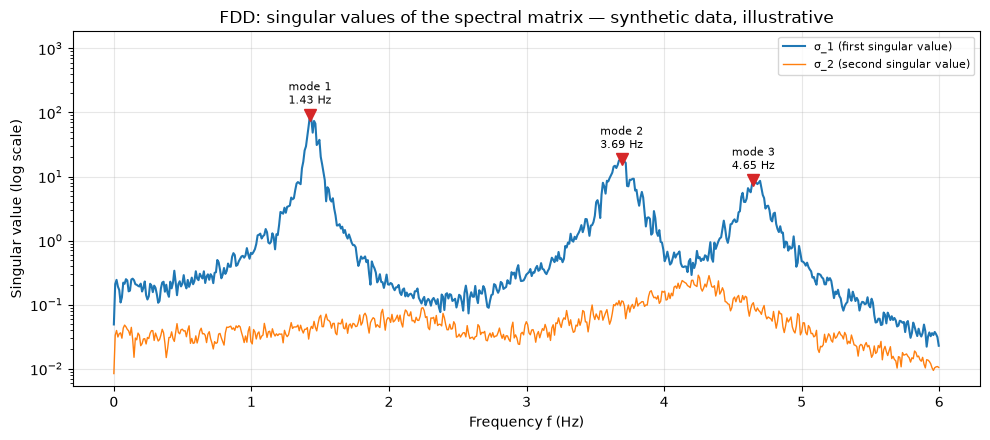

In [12]:
# FDD on the 17-point beam of Fig. 10: singular values of G(f) at each frequency (illustrative)
def fdd(x, fs, nperseg=2048):
    """Spectral matrix with Welch (Eq. 22) and its SVD at each frequency (Eq. 23)."""
    f, G = csd(x[:, None, :], x[None, :, :], fs=fs, nperseg=nperseg)   # G[i, j, f]
    U, s, _ = np.linalg.svd(np.moveaxis(G, -1, 0))                       # one SVD per frequency
    return f, s, U


def pick_peaks(f, s1, f_guess, half=0.15):
    """Index of the highest sigma_1 within +-half Hz of each guessed frequency."""
    return [np.flatnonzero(np.abs(f - fg) <= half)[np.argmax(s1[np.abs(f - fg) <= half])] for fg in f_guess]


f_fdd, s_fdd, U_fdd = fdd(x_beam, fs_beam)
peaks = pick_peaks(f_fdd, s_fdd[:, 0], f_true)
print(f"Frequency resolution: {f_fdd[1]:.4f} Hz")
for k, i in enumerate(peaks):
    print(f"Mode {k + 1}: true {f_true[k]:.2f} Hz, FDD {f_fdd[i]:.3f} Hz "
          f"(error {100 * abs(f_fdd[i] - f_true[k]) / f_true[k]:.1f} %), sigma_1/sigma_2 = {s_fdd[i, 0] / s_fdd[i, 1]:.0f}")

fig, ax = plt.subplots(figsize=(10, 4.5))
keep = f_fdd <= 6
ax.semilogy(f_fdd[keep], s_fdd[keep, 0], color="C0", label="σ_1 (first singular value)")
ax.semilogy(f_fdd[keep], s_fdd[keep, 1], color="C1", lw=1, label="σ_2 (second singular value)")
for k, i in enumerate(peaks):
    ax.plot(f_fdd[i], s_fdd[i, 0], "v", color="C3", ms=8)
    ax.annotate(f"mode {k + 1}\n{f_fdd[i]:.2f} Hz", (f_fdd[i], s_fdd[i, 0]), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=8)
ax.set_xlabel("Frequency f (Hz)")
ax.set_ylabel("Singular value (log scale)")
ax.set_ylim(top=s_fdd[keep, 0].max() * 20)
ax.set_title("FDD: singular values of the spectral matrix — synthetic data, illustrative")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

**Figura 11.** Primer y segundo valor singular de la matriz espectral contra la frecuencia (ilustrativo, datos sintéticos): $\sigma_1$ tiene un pico en cada frecuencia natural (1.44, 3.68 y 4.66 Hz). En los picos $\sigma_2$ queda muy por debajo de $\sigma_1$: la matriz es casi de rango uno (Ec. 24). Los modos 2 y 3 están cerca (1 Hz de diferencia) y aun así se separan.

- La frecuencia identificada difiere de la verdadera en 1 % o menos. El error viene de la resolución del espectro (0.01 Hz con tramos de 2048 muestras) y de la variabilidad de la estimación; las dos mejoran con señales más largas.

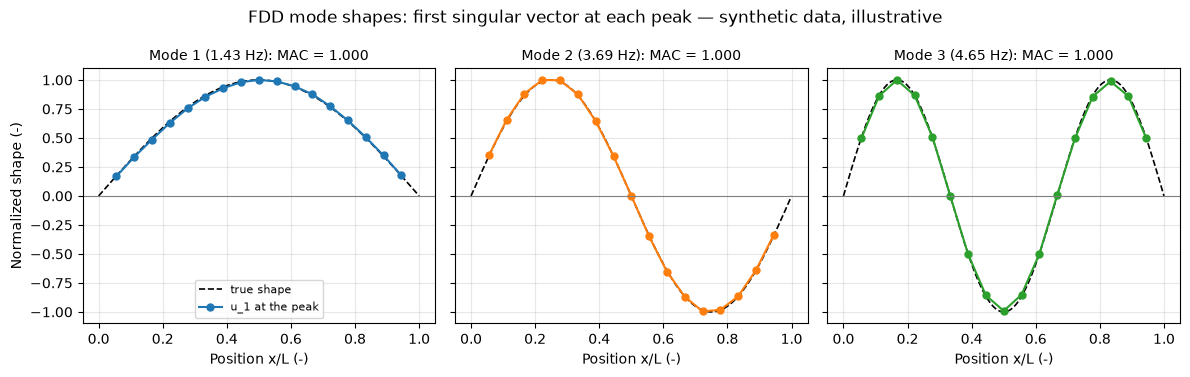

In [13]:
# First singular vector at each peak vs the true mode shape (illustrative)
x_fine = np.linspace(0, 1, 200)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for k, (ax, i) in enumerate(zip(axes, peaks)):
    u = real_shape(U_fdd[i, :, 0], Phi_beam[:, k])
    ax.plot(x_fine, np.sin((k + 1) * np.pi * x_fine), "k--", lw=1.2, label="true shape")
    ax.plot(x_rel, u, "o-", color=f"C{k}", ms=5, label="u_1 at the peak")
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_title(f"Mode {k + 1} ({f_fdd[i]:.2f} Hz): MAC = {mac(Phi_beam[:, k], U_fdd[i, :, 0]):.3f}", fontsize=10)
    ax.set_xlabel("Position x/L (-)")
axes[0].set_ylabel("Normalized shape (-)")
axes[0].legend(loc="lower center", fontsize=8)
fig.suptitle("FDD mode shapes: first singular vector at each peak — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 12.** Primer vector singular en cada pico comparado con la forma modal verdadera (ilustrativo, datos sintéticos): los tres coinciden, con MAC cercano a 1. El vector singular es complejo; se gira para hacerlo real y se escala a un máximo de 1, porque el FDD da la forma, no su tamaño.

**Cómo se usa en drive-by** (referencia: Talebi-Kalaleh et al., 2025)

- Lo aplican directamente a la matriz dispersa de 17 puntos fijos × tiempo, con los datos faltantes en cero (Ec. 21), sin completarla.
- Salidas: un vector de frecuencias (picos del primer valor singular) y una matriz de formas modales de 17 filas × número de modos.
- Identificaron los tres primeros modos con MAC > 95 % y errores de frecuencia < 3 %, con 80 % de datos faltantes.

**Ejemplo sintético.** La misma viga con el 80 % de los datos en cero (Ec. 21): cada punto conserva bloques de 1 s escogidos al azar, el 20 % del tiempo. El patrón de faltantes es inventado; no reproduce el del artículo.

Missing data: 79.9 %
Mode 1: FDD 1.426 Hz (error 1.0 %), MAC complete 1.000, MAC 80 % missing 0.975
Mode 2: FDD 3.682 Hz (error 0.0 %), MAC complete 1.000, MAC 80 % missing 0.953
Mode 3: FDD 4.648 Hz (error 0.2 %), MAC complete 1.000, MAC 80 % missing 0.961


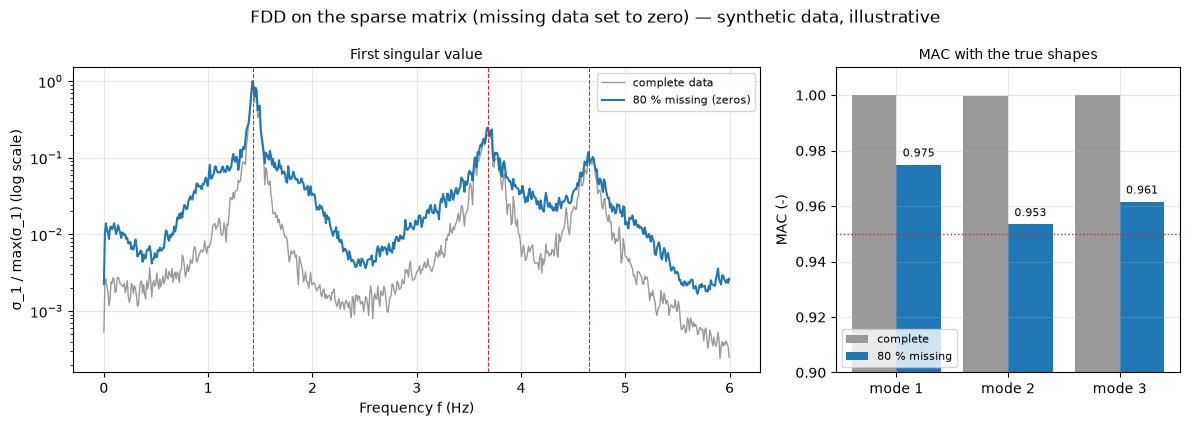

In [14]:
# FDD with 80 % of the data set to zero (sparse matrix of Eq. 21, illustrative)
rng_mask = np.random.default_rng(SEED + 3)
block = int(1.0 * fs_beam)                                   # 1 s blocks
n_blocks = int(np.ceil(n_beam / block))
Gamma = np.repeat(rng_mask.random((17, n_blocks)) < 0.2, block, axis=1)[:, :n_beam]   # 1 = valid sample
x_sparse = x_beam * Gamma                                    # Eq. 21: missing data set to zero
print(f"Missing data: {100 * (1 - Gamma.mean()):.1f} %")

f_sp, s_sp, U_sp = fdd(x_sparse, fs_beam)
peaks_sp = pick_peaks(f_sp, s_sp[:, 0], f_true)
mac_full = [mac(Phi_beam[:, k], U_fdd[i, :, 0]) for k, i in enumerate(peaks)]
mac_sp = [mac(Phi_beam[:, k], U_sp[i, :, 0]) for k, i in enumerate(peaks_sp)]
for k, i in enumerate(peaks_sp):
    print(f"Mode {k + 1}: FDD {f_sp[i]:.3f} Hz (error {100 * abs(f_sp[i] - f_true[k]) / f_true[k]:.1f} %), "
          f"MAC complete {mac_full[k]:.3f}, MAC 80 % missing {mac_sp[k]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [2, 1]})
keep = f_fdd <= 6
axes[0].semilogy(f_fdd[keep], s_fdd[keep, 0] / s_fdd[keep, 0].max(), color="0.6", lw=1, label="complete data")
axes[0].semilogy(f_sp[keep], s_sp[keep, 0] / s_sp[keep, 0].max(), color="C0", label="80 % missing (zeros)")
for i in peaks_sp:
    axes[0].axvline(f_sp[i], color="C3", ls="--", lw=0.8)
axes[0].set_xlabel("Frequency f (Hz)")
axes[0].set_ylabel("σ_1 / max(σ_1) (log scale)")
axes[0].set_title("First singular value", fontsize=10)
axes[0].legend(loc="upper right", fontsize=8)
pos_bar = np.arange(3)
axes[1].bar(pos_bar - 0.2, mac_full, 0.4, color="0.6", label="complete")
axes[1].bar(pos_bar + 0.2, mac_sp, 0.4, color="C0", label="80 % missing")
for p, m in zip(pos_bar + 0.2, mac_sp):
    axes[1].text(p, m + 0.003, f"{m:.3f}", ha="center", fontsize=8)
axes[1].axhline(0.95, color="C3", ls=":", lw=1)
axes[1].set_xticks(pos_bar, labels=["mode 1", "mode 2", "mode 3"])
axes[1].set_ylim(0.9, 1.01)
axes[1].set_ylabel("MAC (-)")
axes[1].set_title("MAC with the true shapes", fontsize=10)
axes[1].legend(loc="lower left", fontsize=8)
fig.suptitle("FDD on the sparse matrix (missing data set to zero) — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 13.** FDD con el 80 % de los datos en cero (ilustrativo, datos sintéticos): a la izquierda, el primer valor singular (normalizado) con datos completos y con faltantes; a la derecha, el MAC de las formas en cada pico. Los tres picos siguen en las mismas frecuencias y el MAC baja un poco, pero queda por encima de 0.95 (línea punteada). Con faltantes, el piso entre picos sube: los ceros agregan energía repartida en todas las frecuencias.

**Ventajas**

- No necesita medir la excitación.
- Sencillo y rápido: Fourier y una SVD por frecuencia.
- Separa modos cercanos.
- Da frecuencias y formas modales en un solo procedimiento.

**Desventajas**

- Supone excitación de ruido blanco, amortiguamiento bajo y formas modales ortogonales.
- La precisión de la frecuencia depende de la resolución del espectro (longitud de la señal).
- La versión básica no da el amortiguamiento (existe la variante EFDD, *Enhanced FDD*, que sí lo estima).
- Necesita señales simultáneas en varios puntos.

**Pregunta abierta**

> ¿Por qué la matriz incompleta, con los faltantes en cero, no afecta los resultados del FDD?

**Artículos:** Talebi-Kalaleh et al. (2025).

> **Nota de fuentes.** La explicación general del FDD, sus supuestos y la variante EFDD es conocimiento general. Del artículo vienen: su aplicación directa a la matriz dispersa con faltantes en cero (ecs. 31 a 35), las salidas (vector de frecuencias y matriz de 17 filas) y los resultados del caso base.

**Entradas y salidas**

- **Entrada:**
  - Las respuestas en $n$ puntos, sincronizadas (en *drive-by*, la matriz dispersa con faltantes en cero).
  - Su frecuencia de muestreo.
- **Salida:** los valores y vectores singulares de la matriz espectral en cada frecuencia.
- **Qué se obtiene o interpreta:**
  - Los picos del primer valor singular dan las frecuencias naturales.
  - El primer vector singular en cada pico da la forma modal.

[↑ Volver al índice](#indice)

<a id="natural-frequencies-bridge-components"></a>
#### 2.1.2 Bridge components

<a id="peaks-first-singular-value"></a>
##### 2.1.2.1 Peaks of 1st singular value

Se explica dentro del FDD, [2.1.1.3](#fdd), paso 4.

---

<a id="mode-shapes"></a>
### 2.2 Mode shapes

<a id="sparse-spatial-coverage"></a>
#### 2.2.1 Sparse spatial coverage

<a id="mapping-fixed-points"></a>
##### 2.2.1.1 Mapping to fixed points

**Qué es**

- Lleva las respuestas medidas por sensores que se mueven a un conjunto de puntos fijos del puente, usando interpolación lineal.

**Para qué se aplica**

- Los sensores móviles miden en un punto distinto en cada instante; para obtener formas modales se necesita la respuesta en los mismos puntos durante todo el tiempo.

**Cómo funciona**

1. Se divide el puente en puntos fijos (virtuales).
2. En cada instante, la medición de un sensor se expresa como interpolación lineal de los dos puntos fijos que lo rodean.
3. Se arma una matriz de mapeo $\mathbf{L}(t)$ que relaciona los puntos fijos con las mediciones.
4. Se invierte para estimar la respuesta en los puntos fijos.
5. Solo se aceptan los puntos fijos con al menos dos mediciones cerca; los demás quedan como faltantes.

*Función de interpolación* (Mei, ec. 5 del artículo).

$$l_j(x)=1-\frac{|x-s_j|}{\Delta s},\quad |x-s_j|<\Delta s \tag{25}$$

- $x$: posición del sensor.
- $s_j$: posición del punto fijo $j$.
- $\Delta s$: separación entre puntos fijos.
- Fuera de $|x-s_j|<\Delta s$, $l_j(x)=0$.

En palabras: es un triángulo con pico 1 en el punto fijo $j$ que baja a 0 en los puntos vecinos; dice cuánto "pesa" el punto $j$ en una medición hecha en $x$.

*Fila de interpolación* (Talebi-Kalaleh, ec. 19 del artículo).

$$\mathbf{N}^{T}(x)=\left[0\;\cdots\;\frac{x-s_{i+1}}{s_i-s_{i+1}}\;\;\frac{x-s_i}{s_{i+1}-s_i}\;\cdots\;0\right] \tag{26}$$

- $\mathbf{N}^{T}(x)$: fila con un valor por punto fijo, para un sensor en $x$, con $s_i\le x\le s_{i+1}$.
- Solo los dos puntos que rodean al sensor tienen valor distinto de cero; los dos suman 1.

En palabras: es la misma interpolación lineal de la Ec. 25, escrita como una fila; una fila por sensor forma la matriz $\mathbf{L}(t)$.

*Inversión con la pseudoinversa* (Mei).

$$\mathbf{L}^{+}=\mathbf{L}^{T}\left(\mathbf{L}\mathbf{L}^{T}\right)^{-1} \tag{27}$$

- $\mathbf{L}$: matriz de mapeo (una fila por sensor, una columna por punto fijo).
- $\mathbf{L}^{+}$: pseudoinversa de Moore-Penrose.

En palabras: con menos sensores que puntos fijos hay infinitas soluciones; la pseudoinversa escoge la de menor tamaño (norma mínima) que reproduce las mediciones.

*Mínimos cuadrados regularizados* (Talebi-Kalaleh, ec. 30 del artículo).

$$\ddot{\mathbf{u}}_b(t)\approx\left(\mathbf{L}_r^{T}\mathbf{L}_r+\lambda\mathbf{I}\right)^{-1}\mathbf{L}_r^{T}\,\frac{\Delta\dot{\mathbf{u}}_{mr}(t)}{\Delta t} \tag{28}$$

- $\ddot{\mathbf{u}}_b(t)$: aceleración en los puntos fijos.
- $\mathbf{L}_r$: matriz de mapeo de los ejes traseros.
- $\Delta\dot{\mathbf{u}}_{mr}(t)/\Delta t$: velocidad residual de los ejes traseros dividida entre $\Delta t$ ([1.1.2](#residual-between-axles)).
- $\lambda$: parámetro de regularización (Tikhonov); $\mathbf{I}$: matriz identidad.

En palabras: busca los valores en los puntos fijos que mejor explican las mediciones, castigando un poco las soluciones grandes; $\lambda$ evita que la inversión explote cuando $\mathbf{L}_r^{T}\mathbf{L}_r$ es casi singular.

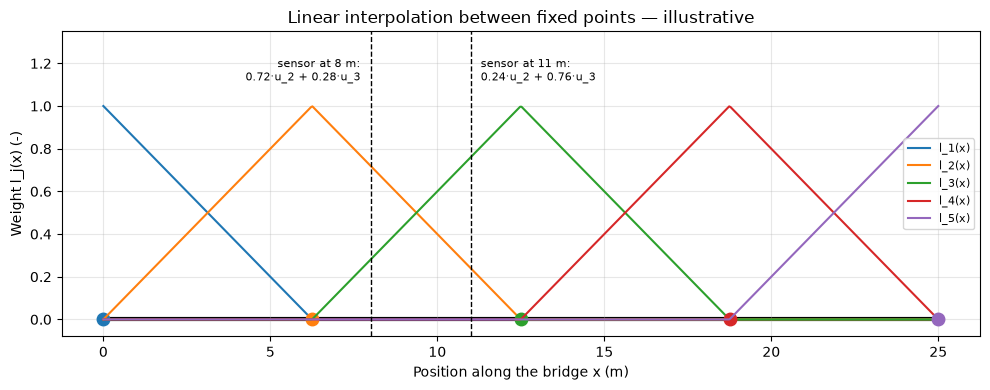

In [15]:
# Fixed points, two sensors between them and the triangular interpolation functions (illustrative)
ds_m = 100.0 / 16                               # spacing of 17 fixed points on a 100 m bridge, m
s_m = np.arange(0, 5) * ds_m                    # first five fixed points, m
x_grid = np.linspace(0, s_m[-1], 600)
sensors_m = [8.0, 11.0]                         # two sensors (the axles of one vehicle, 3 m apart), m

def hat(x, sj, ds):
    """Interpolation function of fixed point sj (Eq. 25)."""
    return np.clip(1 - np.abs(x - sj) / ds, 0, None)

fig, ax = plt.subplots(figsize=(10, 4))
for j, sj in enumerate(s_m):
    ax.plot(x_grid, hat(x_grid, sj, ds_m), color=f"C{j}", lw=1.5, label=f"l_{j + 1}(x)")
    ax.plot(sj, 0, "o", color=f"C{j}", ms=9)
for xs in sensors_m:
    ax.axvline(xs, color="k", ls="--", lw=1)
    w = [hat(xs, sj, ds_m) for sj in s_m]
    nz = [j for j in range(len(s_m)) if w[j] > 0]
    left = xs == sensors_m[0]
    ax.text(xs - 0.3 if left else xs + 0.3, 1.12,
            f"sensor at {xs:.0f} m:\n" + " + ".join(f"{w[j]:.2f}·u_{j + 1}" for j in nz),
            ha="right" if left else "left", fontsize=8)
ax.plot([0, s_m[-1]], [0, 0], "k", lw=3, zorder=0)
ax.set_xlabel("Position along the bridge x (m)")
ax.set_ylabel("Weight l_j(x) (-)")
ax.set_ylim(-0.08, 1.35)
ax.set_title("Linear interpolation between fixed points — illustrative")
ax.legend(loc="center right", fontsize=8)
fig.tight_layout()
plt.show()

**Figura 14.** Funciones de interpolación de los primeros cinco puntos fijos de un puente de 100 m con 17 puntos fijos ($\Delta s=6.25$ m) y dos sensores (ilustrativo). Cada triángulo es una $l_j(x)$ (Ec. 25). Un sensor en $x=8$ m reparte su medición entre los puntos 2 y 3 con pesos que suman 1; es una fila de $\mathbf{L}(t)$ (Ec. 26).

- Los puntos 2 y 3 tienen a los dos sensores dentro de su triángulo; según la regla de dos mediciones, los dos son válidos en este instante. Los puntos 1, 4 y 5 quedan como faltantes.

**Ejemplo sintético.** Cinco vehículos con sensor en los dos ejes ($d=3$ m) cruzan el puente de 100 m a 25 m/s, en instantes al azar durante 40 s. En cada instante se arma $\mathbf{L}(t)$, se estima la respuesta con la Ec. 28 ($\lambda=10^{-6}$) y se marca como válido cada punto fijo cuya columna de $\mathbf{L}(t)$ tiene al menos dos valores distintos de cero. La respuesta del puente es el modo 1 a 1.44 Hz.

Missing cells: 95.5 %
Relative error at the valid cells: 6.3 %


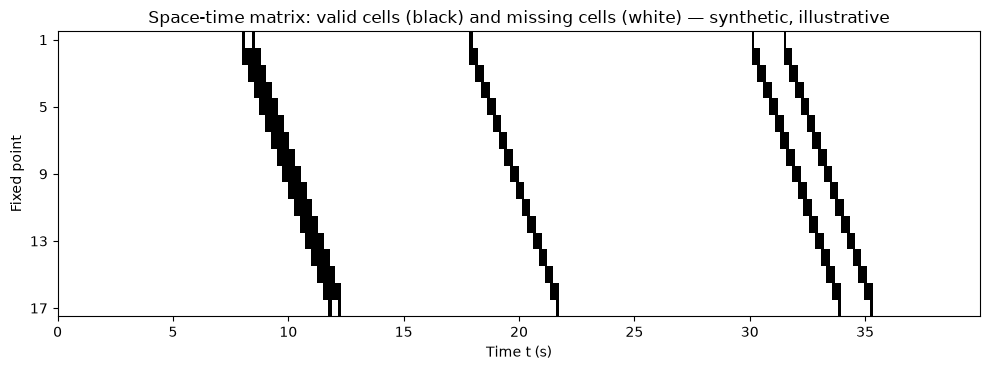

In [16]:
# Space-time matrix of 17 fixed points: valid and missing cells (illustrative)
rng_map = np.random.default_rng(SEED + 13)
L_m, v_m, d_m, fs_m = 100.0, 25.0, 3.0, 50.0
s_all = np.linspace(0, L_m, 17)                 # 17 fixed points, m
t_m = np.arange(0, 40, 1 / fs_m)
entries = np.sort(rng_map.uniform(0, 40 - L_m / v_m, 5))   # entry time of each vehicle, s
q_m = modal_response([1.44], 0.02, fs_m, t_m.size, rng_map)[0]
lam_m = 1e-6

valid_m = np.zeros((17, t_m.size), dtype=bool)
est_m = np.zeros((17, t_m.size))
for n, tn in enumerate(t_m):
    xs = [v_m * (tn - te) - off for te in entries for off in (0.0, d_m)]     # front and rear axles
    xs = [x for x in xs if 0 <= x <= L_m]
    if not xs:
        continue
    Lt = np.array([hat(x, s_all, s_all[1] - s_all[0]) for x in xs])       # one row per sensor (Eq. 26)
    meas = np.sin(np.pi * np.array(xs) / L_m) * q_m[n]                    # what each sensor measures
    est_m[:, n] = np.linalg.solve(Lt.T @ Lt + lam_m * np.eye(17), Lt.T @ meas)   # Eq. 28
    valid_m[:, n] = (Lt > 0).sum(axis=0) >= 2                             # rule: >= 2 sensors near the point
true_m = np.sin(np.pi * s_all / L_m)[:, None] * q_m[None, :]
err_m = np.linalg.norm((est_m - true_m)[valid_m]) / np.linalg.norm(true_m[valid_m])
print(f"Missing cells: {100 * (1 - valid_m.mean()):.1f} %")
print(f"Relative error at the valid cells: {100 * err_m:.1f} %")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.imshow(valid_m, aspect="auto", cmap="Greys", interpolation="nearest",
          extent=[t_m[0], t_m[-1], 17.5, 0.5])
ax.set_yticks([1, 5, 9, 13, 17])
ax.set_xlabel("Time t (s)")
ax.set_ylabel("Fixed point")
ax.set_title("Space-time matrix: valid cells (black) and missing cells (white) — synthetic, illustrative")
ax.grid(False)
fig.tight_layout()
plt.show()

**Figura 15.** Matriz espacio-tiempo de 17 puntos fijos (ilustrativo, datos sintéticos): en negro, las celdas válidas; en blanco, las faltantes. Cada franja diagonal es un vehículo que cruza: en cada instante solo uno o dos puntos fijos cercanos al vehículo tienen dos sensores dentro de su triángulo. Más del 90 % de la matriz queda vacía.

- En las celdas válidas la estimación (Ec. 28) se parece a la respuesta verdadera, con un error que depende de dónde caen los dos sensores respecto al punto fijo.

**Cómo se usa en drive-by**

- **Mei et al. (2021):** 10 puntos fijos, desplazamientos, inversión con la pseudoinversa de Moore-Penrose (Ec. 27).
- **Talebi-Kalaleh et al. (2025):** 17 puntos fijos, velocidad residual / $\Delta t$ de los ejes traseros, inversión con mínimos cuadrados regularizados (Tikhonov, $\lambda=10^{-6}$, Ec. 28). La ec. 30 da valores a los 17 puntos aunque no haya ejes cerca; por eso aplican el Algoritmo 1: un punto es válido si su columna en $\mathbf{L}_r(t)$ tiene al menos dos valores distintos de cero.
- Igual en los dos: interpolación lineal y la regla de dos mediciones cercanas.

**Ventajas**

- Convierte mediciones móviles en una matriz espacio-tiempo de puntos fijos.
- La regularización estabiliza la inversión cuando la matriz es casi singular.

**Desventajas**

- Con pocos sensores, la mayor parte de la matriz queda vacía (80 % a 90 % en Talebi-Kalaleh).
- Más puntos fijos implica menos datos por punto y peores resultados.
- Necesita conocer la posición exacta de los sensores o ejes.

**Artículos:** Mei et al. (2021); Talebi-Kalaleh et al. (2025).

> **Nota de fuentes.** Del artículo de Mei vienen: la ec. 5, la pseudoinversa y los 10 puntos fijos. Del de Talebi-Kalaleh: las ecs. 19 y 30, λ = 10⁻⁶, los 17 puntos fijos y el Algoritmo 1.

**Entradas y salidas**

- **Entrada:** las mediciones de los sensores móviles y su posición en cada instante.
- **Salida:** la matriz de respuesta en puntos fijos × tiempo, con faltantes.
- **Qué se obtiene o interpreta:** la respuesta del puente en ubicaciones fijas, lista para completarse ([2.2.1.2](#soft-imputing)) o para aplicar el FDD ([2.2.1.3](#fdd-incomplete-matrix)).

[↑ Volver al índice](#indice)

<a id="soft-imputing"></a>
##### 2.2.1.2 Soft imputing

**Qué es**

- Un método para rellenar los huecos de una matriz suponiendo que es de rango bajo (que se puede explicar con pocos patrones).

**Para qué se aplica**

- La matriz espacio-tiempo de un puente tiene rango bajo, porque la respuesta es una suma de pocos modos; eso permite estimar los valores faltantes.

**Cómo funciona**

1. Se rellenan los huecos con una estimación inicial (por ejemplo, ceros).
2. Se aplica la SVD ([2.2.4.2](#svd-completed-matrix)) a la matriz rellena.
3. A cada valor singular se le resta $\lambda$, y los que quedan negativos se ponen en cero (umbral suave).
4. Se reconstruye la matriz con esos valores; los huecos se reemplazan por los nuevos valores, y los medidos se mantienen.
5. Se repite hasta que deja de cambiar.

*Relleno en cada iteración.*

$$\mathbf{X}=P_{\Omega}(\mathbf{D})+P_{\Omega}^{\perp}(\mathbf{Z}) \tag{29}$$

- $\mathbf{D}$: matriz medida (con huecos).
- $\Omega$: conjunto de celdas medidas.
- $P_{\Omega}(\mathbf{D})$: conserva los valores medidos y pone cero en los huecos.
- $P_{\Omega}^{\perp}(\mathbf{Z})$: toma la estimación actual $\mathbf{Z}$ solo en los huecos.
- $\mathbf{X}$: matriz completa que entra a la SVD.

En palabras: la matriz de trabajo tiene los datos medidos donde los hay y la última estimación donde faltan.

*Umbral suave.*

$$\sigma_i\rightarrow\max(\sigma_i-\lambda,\,0) \tag{30}$$

- $\sigma_i$: valores singulares de $\mathbf{X}$.
- $\lambda$: umbral.

En palabras: se encogen todos los valores singulares la misma cantidad; los pequeños (ruido y errores del relleno) desaparecen y los grandes (los modos) se conservan casi enteros. Con $\mathbf{U}$, $\mathbf{V}$ y los valores encogidos se arma la nueva estimación $\mathbf{Z}$.

**Ejemplo sintético.** Matriz de rango 3 (tres modos de una viga) de 40 puntos × 300 instantes, con 80 % de huecos al azar y $\lambda=0.3$.

- **Observación (propia de esta revisión):** con 80 % de huecos, cada columna (instante) necesita al menos tres datos para fijar tres patrones. Con 10 o 17 puntos, cerca del 30 % de las columnas tendría menos de tres datos y no se podría recuperar; por eso el ejemplo usa 40 puntos.

Relative error in the missing cells after 1000 iterations: 13.0 %


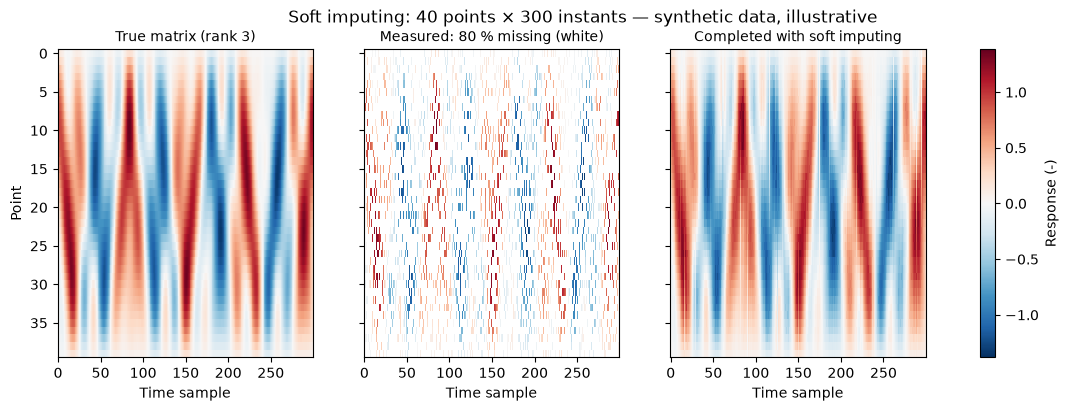

In [17]:
# Soft imputing of a rank-3 matrix with 80 % missing cells (illustrative)
def soft_impute(D_obs, mask, lam, n_iter, D_true=None):
    """Fill the missing cells of D_obs (mask = measured) with the soft-threshold SVD iteration (Eqs. 29-30)."""
    Z = np.zeros_like(D_obs)
    errors = []
    for _ in range(n_iter):
        X = np.where(mask, D_obs, Z)                         # Eq. 29
        U, s, Vt = np.linalg.svd(X, full_matrices=False)
        Z = (U * np.maximum(s - lam, 0)) @ Vt                # Eq. 30
        if D_true is not None:
            errors.append(np.linalg.norm((Z - D_true)[~mask]) / np.linalg.norm(D_true[~mask]))
    return np.where(mask, D_obs, Z), errors

rng_si = np.random.default_rng(SEED + 14)
n_si, N_si = 40, 300
x_si = np.arange(1, n_si + 1) / (n_si + 1)
t_si = np.arange(N_si) / 100.0
Q_si = np.array([a * np.sin(2 * np.pi * f * t_si + p) for a, f, p in
                 zip([1.0, 0.5, 0.25], [1.44, 3.68, 4.66], [0.3, 1.1, 2.0])])
D_si = beam_modes(x_si, 3) @ Q_si                            # true rank-3 matrix
mask80 = rng_si.random(D_si.shape) < 0.2                     # 20 % measured
D_filled, err80 = soft_impute(D_si, mask80, 0.3, 1000, D_si)
print(f"Relative error in the missing cells after {len(err80)} iterations: {100 * err80[-1]:.1f} %")

vmax = np.abs(D_si).max()
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, M, title in zip(axes, [D_si, np.where(mask80, D_si, np.nan), D_filled],
                        ["True matrix (rank 3)", "Measured: 80 % missing (white)", "Completed with soft imputing"]):
    im = ax.imshow(M, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax, interpolation="nearest")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Time sample")
    ax.grid(False)
axes[0].set_ylabel("Point")
fig.colorbar(im, ax=axes, label="Response (-)")
fig.suptitle("Soft imputing: 40 points × 300 instants — synthetic data, illustrative")
plt.show()

**Figura 16.** Matriz sintética de rango 3 (izquierda), la misma con 80 % de huecos al azar (centro) y la reconstruida con *soft imputing* (derecha) (ilustrativo, datos sintéticos). La reconstruida recupera el patrón de franjas de la verdadera; el error en los huecos se imprime arriba de la figura.

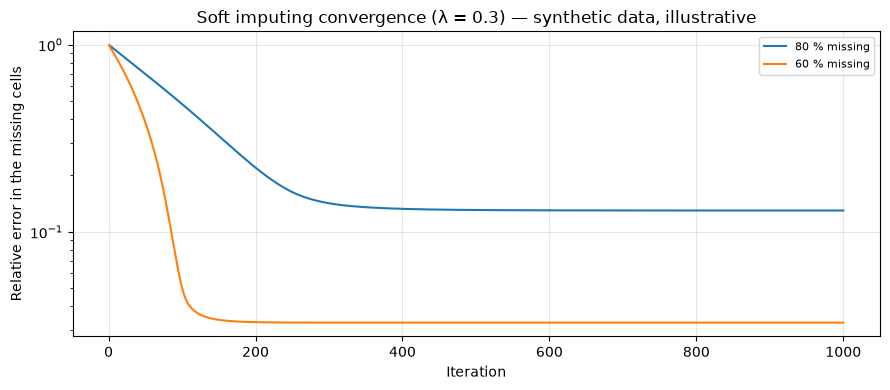

Final error: 80 % missing 13.0 %, 60 % missing 3.3 %


In [18]:
# Reconstruction error vs iterations, for 80 % and 60 % missing cells (illustrative)
mask60 = rng_si.random(D_si.shape) < 0.4                     # 40 % measured
_, err60 = soft_impute(D_si, mask60, 0.3, 1000, D_si)

fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogy(np.arange(1, 1001), err80, color="C0", label="80 % missing")
ax.semilogy(np.arange(1, 1001), err60, color="C1", label="60 % missing")
ax.set_xlabel("Iteration")
ax.set_ylabel("Relative error in the missing cells")
ax.set_title("Soft imputing convergence (λ = 0.3) — synthetic data, illustrative")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()
print(f"Final error: 80 % missing {100 * err80[-1]:.1f} %, 60 % missing {100 * err60[-1]:.1f} %")

**Figura 17.** Error de reconstrucción en los huecos contra el número de iteraciones (ilustrativo, datos sintéticos). Con 60 % de huecos el error cae rápido y llega a un valor pequeño; con 80 % baja mucho más lento y se estanca más arriba. Cada iteración corrige solo la parte de los huecos, así que con más huecos hacen falta más iteraciones; además, $\lambda$ encoge los valores singulares y deja un error que no se va.

**Cómo se usa en drive-by** (referencia: Mei et al., 2021)

- Completan la matriz de desplazamientos de $10\times 677$ y después le aplican la SVD ([2.2.4.2](#svd-completed-matrix)).

**Ventajas**

- Rellena muchos huecos aprovechando la estructura de la matriz.
- Mantiene exactos los valores medidos.

**Desventajas**

- Supone rango bajo; con mucho ruido o rugosidad el supuesto se debilita.
- Hay que escoger $\lambda$.
- Es iterativo y puede tardar en converger con muchos huecos.

**Artículos:** Mei et al. (2021).

> **Nota de fuentes.** Del artículo de Mei vienen: el uso de soft imputing, la ecuación de proyección y el umbral de los valores singulares. La explicación paso a paso es general.

**Entradas y salidas**

- **Entrada:** la matriz con huecos, el conjunto de celdas medidas y $\lambda$.
- **Salida:** la matriz completa.
- **Qué se obtiene o interpreta:** una estimación de la respuesta en todos los puntos y tiempos, lista para la SVD ([2.2.4.2](#svd-completed-matrix)).

[↑ Volver al índice](#indice)

<a id="fdd-incomplete-matrix"></a>
##### 2.2.1.3 FDD on the incomplete matrix

**Qué es**

- Aplicar el FDD ([2.1.1.3](#fdd)) directamente a la matriz con huecos, con los faltantes en cero, sin completarla.

**Cómo funciona**

- Se siguen los mismos pasos del FDD sobre la matriz dispersa de la Ec. 21. El ejemplo de la Figura 13 (en 2.1.1.3) lo aplica a datos sintéticos con 80 % de faltantes.

**Cómo se usa en drive-by** (referencia: Talebi-Kalaleh et al., 2025)

- La matriz dispersa es $\ddot{\mathbf{u}}_b(t)=\Gamma(t)\,\ddot{\mathbf{w}}_b(t)$, donde $\Gamma(t)$ es diagonal con 1 en los puntos válidos y 0 en los demás (ec. 31 del artículo; Ec. 21 de este notebook).
- A diferencia de Mei, no la rellenan.
- Con 80 % de faltantes identificaron los tres modos con MAC > 95 %. Con más puntos fijos, y por lo tanto más faltantes, empeora (33 puntos: MAC del modo 1 ≈ 88 %).

**Ventajas**

- Evita el paso de completar la matriz.

**Desventajas**

- Los resultados empeoran cuando aumentan los faltantes.

**Pregunta abierta**

> ¿Por qué la matriz incompleta, con los faltantes en cero, no afecta los resultados del FDD?

**Artículos:** Talebi-Kalaleh et al. (2025).

> **Nota de fuentes.** Todo viene del artículo: ec. 31, faltantes en cero y resultados del caso base y del análisis de puntos fijos.

**Entradas y salidas**

- **Entrada:** la matriz dispersa con faltantes en cero.
- **Salida:** frecuencias y formas modales (como en el FDD).
- **Qué se obtiene o interpreta:** los modos del puente sin necesidad de completar la matriz.

[↑ Volver al índice](#indice)

<a id="mode-shapes-signal-decomposition"></a>
#### 2.2.2 Signal decomposition

<a id="emd-hilbert"></a>
##### 2.2.2.1 EMD + Hilbert transform

**Qué es**

- La EMD (*Empirical Mode Decomposition*, descomposición empírica en modos) separa una señal en componentes llamadas IMF (*Intrinsic Mode Functions*, funciones de modo intrínseco), de la oscilación más rápida a la más lenta, más una tendencia final.
- Es **adaptativa**: no usa una base fija (como el seno de Fourier o la wavelet madre); las componentes salen de la propia señal.
- La **transformada de Hilbert** se aplica después a cada IMF para obtener su amplitud y su frecuencia en cada instante.
- Juntas forman la transformada de Hilbert-Huang (HHT, *Hilbert-Huang transform*).

**Qué es una IMF** (dos condiciones)

1. El número de extremos y el número de cruces por cero difieren como máximo en uno.
2. En cada instante, la media entre la envolvente superior y la inferior es cero.

Con eso, cada IMF es una oscilación "limpia", parecida a un seno, pero con amplitud y frecuencia que pueden cambiar en el tiempo.

**Para qué se aplica**

- En señales **no lineales y no estacionarias**, donde las frecuencias o amplitudes cambian en el tiempo.
- En *drive-by*: para aislar la componente de un modo del puente y seguir cómo cambia su amplitud mientras el vehículo avanza.

**Cómo funciona**

EMD (proceso de *sifting*, "cernido"):

1. Se buscan los máximos y mínimos locales de la señal.
2. Se unen los máximos con un spline cúbico (envolvente superior) y los mínimos con otro (envolvente inferior).
3. Se calcula la media de las dos envolventes y se resta de la señal.
4. Se repite sobre el resultado hasta que cumpla las condiciones de IMF (criterio de parada). Esa es la primera IMF, la más rápida.
5. Se resta la IMF de la señal original y se repite todo sobre lo que queda (el residuo), para sacar la siguiente IMF, más lenta.
6. Se para cuando el residuo ya no oscila (es monótono): esa es la tendencia.

Hilbert:

7. A cada IMF se le aplica la transformada de Hilbert, que desfasa cada componente un cuarto de periodo ($\pi/2$).
8. Con la IMF y su transformada se forma la señal analítica, de donde salen la amplitud instantánea (envolvente) y la frecuencia instantánea.

*Resultado de la EMD (pasos 1–6).*

$$x(t)=\sum_{i=1}^{n} c_i(t) + r_n(t) \tag{31}$$

- $x(t)$: señal medida.
- $c_i(t)$: la IMF número $i$ ($i=1$ es la más rápida).
- $n$: número de IMFs.
- $r_n(t)$: residuo final o tendencia (ya no oscila).

En palabras: la señal es exactamente la suma de sus IMFs más la tendencia; la EMD no pierde nada, solo reparte la señal en capas.

*Un paso de sifting (pasos 2–3).*

$$m(t)=\frac{e_{\max}(t)+e_{\min}(t)}{2},\qquad h(t)=x(t)-m(t) \tag{32}$$

- $e_{\max}(t)$: envolvente superior (spline cúbico por los máximos).
- $e_{\min}(t)$: envolvente inferior (spline cúbico por los mínimos).
- $m(t)$: media de las dos envolventes.
- $h(t)$: candidato a IMF, lo que queda al quitar la media.

En palabras: se quita a la señal la línea que pasa por el centro de sus oscilaciones; lo que queda oscila alrededor de cero.

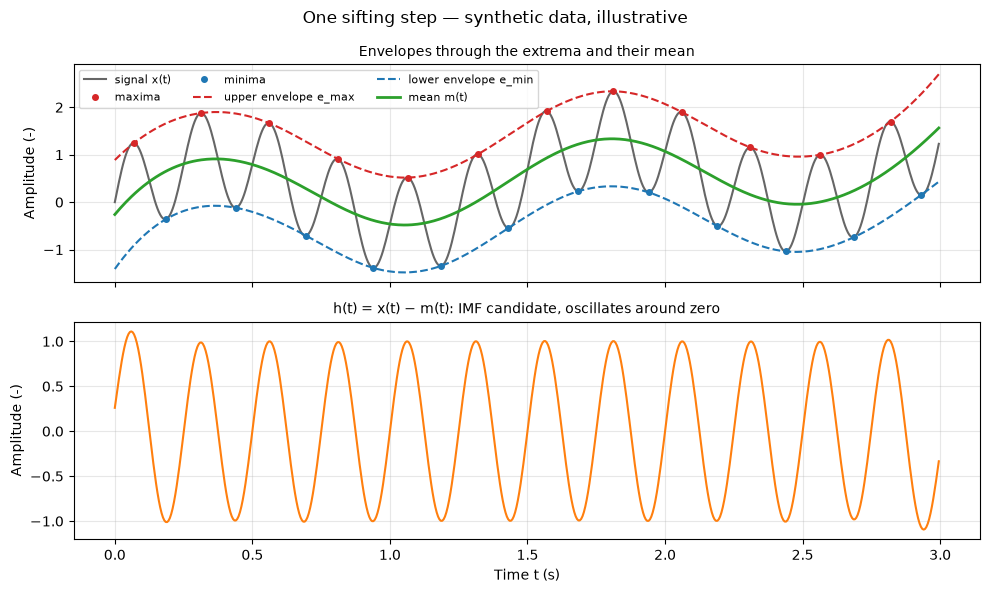

In [19]:
# One sifting step on a synthetic signal (illustrative)
fs_s = 200.0                            # sampling rate, Hz
t_s = np.arange(0, 3, 1 / fs_s)         # time, s
x_s = np.sin(2 * np.pi * 4 * t_s) + 0.8 * np.sin(2 * np.pi * 0.7 * t_s) + 0.3 * t_s

i_max = argrelextrema(x_s, np.greater)[0]     # local maxima
i_min = argrelextrema(x_s, np.less)[0]        # local minima
e_max = CubicSpline(t_s[i_max], x_s[i_max])(t_s)   # upper envelope
e_min = CubicSpline(t_s[i_min], x_s[i_min])(t_s)   # lower envelope
m_s = (e_max + e_min) / 2                     # mean envelope (Eq. 32)
h_s = x_s - m_s                               # IMF candidate (Eq. 32)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax = axes[0]
ax.plot(t_s, x_s, color="0.4", label="signal x(t)")
ax.plot(t_s[i_max], x_s[i_max], "o", color="C3", ms=4, label="maxima")
ax.plot(t_s[i_min], x_s[i_min], "o", color="C0", ms=4, label="minima")
ax.plot(t_s, e_max, "--", color="C3", label="upper envelope e_max")
ax.plot(t_s, e_min, "--", color="C0", label="lower envelope e_min")
ax.plot(t_s, m_s, color="C2", lw=2, label="mean m(t)")
ax.set_ylabel("Amplitude (-)")
ax.set_title("Envelopes through the extrema and their mean", fontsize=10)
ax.legend(loc="upper left", fontsize=8, ncol=3)
axes[1].plot(t_s, h_s, color="C1")
axes[1].set_ylabel("Amplitude (-)")
axes[1].set_xlabel("Time t (s)")
axes[1].set_title("h(t) = x(t) − m(t): IMF candidate, oscillates around zero", fontsize=10)
fig.suptitle("One sifting step — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 18.** Un paso de *sifting* sobre una señal sintética (ilustrativo): arriba, la señal con sus máximos y mínimos, las dos envolventes (splines cúbicos) y su media; abajo, la señal menos la media, que ya oscila alrededor de cero. Cerca de los bordes las envolventes se doblan porque no hay extremos más allá: es el efecto de borde.

*Descomposición completa (pasos 4–6).* Repitiendo el *sifting* hasta cumplir las condiciones de IMF, y luego sobre cada residuo, se obtiene la Ec. 31. La señal de prueba suma una oscilación rápida de 8 Hz con amplitud variable, una lenta de 1.2 Hz, una tendencia lineal y ruido.

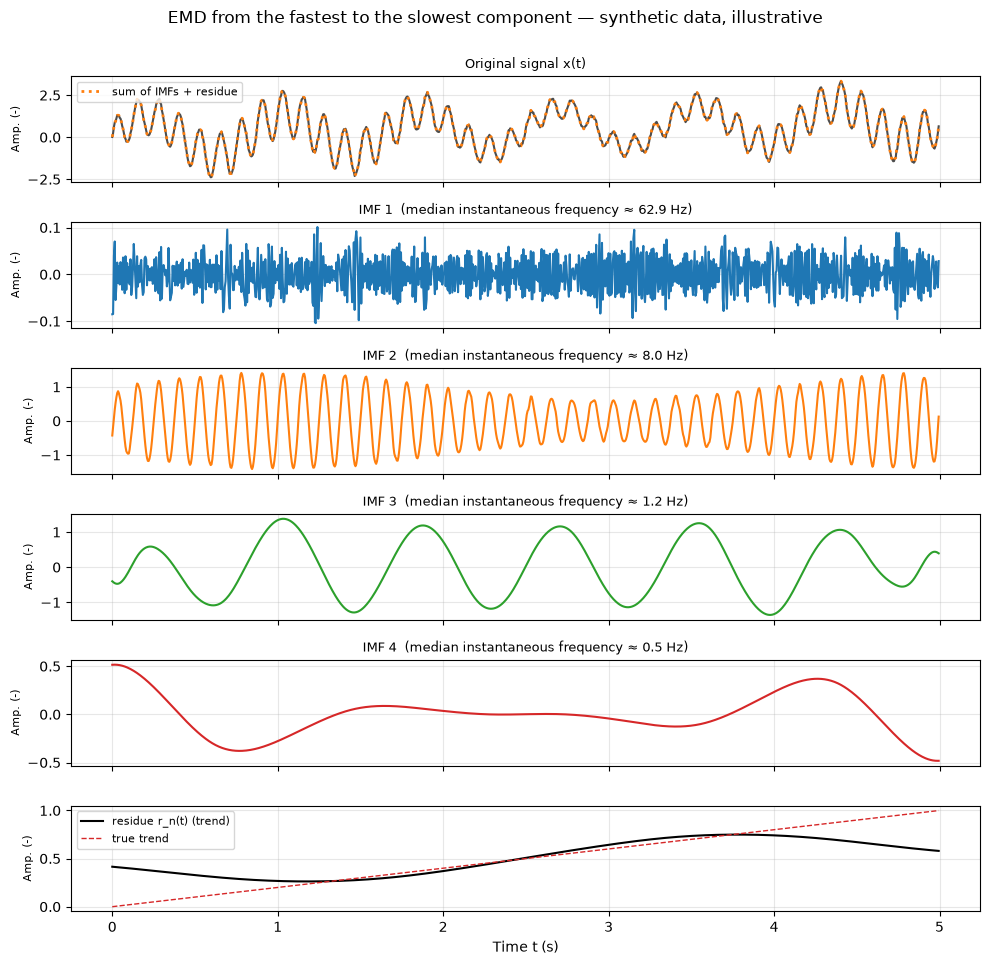

Number of IMFs: 4
Max reconstruction error |x - (sum c_i + r_n)|: 1.1e-16


In [20]:
# Full EMD of a synthetic signal (illustrative)
rng_emd = np.random.default_rng(SEED)   # own generator: keeps the other sections unchanged
fs_e = 200.0                            # sampling rate, Hz
t_e = np.arange(0, 5, 1 / fs_e)         # time, s
fast = (1 + 0.4 * np.sin(2 * np.pi * 0.25 * t_e)) * np.sin(2 * np.pi * 8 * t_e)   # 8 Hz, varying amplitude
slow = 1.2 * np.sin(2 * np.pi * 1.2 * t_e)                                        # 1.2 Hz
trend = 0.2 * t_e
x_e = fast + slow + trend + 0.05 * rng_emd.standard_normal(t_e.size)

emd = EMD()
emd.emd(x_e, t_e)
imfs, residue = emd.get_imfs_and_residue()
n_imf = imfs.shape[0]
reconstruction = imfs.sum(axis=0) + residue    # Eq. 31

fig, axes = plt.subplots(n_imf + 2, 1, figsize=(10, 1.6 * (n_imf + 2)), sharex=True)
axes[0].plot(t_e, x_e, color="0.3")
axes[0].set_title("Original signal x(t)", fontsize=9)
for i in range(n_imf):
    _, f_i = instantaneous_attributes(imfs[i], fs_e)
    axes[i + 1].plot(t_e, imfs[i], color=f"C{i}")
    axes[i + 1].set_title(f"IMF {i + 1}  (median instantaneous frequency ≈ {np.median(f_i):.1f} Hz)", fontsize=9)
axes[-1].plot(t_e, residue, color="k", label="residue r_n(t) (trend)")
axes[-1].plot(t_e, trend, "--", color="C3", lw=1, label="true trend")
axes[-1].legend(loc="upper left", fontsize=8)
for ax in axes:
    ax.set_ylabel("Amp. (-)", fontsize=8)
axes[-1].set_xlabel("Time t (s)")
axes[0].plot(t_e, reconstruction, ":", color="C1", lw=2, label="sum of IMFs + residue")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("EMD from the fastest to the slowest component — synthetic data, illustrative", y=1.0)
fig.tight_layout()
plt.show()
print(f"Number of IMFs: {n_imf}")
print(f"Max reconstruction error |x - (sum c_i + r_n)|: {np.max(np.abs(x_e - reconstruction)):.1e}")

**Figura 19.** EMD de una señal sintética (ilustrativo): de arriba abajo, la señal original (con la reconstrucción punteada encima), las IMFs de la más rápida a la más lenta y el residuo comparado con la tendencia verdadera.

- La IMF 1 recoge el ruido, la IMF 2 la oscilación de 8 Hz y la IMF 3 la de 1.2 Hz. La IMF 4 es una oscilación lenta y pequeña que sobra de la tendencia y de los bordes.
- El residuo se aparta de la tendencia verdadera porque parte de ella quedó en la IMF 4: es un caso de mezcla de modos, que se repite en señales cortas.
- La suma de todas las IMFs más el residuo reproduce la señal original (error del orden de la precisión numérica): es la Ec. 31.

*Hilbert (pasos 7–8).*

$$\mathcal{H}[c](t)=\frac{1}{\pi}\,\mathrm{PV}\!\int_{-\infty}^{\infty}\frac{c(\tau)}{t-\tau}\,d\tau \tag{33}$$

- $\mathcal{H}[c](t)$: transformada de Hilbert de la IMF $c$ en el instante $t$.
- $c(\tau)$: la IMF, evaluada en cada instante $\tau$ de la integral.
- $\mathrm{PV}$: valor principal de Cauchy; la integral se evalúa excluyendo simétricamente el punto $\tau=t$, donde el denominador se anula.
- $1/\pi$: constante de normalización.

En palabras: produce una copia de la IMF desfasada un cuarto de periodo ($\pi/2$) en cada componente; un coseno se vuelve seno.

$$z(t)=c(t)+i\,\mathcal{H}[c](t)=A(t)\,e^{i\theta(t)} \tag{34}$$

$$A(t)=\sqrt{c(t)^2+\mathcal{H}[c](t)^2},\qquad f(t)=\frac{1}{2\pi}\frac{d\theta}{dt} \tag{35}$$

- $z(t)$: señal analítica (compleja): la IMF como parte real y su transformada de Hilbert como parte imaginaria.
- $i$: unidad imaginaria.
- $A(t)$: amplitud instantánea o envolvente.
- $\theta(t)$: fase instantánea, en rad.
- $f(t)$: frecuencia instantánea, en Hz.

En palabras: la IMF y su copia desfasada son como las dos coordenadas de un punto que gira; el radio del giro es la amplitud y la velocidad del giro es la frecuencia, en cada instante.

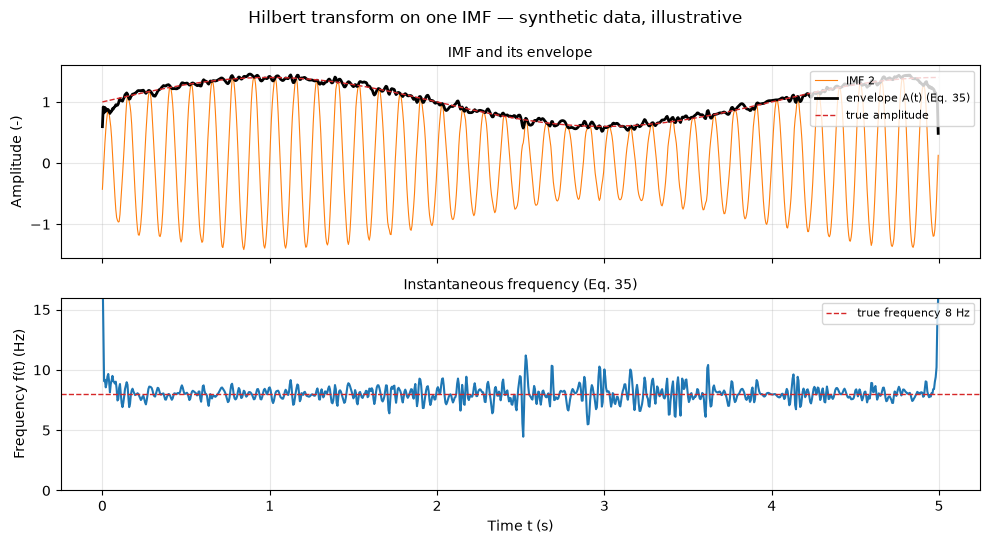

In [21]:
# Hilbert transform on the 8 Hz IMF of Fig. 19 (illustrative)
f_target = 8.0
medians = [np.median(instantaneous_attributes(c, fs_e)[1]) for c in imfs]
k_fast = int(np.argmin(np.abs(np.array(medians) - f_target)))   # IMF closest to 8 Hz
amp_fast, freq_fast = instantaneous_attributes(imfs[k_fast], fs_e)
true_env = 1 + 0.4 * np.sin(2 * np.pi * 0.25 * t_e)

fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
axes[0].plot(t_e, imfs[k_fast], color="C1", lw=0.8, label=f"IMF {k_fast + 1}")
axes[0].plot(t_e, amp_fast, color="k", lw=2, label="envelope A(t) (Eq. 35)")
axes[0].plot(t_e, true_env, "--", color="C3", lw=1, label="true amplitude")
axes[0].set_ylabel("Amplitude (-)")
axes[0].set_title("IMF and its envelope", fontsize=10)
axes[0].legend(loc="upper right", fontsize=8)
axes[1].plot(t_e, freq_fast, color="C0")
axes[1].axhline(f_target, color="C3", ls="--", lw=1, label="true frequency 8 Hz")
axes[1].set_ylim(0, 16)
axes[1].set_ylabel("Frequency f(t) (Hz)")
axes[1].set_xlabel("Time t (s)")
axes[1].set_title("Instantaneous frequency (Eq. 35)", fontsize=10)
axes[1].legend(loc="upper right", fontsize=8)
fig.suptitle("Hilbert transform on one IMF — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 20.** Transformada de Hilbert sobre la IMF de 8 Hz (ilustrativo): arriba, la IMF con su envolvente $A(t)$, que sigue la amplitud verdadera; abajo, la frecuencia instantánea $f(t)$, que se mantiene cerca de 8 Hz.

- En los extremos la frecuencia se dispara y la envolvente se deforma: es el efecto de borde de la EMD y de la transformada de Hilbert.

**Cómo se usa para la forma modal** (referencia: Malekjafarian y OBrien, 2017)

- Se escoge la IMF cuya frecuencia instantánea se mantiene cerca de la frecuencia del modo buscado (en el artículo, la frecuencia a la que se sintonizó un excitador en el vehículo).
- Su amplitud instantánea, expresada contra la posición del vehículo, indica cuánto se mueve ese modo en cada punto.
- En el artículo, la envolvente se suaviza con un promedio móvil y se recortan los extremos. Luego se usa en el reescalado entre ejes para construir la forma modal (eso es otro paso del mapa, [2.2.4.1](#rescaling-between-axles); aquí solo se menciona).

**Ejemplo sintético.** Un vehículo cruza una viga simplemente apoyada de $L=15$ m a $v=2$ m/s (cruce de 7.5 s). La señal es:

$x(t)=|\phi(v\,t)|\cos(2\pi f_b t)+\text{componente del vehículo}+\text{ruido}$

- $f_b=5.65$ Hz y $\phi(x)=\sin(\pi x/L)$: primer modo de la viga.
- La componente del vehículo es una oscilación de 1.5 Hz (valor inventado para el ejemplo).
- La luz, la velocidad y $f_b$ coinciden con el caso que estudia el artículo, pero la señal es sintética: no reproduce sus datos ni sus resultados.
- Promedio móvil de 0.5 s y recorte de 0.5 s (1 m) en cada extremo: valores escogidos para el ejemplo.

Median instantaneous frequency of each IMF (Hz): [32.07  5.7   1.51  0.98  0.52]
Selected IMF: 2 (closest to f_b = 5.65 Hz)
RMS error vs |phi| on the trimmed part: 0.047


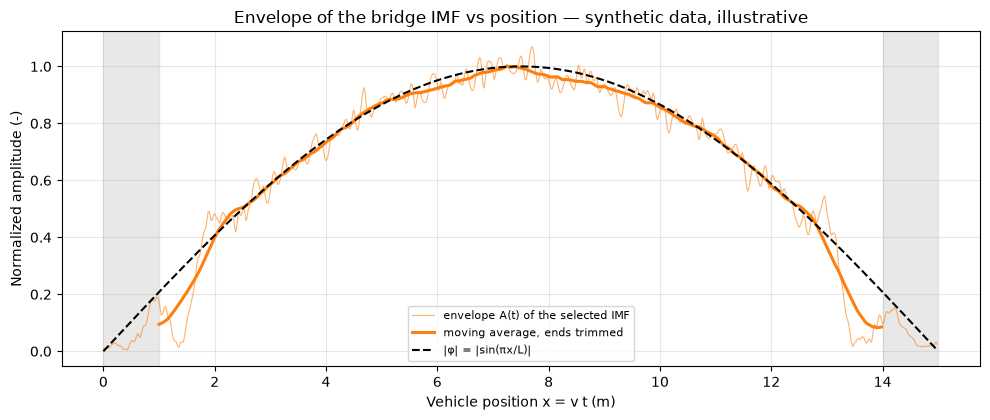

In [22]:
# Drive-by example: 15 m simply supported beam crossed at 2 m/s (illustrative)
rng_db = np.random.default_rng(SEED)
L_b = 15.0                              # span length, m
v_b = 2.0                               # vehicle speed, m/s
f_b = 5.65                              # bridge mode 1 frequency, Hz
f_veh = 1.5                             # vehicle component frequency, Hz (made up)
fs_b = 100.0                            # sampling rate, Hz

t_b = np.arange(0, L_b / v_b, 1 / fs_b) # time, s
pos_b = v_b * t_b                       # vehicle position, m
phi_b = np.sin(np.pi * pos_b / L_b)     # mode 1 shape
x_b = (np.abs(phi_b) * np.cos(2 * np.pi * f_b * t_b)
       + 0.8 * np.sin(2 * np.pi * f_veh * t_b)
       + 0.05 * rng_db.standard_normal(t_b.size))

emd_b = EMD()
emd_b.emd(x_b, t_b)
imfs_b, _ = emd_b.get_imfs_and_residue()
medians_b = np.array([np.median(instantaneous_attributes(c, fs_b)[1]) for c in imfs_b])
k_b = int(np.argmin(np.abs(medians_b - f_b)))          # IMF closest to the bridge frequency
amp_b, _ = instantaneous_attributes(imfs_b[k_b], fs_b)

win = int(0.5 * fs_b)                                  # moving-average window: 0.5 s
amp_smooth = np.convolve(amp_b, np.ones(win) / win, mode="same")
inner = slice(win, -win)                               # trim 0.5 s at each end
amp_norm = amp_smooth / amp_smooth[inner].max()

print("Median instantaneous frequency of each IMF (Hz):", np.round(medians_b, 2))
print(f"Selected IMF: {k_b + 1} (closest to f_b = {f_b} Hz)")
rms = np.sqrt(np.mean((amp_norm[inner] - np.abs(phi_b[inner])) ** 2))
print(f"RMS error vs |phi| on the trimmed part: {rms:.3f}")

fig, ax = plt.subplots(figsize=(10, 4.3))
ax.plot(pos_b, amp_b / amp_smooth[inner].max(), color="C1", lw=0.8, alpha=0.6, label="envelope A(t) of the selected IMF")
ax.plot(pos_b[inner], amp_norm[inner], color="C1", lw=2.2, label="moving average, ends trimmed")
ax.plot(pos_b, np.abs(phi_b), "k--", lw=1.5, label="|φ| = |sin(πx/L)|")
for edge in [(0, pos_b[win]), (pos_b[-win], L_b)]:
    ax.axvspan(*edge, color="0.85", alpha=0.6)
ax.set_xlabel("Vehicle position x = v t (m)")
ax.set_ylabel("Normalized amplitude (-)")
ax.set_title("Envelope of the bridge IMF vs position — synthetic data, illustrative")
ax.legend(loc="lower center", fontsize=8)
fig.tight_layout()
plt.show()

**Figura 21.** Envolvente de la IMF del puente contra la posición del vehículo, comparada con $|\phi|$ (ilustrativo, datos sintéticos): la EMD separa el modo de 5.65 Hz de la componente del vehículo, y su envolvente suavizada sigue la forma del primer modo. Las franjas grises son los extremos recortados, donde actúa el efecto de borde.

- La envolvente no tiene signo; con el primer modo no se nota porque $\phi$ es positiva en toda la luz.

**Ventajas**

- Adaptativa: no necesita escoger una base ni una wavelet madre.
- Funciona con señales no lineales y no estacionarias.
- Da amplitud y frecuencia en cada instante, con muy buena resolución en el tiempo.

**Desventajas**

- **Mezcla de modos:** una IMF puede contener oscilaciones de escalas distintas, o una misma oscilación puede repartirse entre dos IMFs.
- **Efectos de borde:** los splines se deforman en los extremos de la señal (por eso en el artículo se recortan los extremos).
- Sensible al ruido; el resultado depende del criterio de parada.
- No tiene una base matemática cerrada; es un algoritmo empírico.
- Hilbert solo da una frecuencia con sentido físico si la IMF tiene una sola componente (banda estrecha).
- Para formas modales hay que saber qué frecuencia buscar.
- Existen variantes que reducen la mezcla de modos, como EEMD (*Ensemble EMD*) y CEEMDAN (*Complete Ensemble EMD with Adaptive Noise*).

**Pregunta abierta**

> La EMD da IMFs parecidas a ondas seno, y por eso Hilbert funciona. Pero una señal real viene de muchas fuentes, y no todas son de tipo seno. Si alguna no lo es, ¿queda en el residuo o se mezcla en las IMFs y las distorsiona?

**Artículos:** Malekjafarian y OBrien (2017).

> **Nota de fuentes.** La explicación general de la EMD, las condiciones de IMF, la transformada de Hilbert, la mezcla de modos y las variantes EEMD/CEEMDAN es conocimiento general, no del artículo. Del artículo vienen: la descomposición en IMFs de la más rápida a la más lenta, el uso de Hilbert para la frecuencia instantánea y la selección de la IMF cercana a la frecuencia de excitación, y la envolvente contra la posición suavizada con promedio móvil y recortada en los extremos.

**Entradas y salidas**

- **Entrada:**
  - Una señal de aceleración contra tiempo, de un solo canal, con su frecuencia de muestreo.
  - El criterio de parada del *sifting* y, si se quiere, el número máximo de IMFs.
  - Para formas modales, además: la posición del vehículo en cada instante y la frecuencia del modo que se busca.
- **Salida:**
  - Un conjunto de IMFs $c_i(t)$ más un residuo.
  - Para cada IMF, su amplitud instantánea $A_i(t)$ y su frecuencia instantánea $f_i(t)$.
- **Qué se obtiene o interpreta:**
  - Qué oscilaciones componen la señal y cómo cambia la frecuencia de cada una en el tiempo.
  - Cuál IMF corresponde al modo del puente (la que se mantiene cerca de su frecuencia).
  - La envolvente de esa IMF contra la posición: cómo cambia la amplitud del modo a lo largo del puente, que es la base para construir la forma modal.

[↑ Volver al índice](#indice)

<a id="fdd-mode-shapes"></a>
##### 2.2.2.2 FDD (Frequency Domain Decomposition)

Se explica en [2.1.1.3](#fdd). Aquí, además de las frecuencias, se usa el vector singular en cada pico como forma modal.

<a id="wavelet-sswt"></a>
##### 2.2.2.3 Wavelet transform (SSWT)

SSWT: *synchrosqueezed wavelet transform*, transformada wavelet sincro-comprimida. Parte de la CWT (*continuous wavelet transform*, transformada wavelet continua).

**Qué es**

- La transformada wavelet descompone una señal en frecuencias, como Fourier, pero además dice **en qué momento** aparece cada frecuencia.
- La versión sincro-comprimida (SSWT) concentra mejor la energía en cada frecuencia, por lo que el mapa sale más nítido.

**Para qué se aplica**

- En señales **cortas o no estacionarias**, donde las frecuencias o sus amplitudes cambian en el tiempo.
- En *drive-by*: para ver cómo cambia la amplitud de una frecuencia del puente mientras el carro avanza, y con eso construir la forma modal.

**Cómo funciona**

1. Se escoge una **wavelet madre**: una onda corta que oscila y se apaga hacia los lados. La más usada en vibraciones es la Morlet.
2. Para cada frecuencia, la wavelet se **estira o se comprime** y se coloca en cada instante de la señal.
3. En cada posición se **multiplica punto por punto** con la señal y se suma: si la señal oscila a esa frecuencia en ese momento, el resultado es grande; si no, es casi cero.
4. Así se llena un **mapa frecuencia contra tiempo**, donde cada celda es una amplitud.

*Paso 1: la wavelet madre Morlet.*

$$\psi(t)=\pi^{-1/4}\,e^{i\omega_0 t}\,e^{-t^{2}/2} \tag{36}$$

- $\psi(t)$: wavelet madre Morlet (valor complejo) en el instante $t$.
- $t$: tiempo de la wavelet madre, en s.
- $i$: unidad imaginaria.
- $\omega_0$: frecuencia central (adimensional); fija cuántas oscilaciones caben dentro de la campana. Valor típico: $\omega_0 \approx 6$.
- $e^{i\omega_0 t}=\cos(\omega_0 t)+i\,\sin(\omega_0 t)$: la **oscilación**.
- $e^{-t^{2}/2}$: la **campana** gaussiana que apaga la oscilación hacia los lados.
- $\pi^{-1/4}$: constante para que la wavelet tenga energía unitaria.

En palabras: una onda que oscila a $\omega_0$ multiplicada por una campana; oscila en el centro y se apaga hacia los lados.

*Paso 2: estirar o comprimir.* La wavelet se usa como $\psi\!\left(\frac{t-b}{a}\right)$: la escala $a$ la estira o la comprime y $b$ la desplaza en el tiempo. La frecuencia a la que oscila depende de la escala:

$$f=\frac{\omega_0}{2\pi a} \tag{37}$$

- $f$: frecuencia a la que oscila la wavelet estirada, en Hz.
- $a$: escala, en s; $a>1$ estira la wavelet y $a<1$ la comprime.
- $\omega_0$: frecuencia central de la Morlet (Ec. 36).
- $2\pi$: pasa de radianes por segundo a ciclos por segundo (Hz).

En palabras: escala grande = wavelet estirada = frecuencia baja; escala pequeña = wavelet comprimida = frecuencia alta.

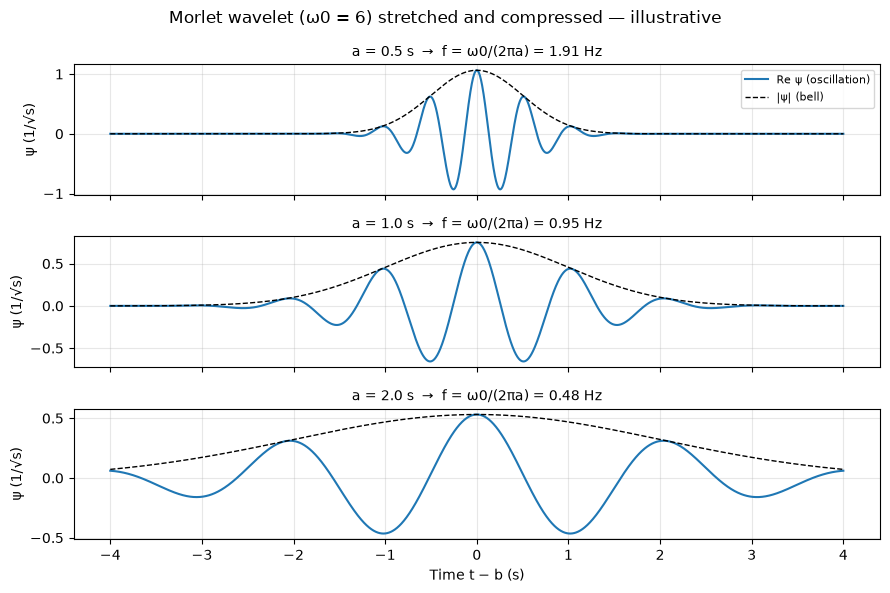

In [23]:
# Real part of the Morlet wavelet at three scales (illustrative)
w0 = 6.0
t = np.linspace(-4, 4, 2000)            # time around the wavelet center, s
scales = [0.5, 1.0, 2.0]                # scale a, s

fig, axes = plt.subplots(len(scales), 1, figsize=(9, 6), sharex=True)
for ax, a in zip(axes, scales):
    psi = scaled_wavelet(t, a, b=0.0, w0=w0)
    f = w0 / (2 * np.pi * a)            # Eq. 37
    ax.plot(t, psi.real, color="C0", label="Re ψ (oscillation)")
    ax.plot(t, np.abs(psi), "k--", lw=1, label="|ψ| (bell)")
    ax.set_ylabel("ψ (1/√s)")
    ax.set_title(f"a = {a} s  →  f = ω0/(2πa) = {f:.2f} Hz", fontsize=10)
axes[0].legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel("Time t − b (s)")
fig.suptitle("Morlet wavelet (ω0 = 6) stretched and compressed — illustrative")
fig.tight_layout()
plt.show()

**Figura 22.** Parte real de la wavelet Morlet a tres escalas (ilustrativo): con $a$ pequeña la wavelet se comprime y oscila rápido (frecuencia alta); con $a$ grande se estira y oscila lento (frecuencia baja). La línea discontinua es la campana que la apaga hacia los lados.

*Paso 3: multiplicar y sumar.* Para una escala $a$ y un instante $b$, el coeficiente wavelet es:

$$W(a,b)=\frac{1}{\sqrt{a}}\int_{-\infty}^{\infty} x(t)\,\psi^{*}\!\left(\frac{t-b}{a}\right)dt \tag{38}$$

- $W(a,b)$: coeficiente wavelet (complejo) en la escala $a$ y el instante $b$; $|W(a,b)|$ es la **amplitud** de esa celda del mapa.
- $x(t)$: señal medida.
- $\psi$: wavelet madre (Ec. 36); $^{*}$ indica el conjugado complejo.
- $a$: escala, en s (fija la frecuencia, Ec. 37).
- $b$: desplazamiento en el tiempo: instante donde se centra la wavelet, en s.
- $1/\sqrt{a}$: normalización para que la wavelet tenga la misma energía en todas las escalas.
- $\int \dots\, dt$: multiplicar punto por punto la señal por la wavelet y sumar.

En palabras: mide cuánto se parece la señal, alrededor del instante $b$, a una oscilación de la frecuencia que corresponde a la escala $a$.

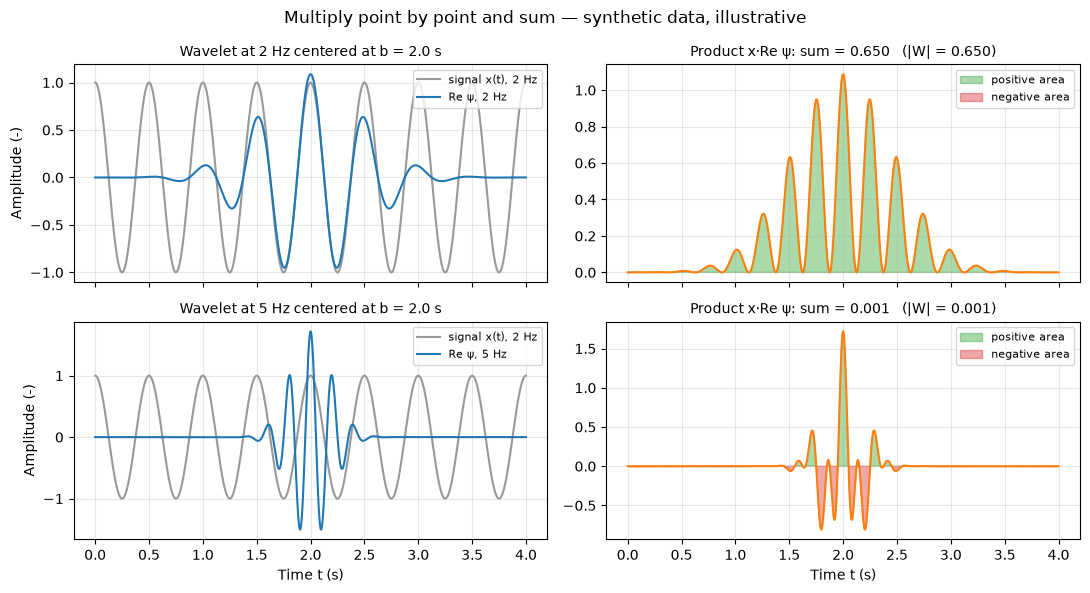

In [24]:
# "Multiply and sum": cosine at 2 Hz vs wavelets at 2 Hz and 5 Hz (illustrative)
dt = 0.001
t = np.arange(0, 4, dt)                 # time, s
f_signal = 2.0                          # signal frequency, Hz
x = np.cos(2 * np.pi * f_signal * t)
b = 2.0                                 # wavelet center, s

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for row, f_wav in enumerate([2.0, 5.0]):
    a = scale_for_freq(f_wav, w0=6.0)
    psi = scaled_wavelet(t, a, b, w0=6.0)
    product = x * psi.real
    total = product.sum() * dt                       # real part of Eq. 38
    W = (x * np.conj(psi)).sum() * dt                # full complex Eq. 38
    ax_l, ax_r = axes[row]
    ax_l.plot(t, x, color="0.6", label="signal x(t), 2 Hz")
    ax_l.plot(t, psi.real, color="C0", label=f"Re ψ, {f_wav:.0f} Hz")
    ax_l.set_ylabel("Amplitude (-)")
    ax_l.set_title(f"Wavelet at {f_wav:.0f} Hz centered at b = {b} s", fontsize=10)
    ax_l.legend(loc="upper right", fontsize=8)
    ax_r.plot(t, product, color="C1")
    ax_r.fill_between(t, product, where=product > 0, color="C2", alpha=0.4, label="positive area")
    ax_r.fill_between(t, product, where=product < 0, color="C3", alpha=0.4, label="negative area")
    ax_r.set_title(f"Product x·Re ψ: sum = {total:.3f}   (|W| = {abs(W):.3f})", fontsize=10)
    ax_r.legend(loc="upper right", fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("Time t (s)")
fig.suptitle("Multiply point by point and sum — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 23.** Multiplicar y sumar (ilustrativo, datos sintéticos): con la wavelet a la misma frecuencia de la señal (2 Hz, arriba) el producto es casi siempre positivo y la suma es grande; con la wavelet a otra frecuencia (5 Hz, abajo) el producto alterna signo, las áreas se cancelan y la suma es casi cero.

- La suma de la gráfica usa solo la parte real de $\psi$; $|W|$ usa la wavelet compleja completa (Ec. 38). Con la wavelet compleja la amplitud $|W|$ no depende de si la wavelet queda en fase con la señal.

*Paso 4: el mapa.* Repetir la Ec. 38 para muchas escalas $a$ (frecuencias, Ec. 37) y muchos instantes $b$ llena el mapa $|W(a,b)|$. En la CWT la energía de una frecuencia queda **repartida** en una franja ancha de escalas vecinas. La SSWT la reasigna en dos pasos:

$$\omega(a,b)=\frac{-i\,\partial_b W(a,b)}{W(a,b)} \tag{39}$$

- $\omega(a,b)$: frecuencia instantánea de la celda $(a,b)$, en rad/s: la frecuencia a la que realmente oscila la señal en esa celda.
- $\partial_b W(a,b)$: derivada del coeficiente respecto al tiempo $b$.
- $W(a,b)$: coeficiente wavelet (Ec. 38).
- $i$: unidad imaginaria.

En palabras: la fase de $W$ gira a la velocidad de la oscilación de la señal; derivarla en el tiempo da esa frecuencia, aunque la celda esté en una escala vecina.

$$T(f_l,b)=\sum_{a\,:\;\omega(a,b)/2\pi\,\approx\,f_l} W(a,b) \tag{40}$$

- $T(f_l,b)$: valor del mapa sincro-comprimido en la frecuencia $f_l$ (Hz) y el instante $b$.
- $f_l$: cada una de las frecuencias (filas) del mapa nuevo.
- La suma recorre solo las escalas $a$ cuya frecuencia instantánea (Ec. 39, pasada a Hz) cae en $f_l$.
- Expresión conceptual: se omiten las constantes de normalización.

En palabras: la energía de todas las celdas que "dicen" oscilar a $f_l$ se junta en la fila $f_l$; la franja ancha de la CWT se comprime en una línea delgada, y por eso el mapa sale más nítido.

**Ejemplo sintético.** Un carro cruza una viga simplemente apoyada de $L=100$ m a $v=20$ m/s (cruce de 5 s). Mide la vibración del puente en el segundo modo, con $f=1.3$ Hz y forma modal $\phi(x)=\sin(2\pi x/L)$:

$x(t)=|\phi(v\,t)|\cos(2\pi f t)+\text{ruido}$

- La amplitud que ve el carro sube y baja según la forma modal en el punto donde está.
- El eje de tiempo se pasa a posición con $x = v\,t$ (lo que en la práctica da el GPS; ver el apartado siguiente).
- Se usa la Morlet analítica de `ssqueezepy` con $\omega_0 = 3$ (en `ssqueezepy`, `mu`) en vez de 6: la wavelet es más corta y sigue mejor los cambios de amplitud en un cruce de solo 5 s, a cambio de menos resolución en frecuencia. Es una elección para este ejemplo, no un valor del artículo.

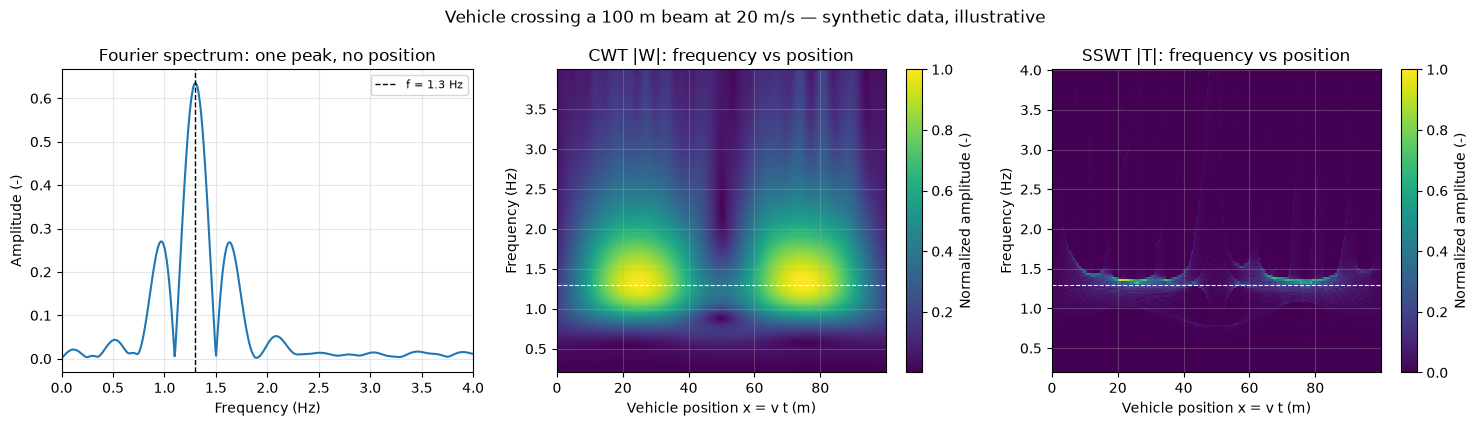

In [25]:
# Synthetic drive-by signal: vehicle crossing a 100 m simply supported beam
L = 100.0                               # span length, m
v = 20.0                                # vehicle speed, m/s
f_mode = 1.3                            # frequency of mode 2, Hz
fs = 100.0                              # sampling rate, Hz
noise_std = 0.1                         # noise standard deviation (-)

t = np.arange(0, L / v, 1 / fs)         # time, s
pos = v * t                             # vehicle position, m (x = v t)
phi_true = np.sin(2 * np.pi * pos / L)  # mode 2 shape
x = np.abs(phi_true) * np.cos(2 * np.pi * f_mode * t) + noise_std * rng.standard_normal(t.size)

# Fourier amplitude spectrum (zero-padded for a smooth curve)
n_fft = 2 ** 14
spec = np.abs(np.fft.rfft(x, n=n_fft)) * 2 / t.size
freqs_fft = np.fft.rfftfreq(n_fft, 1 / fs)

# CWT and SSWT with the analytic Morlet wavelet
wavelet = Wavelet(("morlet", {"mu": 3}))
Wx, scales_cwt = cwt(x, wavelet, fs=fs, nv=32, padtype="zero")
freqs_cwt = scale_to_freq(scales_cwt, wavelet, N=2 ** 14, fs=fs)   # Eq. 37 for this wavelet
Tx, _, freqs_ssq, _ = ssq_cwt(x, wavelet, fs=fs, nv=32, padtype="zero")

f_max = 4.0                             # upper frequency shown, Hz
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
axes[0].plot(freqs_fft, spec, color="C0")
axes[0].axvline(f_mode, color="k", ls="--", lw=1, label=f"f = {f_mode} Hz")
axes[0].set_xlim(0, f_max)
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Amplitude (-)")
axes[0].set_title("Fourier spectrum: one peak, no position")
axes[0].legend(fontsize=8)

for ax, Z, fr, name in [(axes[1], Wx, freqs_cwt, "CWT |W|"), (axes[2], Tx, freqs_ssq, "SSWT |T|")]:
    A = np.abs(Z) / np.abs(Z).max()     # normalized amplitude
    keep = fr <= f_max
    mesh = ax.pcolormesh(pos, fr[keep], A[keep], shading="auto", cmap="viridis")
    ax.axhline(f_mode, color="w", ls="--", lw=0.8)
    ax.set_xlabel("Vehicle position x = v t (m)")
    ax.set_ylabel("Frequency (Hz)")
    ax.set_title(f"{name}: frequency vs position")
    fig.colorbar(mesh, ax=ax, label="Normalized amplitude (-)")
fig.suptitle("Vehicle crossing a 100 m beam at 20 m/s — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 24.** Señal sintética de un carro que cruza una viga de 100 m (ilustrativo): el espectro de Fourier (izquierda) solo muestra un pico cerca de 1.3 Hz, sin decir dónde está; la CWT (centro) muestra esa frecuencia a lo largo de la posición, pero en una franja ancha; la SSWT (derecha) la concentra en una línea delgada y se ve dónde la amplitud crece o cae a cero.

- En los dos mapas la amplitud baja casi a cero en $x \approx 50$ m: ahí está el nodo del segundo modo.
- Fourier no puede mostrarlo porque promedia toda la señal; la wavelet sí, porque mira la señal por ventanas.
- La línea de la SSWT queda ligeramente por encima de 1.3 Hz (≈ 1.35 Hz); por eso, para la forma modal se promedia una banda alrededor de la frecuencia y no una sola fila del mapa.

**Cómo se usa para la forma modal**

- Con el **GPS** se cambia el tiempo por la posición del carro: $x = v\,t$ si la velocidad es constante; en general, la posición GPS en cada instante.
- Se toma la **franja de la frecuencia del modo** (aquí $1.3 \pm 0.3$ Hz) y se promedia su amplitud a lo largo del puente. La curva resultante, normalizada a máximo 1, es la forma modal estimada.

RMS error vs |phi|: 0.053
RMS error vs phi (with sign): 0.981


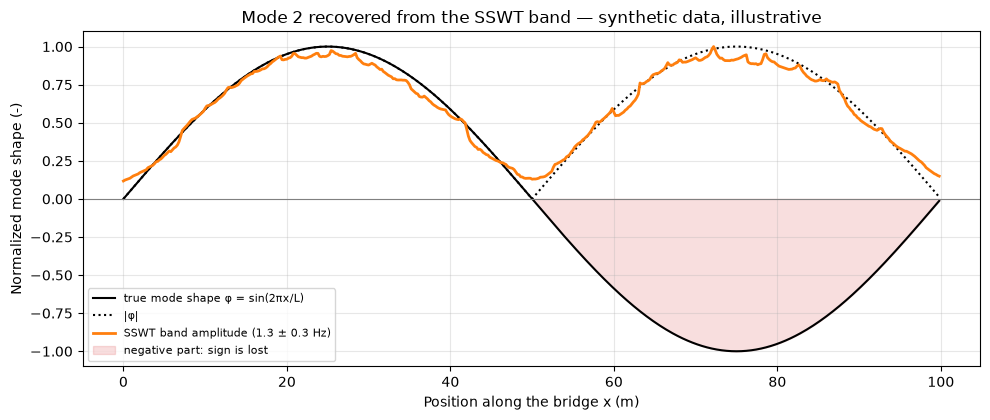

In [26]:
# Mode shape from the SSWT: mean amplitude in the band around the mode frequency
half_band = 0.3                         # half width of the frequency band, Hz
band = np.abs(freqs_ssq - f_mode) <= half_band
amp_band = np.abs(Tx[band]).mean(axis=0)
phi_est = amp_band / amp_band.max()     # normalized to max = 1

rms_abs = np.sqrt(np.mean((phi_est - np.abs(phi_true)) ** 2))
rms_signed = np.sqrt(np.mean((phi_est - phi_true) ** 2))
print(f"RMS error vs |phi|: {rms_abs:.3f}")
print(f"RMS error vs phi (with sign): {rms_signed:.3f}")

fig, ax = plt.subplots(figsize=(10, 4.3))
ax.plot(pos, phi_true, "k-", lw=1.5, label="true mode shape φ = sin(2πx/L)")
ax.plot(pos, np.abs(phi_true), "k:", lw=1.5, label="|φ|")
ax.plot(pos, phi_est, color="C1", lw=2, label=f"SSWT band amplitude ({f_mode} ± {half_band} Hz)")
ax.fill_between(pos, phi_true, 0, where=phi_true < 0, color="C3", alpha=0.15,
                label="negative part: sign is lost")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xlabel("Position along the bridge x (m)")
ax.set_ylabel("Normalized mode shape (-)")
ax.set_title("Mode 2 recovered from the SSWT band — synthetic data, illustrative")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

**Figura 25.** Amplitud promedio de la SSWT en la banda de 1.3 Hz a lo largo de la posición, comparada con la forma modal verdadera (ilustrativo, datos sintéticos): la curva sigue a $|\phi|$, pero en el tramo de 50 a 100 m, donde la forma real es negativa, sale positiva. Se recupera la forma en valor absoluto y se pierde el signo.

- El error RMS respecto a $|\phi|$ es pequeño; respecto a $\phi$ con signo es grande, porque todo el tramo negativo sale reflejado hacia arriba.
- Para recuperar el signo hace falta otra información (por ejemplo, la fase); la amplitud por sí sola no la tiene.

**Ventajas**

- Funciona con señales cortas y no estacionarias.
- Da frecuencia y posición a la vez.

**Desventajas**

- Para formas modales hay que conocer de antemano la frecuencia del modo.
- La amplitud no tiene signo: la forma modal sale en valor absoluto.
- No separa la respuesta del puente de la del vehículo.

**Artículos:** Dabbaghchian et al. (2025).

> **Nota de fuentes.** La explicación general de cómo funciona la wavelet es conocimiento general, no del artículo. Del artículo vienen: el uso de la SSWT con wavelet madre Morlet analítica y los límites para formas modales (frecuencia conocida de antemano, forma modal absoluta).

**Entradas y salidas**

- **Entrada:**
  - Una señal de aceleración contra tiempo, de un solo canal (vertical u horizontal), con su frecuencia de muestreo.
  - La wavelet madre escogida (por ejemplo, Morlet).
  - Para formas modales, además: la posición del vehículo en cada instante (GPS) y la frecuencia del modo, conocida de antemano.
- **Salida:**
  - Un mapa tiempo-frecuencia de coeficientes complejos $W(a,b)$; su magnitud $|W|$ es la amplitud de cada celda.
  - Con el GPS, el mismo mapa en función de la posición sobre el puente.
- **Qué se obtiene o interpreta:**
  - Qué frecuencias tiene la señal y en qué momento aparecen.
  - Cómo cambia la amplitud de una frecuencia a lo largo del recorrido.
  - Tomando la franja de la frecuencia del modo y promediando muchos viajes, la forma modal en valor absoluto (sin signo).

[↑ Volver al índice](#indice)

<a id="mode-shapes-bridge-components"></a>
#### 2.2.3 Bridge components

<a id="imf-exciter-frequency"></a>
##### 2.2.3.1 IMF near the exciter frequency

Se explica en EMD + Hilbert, [2.2.2.1](#emd-hilbert), "Cómo se usa para la forma modal".

<a id="peaks-first-singular-value-shapes"></a>
##### 2.2.3.2 Peaks of 1st singular value

Se explica dentro del FDD, [2.1.1.3](#fdd), paso 4.

<a id="band-known-frequency"></a>
##### 2.2.3.3 Band at the known frequency

**Qué es**

- Toma, del mapa tiempo-frecuencia de la wavelet, solo una franja estrecha alrededor de la frecuencia del modo y promedia su amplitud en ventanas a lo largo del puente.

**Para qué se aplica**

- Para quedarse con la parte de la señal que corresponde a un modo y obtener su amplitud en cada tramo del puente.

**Cómo funciona**

1. Se tiene el mapa de la wavelet en función de la posición ([2.2.2.3](#wavelet-sswt)).
2. Se fija la frecuencia del modo, conocida de antemano.
3. Se toman solo las filas del mapa dentro de una banda estrecha alrededor de esa frecuencia.
4. Se recorre el puente con una ventana que avanza en pasos fijos y, en cada posición, se promedia la magnitud de esas celdas.
5. Resultado: un vector de amplitudes a lo largo del puente por cada viaje.

$$B_{ij}=\operatorname{mean}\left\{\,|W(f,x)|\;:\;|f-f_m|\le\tfrac{b}{2},\;|x-x_j|\le\tfrac{\Delta}{2}\right\} \tag{41}$$

- $B_{ij}$: amplitud promedio en el segmento $j$ del viaje $i$.
- $W(f,x)$: coeficientes de la wavelet en la frecuencia $f$ y la posición $x$.
- $f_m$: frecuencia del modo.
- $b$: ancho de banda.
- $x_j$: centro del segmento $j$.
- $\Delta$: ancho de la ventana.

En palabras: es el promedio de la magnitud del mapa dentro de un rectángulo: una franja delgada de frecuencias alrededor del modo por un tramo del puente de ancho $\Delta$. Al mover el rectángulo a lo largo del puente sale una amplitud por tramo.

**Ejemplo sintético.** Un vehículo cruza a 15 m/s un puente de 272 m (la longitud del viaducto de Cadore) que vibra en un modo de 1.29 Hz con forma $|\sin(2\pi x/L)|$ (forma inventada, no la del viaducto), más una vibración del vehículo de 2.6 Hz y ruido. Banda de 2.2 % de 1.29 Hz (1.276 a 1.304 Hz), ventana de 24 m con paso de 1 m. SSWT con Morlet analítica ($\omega_0=6$) y 64 escalas por octava, para tener varias filas dentro de una banda tan estrecha.

Band 1.276-1.304 Hz: 3 rows of the SSWT map
249 window positions from 12 m to 260 m


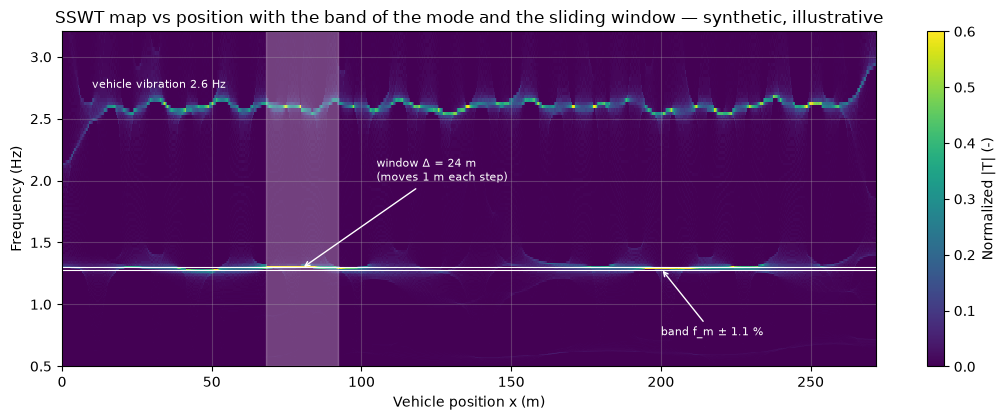

In [27]:
# Band at the known frequency: SSWT map vs position, narrow band and sliding window (illustrative)
rng_bd = np.random.default_rng(SEED + 15)
L_bd, v_bd, fs_bd = 272.0, 15.0, 50.0           # bridge length (m), speed (m/s), sampling (Hz)
f_m, b_rel = 1.29, 0.022                         # mode frequency (Hz) and band width (2.2 % of f_m)
win_bd, step_bd = 24.0, 1.0                      # window width and step, m
t_bd = np.arange(0, L_bd / v_bd, 1 / fs_bd)
pos_bd = v_bd * t_bd
shape_bd = np.abs(np.sin(2 * np.pi * pos_bd / L_bd))   # |phi| (made-up shape)
x_bd = (shape_bd * np.cos(2 * np.pi * f_m * t_bd) + 0.6 * np.sin(2 * np.pi * 2.6 * t_bd)
        + 0.3 * rng_bd.standard_normal(t_bd.size))

Tx_bd, _, fr_bd, _ = ssq_cwt(x_bd, Wavelet(("morlet", {"mu": 6})), fs=fs_bd, nv=64, padtype="reflect")
in_band = np.abs(fr_bd - f_m) <= b_rel * f_m / 2              # rows inside the band
amp_bd = np.abs(Tx_bd[in_band]).mean(axis=0)                  # band amplitude at each position
x_centers = np.arange(win_bd / 2, L_bd - win_bd / 2 + step_bd, step_bd)
B_bd = np.array([amp_bd[np.abs(pos_bd - xc) <= win_bd / 2].mean() for xc in x_centers])   # Eq. 41
print(f"Band {f_m * (1 - b_rel / 2):.3f}-{f_m * (1 + b_rel / 2):.3f} Hz: {in_band.sum()} rows of the SSWT map")
print(f"{x_centers.size} window positions from {x_centers[0]:.0f} m to {x_centers[-1]:.0f} m")

fig, ax = plt.subplots(figsize=(11, 4.3))
keep = (fr_bd >= 0.5) & (fr_bd <= 3.2)
A_bd = np.abs(Tx_bd) / np.abs(Tx_bd).max()
mesh = ax.pcolormesh(pos_bd, fr_bd[keep], A_bd[keep], shading="auto", cmap="viridis", vmax=0.6)
for fb in [f_m * (1 - b_rel / 2), f_m * (1 + b_rel / 2)]:
    ax.axhline(fb, color="w", lw=0.8)
x_demo = 80.0
ax.axvspan(x_demo - win_bd / 2, x_demo + win_bd / 2, color="w", alpha=0.25)
ax.annotate("window Δ = 24 m\n(moves 1 m each step)", (x_demo, f_m), xytext=(x_demo + 25, 2.0), color="w",
            fontsize=8, arrowprops=dict(arrowstyle="->", color="w"))
ax.annotate("band f_m ± 1.1 %", (200, f_m), xytext=(200, 0.75), color="w", fontsize=8,
            arrowprops=dict(arrowstyle="->", color="w"))
ax.text(10, 2.75, "vehicle vibration 2.6 Hz", color="w", fontsize=8)
ax.set_xlabel("Vehicle position x (m)")
ax.set_ylabel("Frequency (Hz)")
ax.set_title("SSWT map vs position with the band of the mode and the sliding window — synthetic, illustrative")
fig.colorbar(mesh, ax=ax, label="Normalized |T| (-)")
fig.tight_layout()
plt.show()

**Figura 26.** Mapa SSWT contra la posición de un viaje sintético (ilustrativo): la línea de 1.29 Hz es el modo del puente y la de 2.6 Hz es la vibración del vehículo. Las dos líneas blancas delimitan la banda de 2.2 %, tan estrecha que casi se juntan; la franja clara es la ventana de 24 m, que se desplaza de metro en metro.

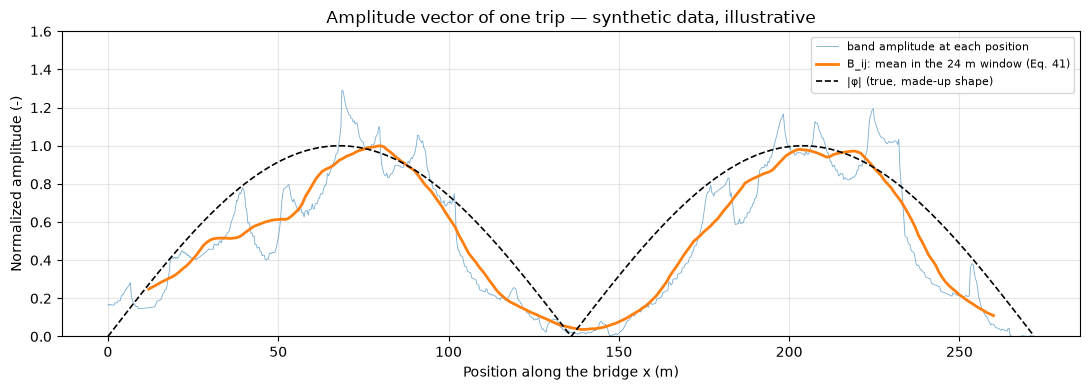

RMS error of B (normalized to max 1) vs |phi|: 0.18


In [28]:
# Amplitude vector along the bridge for this trip (illustrative)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(pos_bd, amp_bd / B_bd.max(), color="C0", lw=0.6, alpha=0.6, label="band amplitude at each position")
ax.plot(x_centers, B_bd / B_bd.max(), color="C1", lw=2, label="B_ij: mean in the 24 m window (Eq. 41)")
ax.plot(pos_bd, shape_bd, "k--", lw=1.2, label="|φ| (true, made-up shape)")
ax.set_xlabel("Position along the bridge x (m)")
ax.set_ylabel("Normalized amplitude (-)")
ax.set_ylim(0, 1.6)
ax.set_title("Amplitude vector of one trip — synthetic data, illustrative")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()
rms_bd = np.sqrt(np.mean((B_bd / B_bd.max() - np.abs(np.sin(2 * np.pi * x_centers / L_bd))) ** 2))
print(f"RMS error of B (normalized to max 1) vs |phi|: {rms_bd:.2f}")

**Figura 27.** Vector de amplitudes de un solo viaje contra la posición (ilustrativo, datos sintéticos): la amplitud de la banda (azul) tiene picos y huecos, porque en una banda tan estrecha la energía de la SSWT salta entre filas vecinas. La ventana de 24 m (naranja) la suaviza y deja ver los dos lóbulos de $|\phi|$, pero con errores de forma. Un viaje no basta: por eso se promedian muchos ([2.2.4.4](#average-many-trips)).

**Cómo se usa en drive-by** (referencia: Dabbaghchian et al., 2025)

- Frecuencia del modo 1.29 Hz (segundo modo transversal del viaducto de Cadore), banda de 2.2 % de esa frecuencia, ventana de 24 m que avanza 1 m.

**Ventajas**

- Simple: es un recorte y un promedio.
- La ventana suaviza el error del GPS (4 a 7 m).

**Desventajas**

- Hay que conocer la frecuencia del modo.
- Cualquier vibración del vehículo o del pavimento dentro de la banda se toma como del puente.
- La amplitud no tiene signo.

**Artículos:** Dabbaghchian et al. (2025).

> **Nota de fuentes.** Del artículo vienen: la ec. 2, 1.29 Hz, la banda de 2.2 %, la ventana de 24 m con paso de 1 m y el error del GPS. El rango aproximado de 1.276 a 1.304 Hz es un cálculo propio.

**Entradas y salidas**

- **Entrada:** el mapa wavelet en función de la posición, la frecuencia del modo, el ancho de banda y el tamaño y paso de la ventana.
- **Salida:** un vector de amplitudes a lo largo del puente, por viaje.
- **Qué se obtiene o interpreta:** cuánto vibra el modo en cada tramo del puente durante ese viaje.

[↑ Volver al índice](#indice)

<a id="build-shape"></a>
#### 2.2.4 Build the shape along the bridge

<a id="rescaling-between-axles"></a>
##### 2.2.4.1 Rescaling between axles

**Qué es**

- Construye la forma modal global a partir de las amplitudes medidas por dos sensores móviles que van a una distancia fija entre sí, encadenando sus cocientes paso a paso.

**Para qué se aplica**

- La amplitud medida en cada instante depende de la forma modal y de cuánto vibra el puente en ese momento. El cociente entre dos sensores medidos al mismo tiempo elimina lo segundo y deja la relación de la forma modal entre dos puntos.

**Cómo funciona**

1. Los dos ejes (sensores) van separados una distancia fija; en el mismo instante miden dos puntos distintos del puente.
2. El cociente de sus amplitudes da la relación de la forma modal entre esos dos puntos.
3. Se fija el valor en el primer punto y se encadenan los cocientes: el valor en cada punto nuevo se obtiene del anterior.
4. Repitiendo desde distintos puntos de inicio se obtiene una forma modal de alta resolución.

*Un paso del reescalado* (ec. 7 del artículo).

$$\phi_3=\phi_2\,\frac{\psi_{13}}{\psi_{22}} \tag{42}$$

- $\phi_j$: forma modal global en $x=j$ m.
- $\psi_{ij}$: amplitud local medida en el eje $i$ ($i=1$: eje 6; $i=2$: eje 7) en $x=j$ m.
- $\psi_{13}$ y $\psi_{22}$ se miden en el mismo instante: el eje 6 está en $x=3$ m y el eje 7, un metro atrás, en $x=2$ m.

En palabras: en un mismo instante los dos ejes ven la misma intensidad de vibración del puente; su cociente es la relación de la forma modal entre $x=3$ y $x=2$. Multiplicándolo por el valor ya conocido en 2 m se obtiene el de 3 m.

*Forma general.*

$$\phi_{j+1}=\phi_j\,\frac{\psi_{1,j+1}}{\psi_{2,j}} \tag{43}$$

- $j$: posición en m del eje trasero (eje 7) en ese instante; el eje delantero (eje 6) está en $j+1$.

En palabras: cada punto nuevo se obtiene del anterior con un cociente medido en el instante en que los ejes están en $j$ y $j+1$; se empieza con $\phi_1=\psi_{21}$ y $\phi_2=\psi_{12}$, medidos en el mismo instante.

**Ejemplo sintético.** Dos sensores separados 1 m cruzan a 2 m/s una viga de 15 m (modo 1, $\phi=\sin(\pi x/L)$). La intensidad de la vibración del puente cambia durante el cruce: $A(t)=1+0.8\sin(2\pi t/9)$. Cada sensor mide $\psi(t)=A(t)\,|\phi(x(t))|$ (amplitudes como las que da la HHT, ya suavizadas).

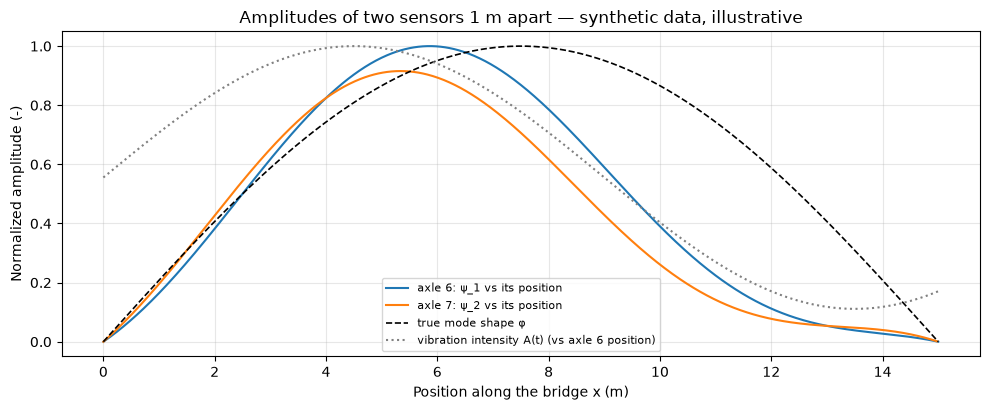

In [29]:
# Rescaling between two sensors 1 m apart: raw amplitudes (illustrative)
L_rs, v_rs, fs_rs = 15.0, 2.0, 100.0
t_rs = np.arange(0, (L_rs + 1) / v_rs, 1 / fs_rs)
x6 = v_rs * t_rs                                 # axle 6 (front sensor) position, m
x7 = x6 - 1.0                                    # axle 7 (rear sensor), 1 m behind
A_rs = 1 + 0.8 * np.sin(2 * np.pi * t_rs / 9)     # vibration intensity changing in time
phi_rs = lambda x: np.sin(np.pi * np.clip(x, 0, L_rs) / L_rs)
psi1 = A_rs * np.abs(phi_rs(x6))                 # amplitude measured on axle 6
psi2 = A_rs * np.abs(phi_rs(x7))                 # amplitude measured on axle 7
on6 = (x6 >= 0) & (x6 <= L_rs)
on7 = (x7 >= 0) & (x7 <= L_rs)

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(x6[on6], psi1[on6] / psi1.max(), color="C0", label="axle 6: ψ_1 vs its position")
ax.plot(x7[on7], psi2[on7] / psi1.max(), color="C1", label="axle 7: ψ_2 vs its position")
ax.plot(x6[on6], phi_rs(x6[on6]), "k--", lw=1.2, label="true mode shape φ")
ax.plot(x6[on6], A_rs[on6] / A_rs.max(), ":", color="0.5", label="vibration intensity A(t) (vs axle 6 position)")
ax.set_xlabel("Position along the bridge x (m)")
ax.set_ylabel("Normalized amplitude (-)")
ax.set_title("Amplitudes of two sensors 1 m apart — synthetic data, illustrative")
ax.legend(loc="lower center", fontsize=8)
fig.tight_layout()
plt.show()

**Figura 28.** Amplitudes de dos sensores separados 1 m contra su posición (ilustrativo, datos sintéticos): ninguna se parece a la forma modal (línea discontinua), porque cada una es la forma multiplicada por la intensidad de la vibración, que cambia durante el cruce (línea punteada). El máximo queda corrido hacia donde la intensidad era mayor y las dos curvas no coinciden entre sí.

Max error without noise: 1.1e-16
Relative spread of the 30 noisy reconstructions at x = 2, 5, 10, 14 m (%): [ 4.   8.2 14.1 14.6]


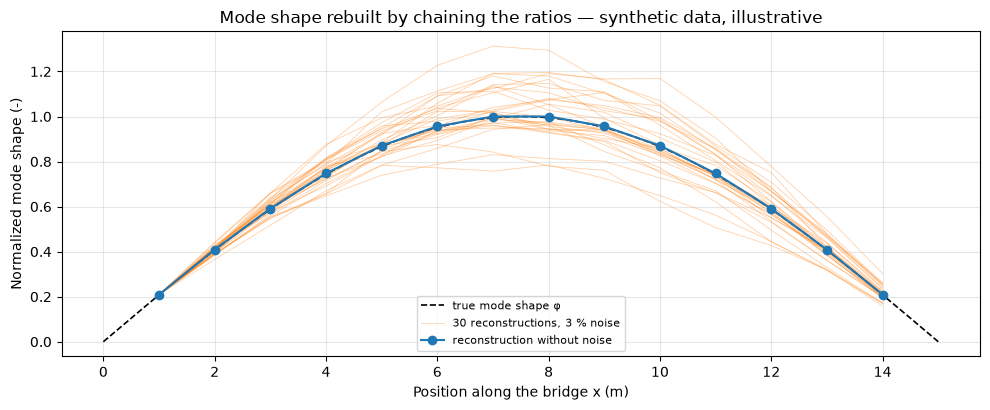

In [30]:
# Reconstruction by chaining the ratios (Eq. 43), without and with 3 % noise in the amplitudes
j_rs = np.arange(1, 15)                                       # x = 1, 2, ..., 14 m

def rescale(p1, p2):
    """Chain the ratios: phi_1 = psi_21, phi_2 = psi_12, phi_{j+1} = phi_j psi_{1,j+1} / psi_{2,j}."""
    idx = [np.argmin(np.abs(x7 - j)) for j in j_rs]          # instant when axle 7 is at x = j
    ph = [p2[idx[0]], p1[idx[0]]]
    for j in range(2, j_rs[-1]):
        i = idx[j - 1]                                        # axle 7 at j, axle 6 at j + 1
        ph.append(ph[-1] * p1[i] / p2[i])
    ph = np.array(ph)
    return ph * phi_ref[0] / ph[0]                            # start fixed at the true value at x = 1 m

phi_ref = phi_rs(j_rs) / phi_rs(j_rs).max()
phi_exact = rescale(psi1, psi2)
rng_rs = np.random.default_rng(SEED + 16)
noisy = [rescale(psi1 * (1 + 0.03 * rng_rs.standard_normal(t_rs.size)),
                 psi2 * (1 + 0.03 * rng_rs.standard_normal(t_rs.size))) for _ in range(30)]
noisy = np.array(noisy)
rel_spread = noisy.std(axis=0) / phi_ref                    # spread relative to the true value
print(f"Max error without noise: {np.abs(phi_exact - phi_ref).max():.1e}")
print("Relative spread of the 30 noisy reconstructions at x = 2, 5, 10, 14 m (%):",
      np.round(100 * rel_spread[[1, 4, 9, 13]], 1))

x_fine = np.linspace(0, L_rs, 300)
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(x_fine, phi_rs(x_fine), "k--", lw=1.2, label="true mode shape φ")
for k, ph in enumerate(noisy):
    ax.plot(j_rs, ph, color="C1", lw=0.6, alpha=0.35, label="30 reconstructions, 3 % noise" if k == 0 else None)
ax.plot(j_rs, phi_exact, "o-", color="C0", ms=6, label="reconstruction without noise")
ax.set_xlabel("Position along the bridge x (m)")
ax.set_ylabel("Normalized mode shape (-)")
ax.set_title("Mode shape rebuilt by chaining the ratios — synthetic data, illustrative")
ax.legend(loc="lower center", fontsize=8)
fig.tight_layout()
plt.show()

**Figura 29.** Forma modal reconstruida encadenando los cocientes (ilustrativo, datos sintéticos): sin ruido (azul) coincide con la verdadera en cada metro, aunque las amplitudes de la Figura 28 no se parecían a ella. Con 3 % de ruido en las amplitudes (naranja, 30 repeticiones), las curvas se abren a medida que se avanza por el puente: cada paso multiplica el error de los anteriores. Para ver esa acumulación, todas las reconstrucciones parten del valor verdadero en $x=1$ m.

- La dispersión relativa crece paso a paso (se imprime arriba de la figura). Cerca de $x=14$ m las curvas se juntan en valor absoluto solo porque ahí la forma es pequeña; en proporción, el error es el mayor.

**Cómo se usa en drive-by** (referencia: Malekjafarian y OBrien, 2017)

- Usan las amplitudes HHT de los ejes 6 y 7, separados 1 m, suavizadas y recortadas ([2.2.2.1](#emd-hilbert)).
- Arrancan en $x=1$ m y avanzan cada 1 m hasta 14 m.
- Para el modo 1, la excitación debía estar entre 5.4 y 5.8 Hz; fuera de ese rango, la forma modal no salía bien.
- Las amplitudes son todas positivas, así que para el modo 2 usaron juicio de ingeniería para darle el signo.

**Ventajas**

- No necesita sensores fijos de referencia; uno de los ejes hace de referencia del otro.
- Permite una forma modal de alta resolución.

**Desventajas**

- Los errores se acumulan al encadenar los cocientes.
- No da el signo.
- Necesita amplitudes de buena calidad en todo el puente.

**Artículos:** Malekjafarian y OBrien (2017).

> **Nota de fuentes.** Todo viene del artículo: ec. 7, ejes 6 y 7, 1 m de paso, rango de excitación de 5.4 a 5.8 Hz y el uso de juicio de ingeniería para el signo del modo 2. La observación sobre la acumulación de errores es propia.

**Entradas y salidas**

- **Entrada:** las amplitudes de dos sensores a distancia fija, contra la posición.
- **Salida:** la forma modal global en puntos espaciados.
- **Qué se obtiene o interpreta:** la forma modal a lo largo del puente, sin signo.

[↑ Volver al índice](#indice)

<a id="svd-completed-matrix"></a>
##### 2.2.4.2 SVD of the completed matrix

SVD: *Singular Value Decomposition*, descomposición en valores singulares.

**Qué es**

- La SVD descompone cualquier matriz en tres: direcciones en filas ($\mathbf{U}$), pesos ($\Sigma$) y direcciones en columnas ($\mathbf{V}$).
- Los valores singulares, ordenados de mayor a menor, dicen cuánto aporta cada componente.
- Está muy relacionada con el PCA (*Principal Component Analysis*, análisis de componentes principales): las columnas de $\mathbf{U}$ son las direcciones principales de los datos.

**Para qué se aplica**

- Para encontrar los patrones dominantes de una matriz y reducir el ruido quedándose con las primeras componentes.
- En el FDD, para separar los modos en cada frecuencia ([2.1.1.3](#fdd)).
- En *drive-by*: para extraer las formas modales de una matriz de respuesta espacio–tiempo.

**Cómo funciona**

1. Se arma la matriz de datos: una fila por punto del puente y una columna por instante de tiempo.
2. Se aplica la SVD: $\mathbf{D}=\mathbf{U}\Sigma\mathbf{V}^{T}$.
3. Cada columna de $\mathbf{U}$ es un patrón espacial (en un puente, una forma a lo largo de los puntos); cada fila de $\mathbf{V}^{T}$ es cómo varía ese patrón en el tiempo; $\sigma_i$ es su peso.
4. Como la respuesta del puente es una suma de modos, la matriz tiene rango bajo: unas pocas componentes explican casi todo.
5. Las primeras columnas de $\mathbf{U}$ se toman como formas modales.

*La descomposición (pasos 2–3).*

$$\mathbf{D}=\mathbf{U}\,\Sigma\,\mathbf{V}^{T}=\sum_{i=1}^{r}\sigma_i\,\mathbf{u}_i\,\mathbf{v}_i^{T} \tag{44}$$

- $\mathbf{D}$: matriz de datos ($n$ puntos × $N$ instantes).
- $\mathbf{U}$, $\mathbf{V}$: matrices ortogonales; sus columnas tienen norma 1 y son perpendiculares entre sí.
- $\Sigma$: matriz diagonal con los valores singulares $\sigma_1\ge\sigma_2\ge\dots\ge 0$.
- $r$: rango de $\mathbf{D}$ (número de valores singulares distintos de cero).
- $\mathbf{u}_i$: patrón espacial $i$ (columna $i$ de $\mathbf{U}$, $n$ valores).
- $\mathbf{v}_i$: variación en el tiempo del patrón $i$ (columna $i$ de $\mathbf{V}$, $N$ valores).

En palabras: la matriz es una suma de capas; cada capa es un patrón espacial multiplicado por su variación en el tiempo y por un peso $\sigma_i$, y las capas van de la más fuerte a la más débil.

*La respuesta del puente (paso 4).*

$$\mathbf{D}\approx\Phi\,\mathbf{Q} \tag{45}$$

- $\Phi$: formas modales ($n\times m$, una por columna).
- $\mathbf{Q}$: coordenadas modales en el tiempo ($m\times N$, una fila por modo).
- $m$: número de modos que responden.

En palabras: cada columna de $\mathbf{D}$ (la "foto" del puente en un instante) es una combinación de las mismas $m$ formas modales. Por eso $\mathbf{D}$ tiene rango cercano a $m$, aunque tenga cientos de columnas. Si las formas modales son ortogonales y las coordenadas modales no están correlacionadas y tienen energías distintas, las columnas de $\mathbf{U}$ coinciden con las formas modales normalizadas.

**Ejemplo sintético.** Matriz de 10 puntos × 677 instantes (el tamaño que usa Mei et al., 2021) de una viga simplemente apoyada con tres modos ($\sin(k\pi x/L)$; 1.44, 3.68 y 4.66 Hz como ejemplo; amplitudes 1, 0.5 y 0.25), muestreada a 100 Hz, más ruido. La matriz está completa: el ejemplo no simula el *soft imputing*.

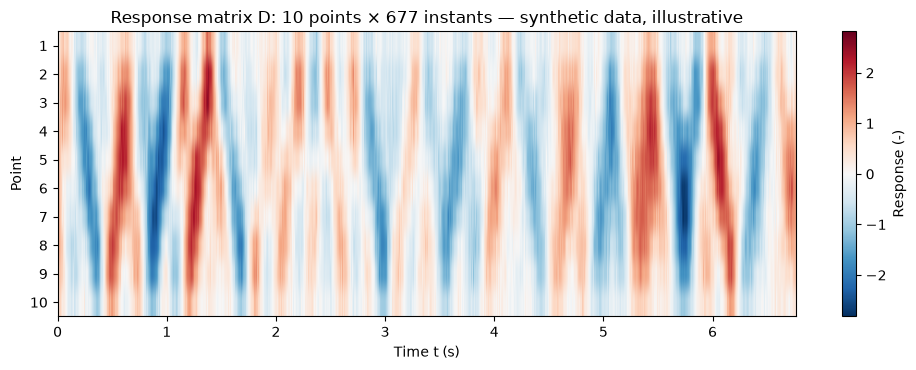

In [31]:
# Synthetic 10 x 677 response matrix: beam with 3 modes plus noise (illustrative)
rng_svd = np.random.default_rng(SEED + 4)
fs_d = 100.0                                   # sampling rate, Hz
n_t = 677                                      # time samples (same size as Mei et al., 2021)
x_d = np.arange(1, 11) / 11                    # 10 equally spaced points, x/L
Phi_d = beam_modes(x_d, 3)                     # true mode shapes, 10 x 3
Q_d = modal_response(f_true, 0.02, fs_d, n_t, rng_svd) * np.array([[1.0], [0.5], [0.25]])
D_clean = Phi_d @ Q_d                          # Eq. 45: D = Phi Q
D_mat = D_clean + 0.1 * rng_svd.standard_normal(D_clean.shape)
t_d = np.arange(n_t) / fs_d

fig, ax = plt.subplots(figsize=(10, 3.8))
vmax = np.abs(D_mat).max()
im = ax.imshow(D_mat, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax,
               extent=[t_d[0], t_d[-1], 10.5, 0.5])
ax.set_yticks(range(1, 11))
ax.set_xlabel("Time t (s)")
ax.set_ylabel("Point")
ax.set_title("Response matrix D: 10 points × 677 instants — synthetic data, illustrative")
ax.grid(False)
fig.colorbar(im, ax=ax, label="Response (-)")
fig.tight_layout()
plt.show()

**Figura 30.** Matriz sintética de 10 puntos × 677 instantes (ilustrativo): cada fila es la respuesta de un punto y cada columna es la "foto" del puente en un instante. Las franjas inclinadas muestran que los puntos no se mueven todos a la vez: es la mezcla de los tres modos. El ruido casi no se ve, porque es pequeño frente a la respuesta.

*Aproximación de rango $k$.*

$$\mathbf{D}_k=\sum_{i=1}^{k}\sigma_i\,\mathbf{u}_i\,\mathbf{v}_i^{T} \tag{46}$$

- $\mathbf{D}_k$: matriz reconstruida solo con las primeras $k$ componentes.
- $k$: número de componentes que se conservan.
- $\sigma_i$, $\mathbf{u}_i$, $\mathbf{v}_i$: como en la Ec. 44.

En palabras: con $k$ igual al número de modos se conserva la respuesta y se descarta el ruido, que queda repartido en las componentes pequeñas.

Singular values: [60.9 30.6 15.4  2.7  2.6  2.6  2.5  2.5  2.5  2.4]
Energy in the first 3 components: 99.1 %
Relative error vs the noise-free matrix: D 11.7 %, D_3 6.6 %


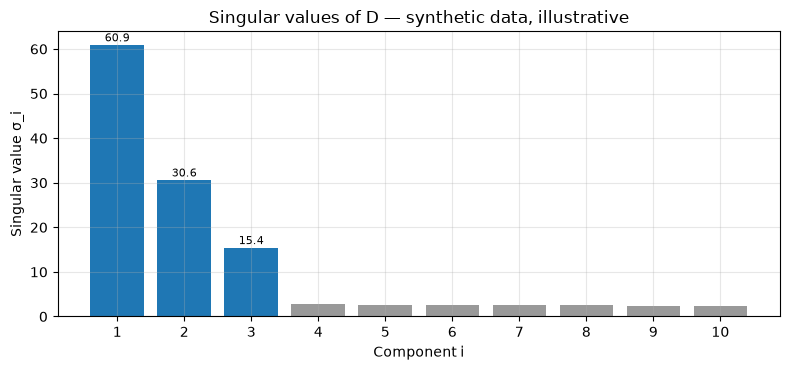

In [32]:
# Singular values of D: three large ones (the modes) and the rest small (noise)
U_d, s_d, Vt_d = np.linalg.svd(D_mat, full_matrices=False)     # Eq. 44
D_3 = (U_d[:, :3] * s_d[:3]) @ Vt_d[:3]                         # Eq. 46 with k = 3
energy_3 = np.sum(s_d[:3] ** 2) / np.sum(s_d ** 2)
err_raw = np.linalg.norm(D_mat - D_clean) / np.linalg.norm(D_clean)
err_3 = np.linalg.norm(D_3 - D_clean) / np.linalg.norm(D_clean)
print("Singular values:", np.round(s_d, 1))
print(f"Energy in the first 3 components: {100 * energy_3:.1f} %")
print(f"Relative error vs the noise-free matrix: D {100 * err_raw:.1f} %, D_3 {100 * err_3:.1f} %")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(np.arange(1, 11), s_d, color=["C0"] * 3 + ["0.6"] * 7)
for i, s in enumerate(s_d[:3]):
    ax.text(i + 1, s + 0.8, f"{s:.1f}", ha="center", fontsize=8)
ax.set_xticks(np.arange(1, 11))
ax.set_xlabel("Component i")
ax.set_ylabel("Singular value σ_i")
ax.set_title("Singular values of D — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 31.** Valores singulares de la matriz de la Figura 30 (ilustrativo, datos sintéticos): tres son grandes (los tres modos, en azul) y los otros siete son pequeños y parecidos entre sí (el ruido). El salto entre $\sigma_3$ y $\sigma_4$ dice cuántos modos hay.

- La reconstrucción con las tres primeras componentes (Ec. 46) se acerca más a la matriz sin ruido que la matriz medida: la SVD quita la mayor parte del ruido.

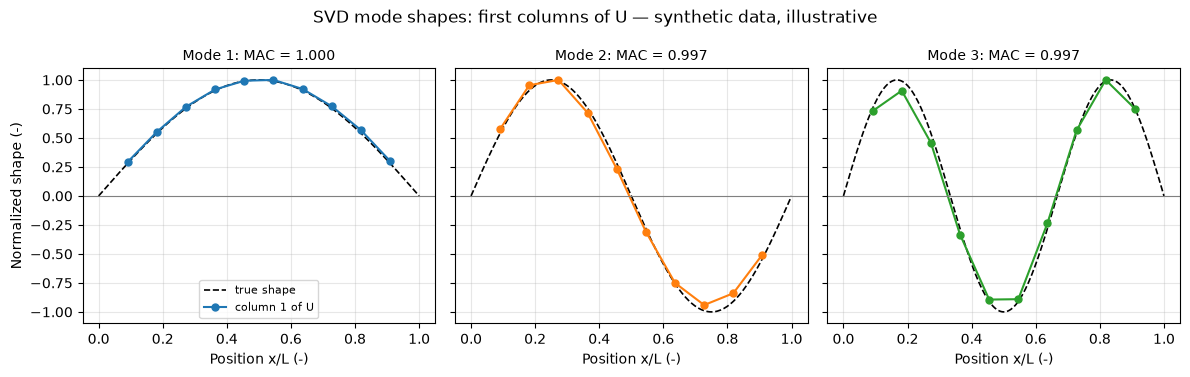

In [33]:
# First three columns of U vs the true mode shapes (illustrative)
x_fine = np.linspace(0, 1, 200)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for k, ax in enumerate(axes):
    u = U_d[:, k] / np.max(np.abs(U_d[:, k]))
    u = u if np.dot(u, Phi_d[:, k]) >= 0 else -u              # the sign of a singular vector is arbitrary
    ax.plot(x_fine, np.sin((k + 1) * np.pi * x_fine), "k--", lw=1.2, label="true shape")
    ax.plot(x_d, u, "o-", color=f"C{k}", ms=5, label=f"column {k + 1} of U")
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_title(f"Mode {k + 1}: MAC = {mac(Phi_d[:, k], U_d[:, k]):.3f}", fontsize=10)
    ax.set_xlabel("Position x/L (-)")
axes[0].set_ylabel("Normalized shape (-)")
axes[0].legend(loc="lower center", fontsize=8)
fig.suptitle("SVD mode shapes: first columns of U — synthetic data, illustrative")
fig.tight_layout()
plt.show()

**Figura 32.** Las tres primeras columnas de $\mathbf{U}$ comparadas con las formas modales verdaderas (ilustrativo, datos sintéticos): coinciden, con MAC cercano a 1. Se escalan a un máximo de 1 y se les ajusta el signo, porque la SVD da la forma pero no su tamaño ni su signo.

- En este ejemplo los senos son exactamente ortogonales en 10 puntos equiespaciados y los modos tienen energías muy distintas: es el caso favorable para la SVD.

**Cómo se usa en drive-by** (referencia: Mei et al., 2021)

- Arman la matriz de desplazamientos de 10 puntos fijos × tiempo ($10\times 677$), la completan con *soft imputing* ([2.2.1.2](#soft-imputing)) y le aplican la SVD.
- Las columnas de $\mathbf{U}$ dan las formas modales.
- Sin rugosidad y con 2 MMPs (*moving measurement points*, puntos de medición móviles), el MAC fue de 1.000 / 0.998 / 0.977 para los tres modos.

**Ventajas**

- Siempre existe, para cualquier matriz.
- Separa los patrones dominantes del ruido.
- No necesita conocer la excitación.

**Desventajas**

- Necesita la matriz completa (por eso Mei primero la rellena con *soft imputing*).
- Si dos modos tienen energía parecida, las componentes pueden mezclarlos.
- Las componentes son ortogonales; si las formas modales reales no lo son, no coinciden exactamente.
- No da frecuencias por sí sola; hay que analizar las filas de $\mathbf{V}^{T}$.

**Artículos:** Mei et al. (2021). También se usa dentro del FDD de Talebi-Kalaleh et al. (2025), en cada frecuencia.

> **Nota de fuentes.** La explicación general de la SVD y su relación con el PCA es conocimiento general. Del artículo de Mei vienen: la matriz 10 × 677, la SVD de la matriz completada con soft imputing y los valores de MAC.

**Entradas y salidas**

- **Entrada:** una matriz completa de puntos × tiempo (en Mei, desplazamientos completados con *soft imputing*).
- **Salida:** $\mathbf{U}$, $\Sigma$ y $\mathbf{V}$.
- **Qué se obtiene o interpreta:**
  - Los valores singulares dicen cuántos patrones dominan.
  - Las primeras columnas de $\mathbf{U}$ son las formas modales.
  - Las filas de $\mathbf{V}^{T}$ dicen cómo varía cada modo en el tiempo.

[↑ Volver al índice](#indice)

<a id="singular-vectors-peaks"></a>
##### 2.2.4.3 Singular vectors at peaks

Se explica dentro del FDD, [2.1.1.3](#fdd), paso 5.

<a id="average-many-trips"></a>
##### 2.2.4.4 Average of many trips

**Qué es**

- Obtiene la forma modal promediando, punto por punto, los vectores de amplitud de muchos viajes no sincronizados.

**Para qué se aplica**

- En un solo viaje con smartphone, la vibración del puente casi no se distingue del ruido. Al promediar muchos viajes, el ruido se compensa y aparece la forma.

**Cómo funciona**

1. Cada viaje da un vector de amplitudes a lo largo del puente ([2.2.3.3](#band-known-frequency)).
2. Se promedian todos los vectores punto por punto.
3. El resultado es la forma modal absoluta (sin signo).

$$\bar{B}_j=\frac{1}{N}\sum_{i=1}^{N}B_{ij} \tag{47}$$

- $\bar{B}_j$: forma modal absoluta en el segmento $j$.
- $B_{ij}$: amplitud del viaje $i$ en el segmento $j$ (Ec. 41).
- $N$: número de viajes.

En palabras: en cada tramo del puente se promedian las amplitudes de todos los viajes; el error de cada viaje es distinto y se compensa, y lo que todos tienen en común, la forma del modo, queda.

**Ejemplo sintético.** Vectores de 249 segmentos (de 12 a 260 m, cada 1 m) de un puente de 272 m. Para no calcular cientos de mapas wavelet, cada viaje se genera directamente: $B_{ij}=a_i\,|\phi(x_j)|+e_{ij}$, con $a_i$ la intensidad de vibración del viaje (al azar entre 0.5 y 1.5) y $e_{ij}$ un error suave a lo largo del puente, del mismo tamaño que la señal. El 25 % de los viajes es de baja calidad (error tres veces mayor). Es un modelo simplificado: el error de cada viaje tiene promedio cero.

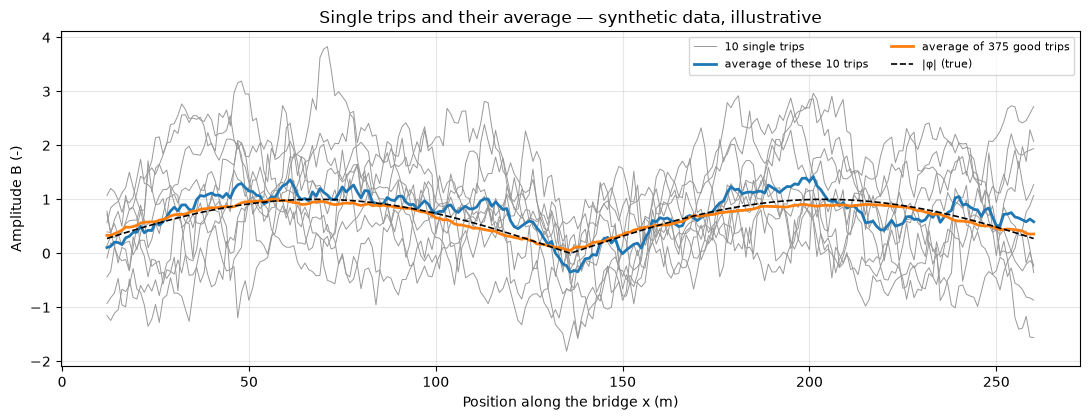

Shape error: one trip 0.87, 10 trips 0.25, 375 good trips 0.070


In [34]:
# Average of many trips: synthetic amplitude vectors (illustrative)
rng_av = np.random.default_rng(SEED + 17)
L_av = 272.0
xj_av = np.arange(12.0, 261.0, 1.0)              # segment centers, m
shape_av = np.abs(np.sin(2 * np.pi * xj_av / L_av))
n_trips = 500
kernel_av = np.ones(24) / 24                      # errors are smooth over a 24 m window

def smooth_noise(n, rng):
    """Error along the bridge, smoothed like the 24 m window and scaled to unit RMS."""
    e = np.convolve(rng.standard_normal(n + 23), kernel_av, mode="valid")
    return e / e.std()

a_av = rng_av.uniform(0.5, 1.5, n_trips)          # vibration intensity of each trip
bad = rng_av.random(n_trips) < 0.25               # low-quality trips
sigma_av = np.where(bad, 3.0, 1.0) * 0.8
B_trips = np.array([a * shape_av + s * smooth_noise(xj_av.size, rng_av) for a, s in zip(a_av, sigma_av)])

def shape_error(B_mean):
    """Relative error between the normalized average and the normalized |phi| (unit-norm vectors)."""
    return np.linalg.norm(B_mean / np.linalg.norm(B_mean) - shape_av / np.linalg.norm(shape_av))

good_idx = np.flatnonzero(~bad)
fig, ax = plt.subplots(figsize=(11, 4.3))
for k, i in enumerate(good_idx[:10]):
    ax.plot(xj_av, B_trips[i], color="0.6", lw=0.7, label="10 single trips" if k == 0 else None)
mean10 = B_trips[good_idx[:10]].mean(axis=0)
mean_good = B_trips[good_idx].mean(axis=0)
ax.plot(xj_av, mean10, color="C0", lw=2, label="average of these 10 trips")
ax.plot(xj_av, mean_good, color="C1", lw=2, label=f"average of {good_idx.size} good trips")
ax.plot(xj_av, shape_av, "k--", lw=1.2, label="|φ| (true)")
ax.set_xlabel("Position along the bridge x (m)")
ax.set_ylabel("Amplitude B (-)")
ax.set_title("Single trips and their average — synthetic data, illustrative")
ax.legend(loc="upper right", fontsize=8, ncol=2)
fig.tight_layout()
plt.show()
print(f"Shape error: one trip {shape_error(B_trips[good_idx[0]]):.2f}, 10 trips {shape_error(mean10):.2f}, "
      f"{good_idx.size} good trips {shape_error(mean_good):.3f}")

**Figura 33.** Diez viajes sintéticos individuales (gris) y su promedio (azul), comparados con $|\phi|$ (ilustrativo, datos sintéticos): cada viaje por separado apenas sugiere la forma; el promedio de diez ya muestra los dos lóbulos, y el de todos los viajes buenos (naranja) casi coincide con $|\phi|$, salvo la escala, que depende de la intensidad promedio de los viajes.

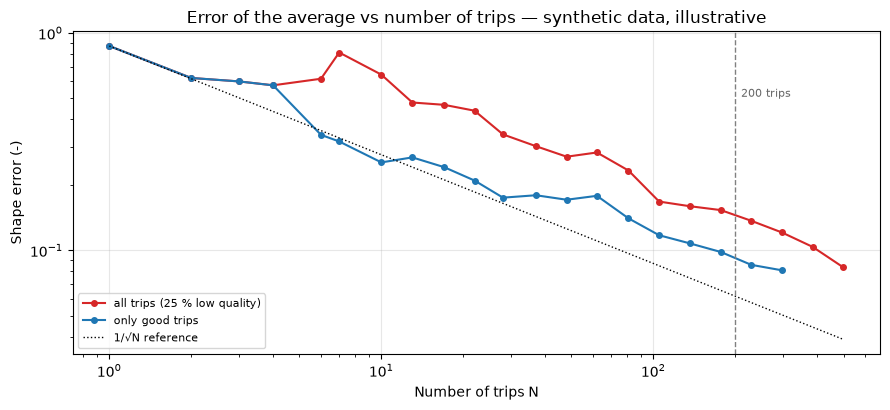

In [35]:
# Error of the average vs number of trips: all trips vs only the good ones (illustrative)
n_list = np.unique(np.logspace(0, np.log10(n_trips), 25).astype(int))
err_all = [shape_error(B_trips[:n].mean(axis=0)) for n in n_list]
n_good_list = n_list[n_list <= good_idx.size]
err_good = [shape_error(B_trips[good_idx[:n]].mean(axis=0)) for n in n_good_list]

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.loglog(n_list, err_all, "o-", color="C3", ms=4, label="all trips (25 % low quality)")
ax.loglog(n_good_list, err_good, "o-", color="C0", ms=4, label="only good trips")
ax.loglog(n_list, err_good[0] / np.sqrt(n_list), "k:", lw=1, label="1/√N reference")
ax.axvline(200, color="0.5", ls="--", lw=1)
ax.text(210, ax.get_ylim()[1] * 0.5, "200 trips", fontsize=8, color="0.4")
ax.set_xlabel("Number of trips N")
ax.set_ylabel("Shape error (-)")
ax.set_title("Error of the average vs number of trips — synthetic data, illustrative")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()
plt.show()

**Figura 34.** Error de la forma promediada contra el número de viajes (ilustrativo, datos sintéticos): el error baja más o menos como $1/\sqrt{N}$, la regla de un promedio de errores independientes. Con viajes de baja calidad mezclados (rojo) el error es mayor para el mismo número de viajes; quitarlos mejora el resultado, como en el artículo.

- En este modelo el error de cada viaje tiene promedio cero y el promedio converge a $|\phi|$. Con magnitudes reales, el ruido deja además un piso positivo que no desaparece al promediar (observación propia).

**Cómo se usa en drive-by** (referencia: Dabbaghchian et al., 2025)

- 909 viajes en el viaducto de Cadore (272 m).
- Con todos los viajes, MAC = 0.8; descartando los de baja calidad (707 mejores), MAC = 0.98.
- Se necesitan al menos 200 viajes.

**Ventajas**

- Los viajes no tienen que estar sincronizados; se pueden juntar viajes de días distintos.
- Funciona con datos reales de muchos usuarios.

**Desventajas**

- Necesita muchos viajes.
- La forma sale sin signo.
- Los viajes malos degradan el promedio; su filtro de calidad necesita una forma modal de referencia de sensores fijos.

**Artículos:** Dabbaghchian et al. (2025).

> **Nota de fuentes.** Del artículo vienen: la ec. 3, los 909 viajes, el MAC de 0.8 y 0.98, los 707 viajes, el mínimo de 200 viajes y la necesidad de una referencia para el filtro de calidad.

**Entradas y salidas**

- **Entrada:** los vectores de amplitud de muchos viajes sobre el mismo puente.
- **Salida:** un vector promedio a lo largo del puente.
- **Qué se obtiene o interpreta:** la forma modal absoluta del puente.

[↑ Volver al índice](#indice)